# Регіональні моделі ВВП за нічними вогнями: прогноз на новий період

Вибірка ділиться на чотири підвибірки за регіонами ООН (Західна, Східна, Південна, Північна Європа). У кожній підвибірці **усі країни присутні** в Train, Validation і Test, а поділ іде **за роками**: Train — найраніші роки, Validation — наступні, Test — останні. Тобто модель прогнозує ВВП тих самих країн на новий період.

**Протокол для кожного регіону**

1. Кореляційний відбір світлових ознак, scaler і PCA навчаються **лише на Train**.
2. Моделі навчаються на Train у трьох наборах ознак (PCA за некорельованими ознаками; вибрані кореляційним аналізом ознаки без PCA; усі ознаки — лише для моделей, що витримують кореляцію) і оцінюються на Validation.
3. Для `TOP_K` найкращих моделей виконується tuning (`RandomizedSearchCV`, rolling-origin CV за роками всередині Train); у кожному наборі ознак обирається найкраща за Validation RMSE модель (default або tuned).
4. Найкраща модель кожного набору перенавчається на Train+Validation і **один раз** оцінюється на Test.

Протокол виконується у двох специфікаціях: **лише світло** і **світло + додатковізмінні** (ln населення, широта, ln площі).

## 0. Налаштування і параметри

Імпорти, шляхи і всі параметри ноутбука в одному місці:

- `CORR_THRESHOLD`, `PRIORITY_FEATURE`, `PCA_VARIANCE` — кореляційний відбір ознак і PCA;
- `TARGET`, `N_VAL_YEARS`, `N_TEST_YEARS` — ціль і поділ років на Train / Validation / Test;
- `TOP_K`, `N_ITER` — скільки найкращих моделей тюнити і скільки комбінацій параметрів перебирати;
- `FS_PCA`, `FS_SEL`, `FS_ALL` — назви трьох наборів ознак;
- `ROLE_COLOR`, `SET_COLOR`, `SET_SLUG` — кольори вибірок і наборів ознак та короткі назви наборів для файлів.

`save_show` — зберігає рисунок у `FIGURES_DIR` і показує його (або закриває, якщо `SHOW_PLOTS = False`).

In [1]:
import importlib
import math
import os
import re
import subprocess
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from scipy.stats import loguniform, pearsonr, randint, spearmanr, uniform
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.ensemble import AdaBoostRegressor, GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

try:
    from IPython.display import display
except ImportError:
    display = print
try:
    from xgboost import XGBRegressor
except Exception:
    XGBRegressor = None
try:
    from lightgbm import LGBMRegressor
except Exception:
    LGBMRegressor = None

warnings.filterwarnings("ignore")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/GDP_NTL_Project")
except ImportError:
    PROJECT_ROOT = Path(os.environ.get("PROJECT_ROOT", "."))

PANEL_PATH = PROJECT_ROOT / "data" / "processed" / "gdp_ntl_panel_2012_2025.csv"
CONTROLS_PATH = PROJECT_ROOT / "data" / "processed" / "controls_population_latitude.csv"
STUDY_AREA_PATH = PROJECT_ROOT / "data" / "metadata" / "study_area.geojson"
RESULTS_DIR = PROJECT_ROOT / "results" / "regional"
TABLES_DIR, FIGURES_DIR = RESULTS_DIR / "tables", RESULTS_DIR / "figures"
for p in (TABLES_DIR, FIGURES_DIR):
    p.mkdir(parents=True, exist_ok=True)

# ---------------- параметри ----------------
SEED = 42
CORR_THRESHOLD = 0.80                       # поріг кореляційного відбору ознак світла
PRIORITY_FEATURE = "ntl_sum_area_weighted"  # ознака, що завжди лишається
PCA_VARIANCE = 0.90                         # частка дисперсії для PCA
INCLUDE_AREA = False                        # True: додати площу total_mask_km2 до ознак світла
MAX_INNER_FOLDS = 5                         # фолдів GroupKFold (за країнами) для підбору alpha у Ridge
RF_TREES = 200                              # дерев у Random Forest
N_BOOT = 500                                # повторів bootstrap за країнами
N_RANDOM_CONTROL = 10                       # випадкових наборів країн у контролі обсягу вибірки
SHOW_PLOTS = True

TARGET = "log_gdp"
N_VAL_YEARS, N_TEST_YEARS = 2, 2            # останні роки -> Test, перед ними -> Validation, решта -> Train
TOP_K, N_ITER = 3, 20                       # скільки найкращих моделей тюнити; комбінацій у RandomizedSearchCV

FS_PCA, FS_SEL, FS_ALL = "PCA (некорельовані)", "Вибрані ознаки (без PCA)", "Усі ознаки"
ROLE_COLOR = {"Train": "#2a6f97", "Validation": "#e9a03b", "Test": "#c1121f"}
SET_COLOR = {FS_PCA: "#1b9e77", FS_SEL: "#7570b3", FS_ALL: "#d95f02"}
SET_SLUG = {FS_PCA: "pca", FS_SEL: "selected", FS_ALL: "all"}


# збільшений шрифт для всіх рисунків (явно задані fontsize у клітинках мають пріоритет)
plt.rcParams.update({"font.size": 14, "axes.titlesize": 15, "axes.labelsize": 14, "xtick.labelsize": 12,
                     "ytick.labelsize": 12, "legend.fontsize": 12, "legend.title_fontsize": 12, "figure.titlesize": 17})


def save_show(fig, name, tight=True, bbox=True):
    """Зберігає рисунок у FIGURES_DIR і показує його (або закриває, якщо SHOW_PLOTS = False)."""
    if tight:
        fig.tight_layout()
    fig.savefig(FIGURES_DIR / name, dpi=200, **({"bbox_inches": "tight"} if bbox else {}))
    plt.show() if SHOW_PLOTS else plt.close(fig)


print("PROJECT_ROOT:", PROJECT_ROOT)
print("XGBoost:", XGBRegressor is not None, "| LightGBM:", LGBMRegressor is not None)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT_ROOT: /content/drive/MyDrive/GDP_NTL_Project
XGBoost: True | LightGBM: True


## 1. Дані, регіони, додаткові змінні

Завантаження панелі, виключення країн `EXCLUDED`, формування списку ознак світла, регіонів (геосхема ООН) і додатковихзмінних.

- `add_log_controls` — додає `ln_population` і `ln_area` (використовується тут і в перевірці пропусків нижче);
- `missing_vars_text` — для кожного рядка повертає перелік змінних, які в ньому пропущені.

### Контрольні змінні: населення і широта

Файл `controls_population_latitude.csv` створюється тут, лише якщо його ще немає (інакше клітинка нічого не робить):

- **населення** — Eurostat `demo_pjan`, на 1 січня, обидві статі, усі віки;
- **широта** — широта центроїда найбільшої частини території країни (щоб заморські території й острови не зсували центр).

Функції:
- `ensure_package` — імпортує пакет, а якщо його немає, спершу встановлює через pip (пакет `eurostat` у Colab не встановлений за замовчуванням);
- `fetch_eurostat` — завантажує таблицю Eurostat для країн області дослідження і переводить її в довгий формат `CNTR_ID — year — значення`;
- `build_controls` — збирає населення і широту і зберігає `controls_population_latitude.csv`.

In [2]:
def ensure_package(name):
    try:
        return importlib.import_module(name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", name])
        return importlib.import_module(name)


def fetch_eurostat(eurostat, dataset, filters, value_name, countries):
    d = eurostat.get_data_df(dataset, filter_pars={**filters, "geo": countries})
    d = d.rename(columns={c: str(c) for c in d.columns if str(c).isdigit()})
    geo = next(c for c in d.columns if str(c).startswith("geo"))
    years = [c for c in d.columns if str(c).isdigit()]
    out = (d.melt(id_vars=[geo], value_vars=years, var_name="year", value_name=value_name)
             .rename(columns={geo: "CNTR_ID"}))
    out["year"] = out["year"].astype(int)
    return out.dropna(subset=[value_name])


def build_controls(year_range=(2012, 2025)):
    eurostat = ensure_package("eurostat")
    gpd = ensure_package("geopandas")

    study = gpd.read_file(STUDY_AREA_PATH)
    countries = sorted(study["CNTR_ID"].unique())

    # населення на 1 січня, обидві статі, всі віки
    pop = fetch_eurostat(eurostat, "demo_pjan",
                         {"freq": ["A"], "unit": ["NR"], "sex": ["T"], "age": ["TOTAL"]},
                         "population", countries)
    print("Населення:", pop.shape, "| країн:", pop["CNTR_ID"].nunique())

    # широта центроїда найбільшої частини території країни
    st = study.to_crs(3035).explode(index_parts=False)
    st["a"] = st.geometry.area
    big = st.sort_values("a").groupby("CNTR_ID").tail(1)
    cent = big.set_geometry(big.geometry.centroid).to_crs(4326)
    lat = pd.Series(cent.geometry.y.values, index=cent["CNTR_ID"].values, name="latitude")

    controls = pop.merge(lat.rename_axis("CNTR_ID").reset_index(), on="CNTR_ID", how="left")
    controls = controls[controls["year"].between(*year_range)]
    controls.to_csv(CONTROLS_PATH, index=False)

    print("Збережено:", CONTROLS_PATH, controls.shape)
    print("Країн без широти:", sorted(set(countries) - set(lat.index)))
    print(f"Країн без населення за {year_range[0]}–{year_range[1]}:", sorted(set(countries) - set(controls["CNTR_ID"])))
    return controls


if CONTROLS_PATH.exists():
    print("Файл контрольних змінних уже є:", CONTROLS_PATH)
else:
    build_controls()

Файл контрольних змінних уже є: /content/drive/MyDrive/GDP_NTL_Project/data/processed/controls_population_latitude.csv


In [3]:
def add_log_controls(df):
    df["ln_population"] = np.log(df["population"])
    df["ln_area"] = np.log(df["total_mask_km2"])
    return df


def missing_vars_text(df, cols):
    return [", ".join(v for v in cols if pd.isna(row[v])) for _, row in df.iterrows()]


dataset = pd.read_csv(PANEL_PATH).sort_values(["CNTR_ID", "year"]).reset_index(drop=True)
print("Панель:", dataset.shape, "| країн:", dataset["CNTR_ID"].nunique(),
      "| роки:", dataset["year"].min(), "-", dataset["year"].max())

# країни, виключені з вибірки (Південна Європа): не розглядаються ні в одній специфікації
EXCLUDED = ["AL", "BA"]
dataset = dataset[~dataset["CNTR_ID"].isin(EXCLUDED)].reset_index(drop=True)
print("Виключено з вибірки:", EXCLUDED, "| залишилось країн:", dataset["CNTR_ID"].nunique(), "| рядків:", len(dataset))

# усі побудовані ознаки світла, які є в панелі
CANDIDATE_FEATURES = [c for c in [
    "ntl_sum_area_weighted", "ntl_mean", "ntl_mean_area_weighted", "ntl_median", "ntl_std",
    "ntl_p25", "ntl_p75", "ntl_p90", "ntl_p95", "ntl_iqr", "ntl_cv",
    "lit_area_km2", "lit_area_share_valid", "ntl_positive_mean",
    "ntl_sum_cap50", "ntl_sum_cap100", "ntl_sum_log1p",
    "lit_area_km2_t1", "lit_area_km2_t2", "lit_area_km2_t5",
    "ntl_share_ge100", "ntl_coverage_share",
] if c in dataset.columns]
if INCLUDE_AREA and "total_mask_km2" in dataset.columns:
    CANDIDATE_FEATURES.append("total_mask_km2")
assert PRIORITY_FEATURE in CANDIDATE_FEATURES

model_data = dataset.dropna(subset=["gdp_meur"]).copy()
n0 = len(model_data)
model_data = model_data.dropna(subset=CANDIDATE_FEATURES).reset_index(drop=True)
print(f"Спостережень після вилучення пропусків ознак: {len(model_data)} (з {n0}); країн: {model_data['CNTR_ID'].nunique()}")
model_data["log_gdp"] = np.log(model_data["gdp_meur"])
model_data["log_ntl_sum"] = np.log(model_data["ntl_sum_area_weighted"])      # класичний Sum of Lights

# ---------------- регіони ----------------
# Геосхема ООН (M49), зафіксована до аналізу. Кіпр (в ООН — Західна Азія) і Туреччина віднесені до Півдня вручну.
REGION_MAP = {
    **dict.fromkeys(["DK", "EE", "FI", "IE", "IS", "LT", "LV", "NO", "SE"], "North"),
    **dict.fromkeys(["AT", "BE", "CH", "DE", "FR", "LU", "NL"], "West"),
    **dict.fromkeys(["BG", "CZ", "HU", "PL", "RO", "SK"], "East"),
    **dict.fromkeys(["CY", "EL", "ES", "HR", "IT", "ME", "MK", "MT", "PT", "RS", "SI", "TR"], "South"),
}
REGIONS = ["West", "East", "South", "North"]
REG_LABEL = {"West": "Західна Європа", "East": "Східна Європа", "South": "Південна Європа",
             "North": "Північна Європа", "All": "Усі країни"}
REG_COLOR = {"West": "#2a6f97", "East": "#c1121f", "South": "#e9a03b", "North": "#3a9d5d"}
REG_ORDER_ALL = [REG_LABEL[r] for r in REGIONS] + [REG_LABEL["All"]]

# ---------------- додаткові змінні ----------------
if not CONTROLS_PATH.exists():
    raise FileNotFoundError(f"Потрібен файл {CONTROLS_PATH}: виконайте клітинку «Контрольні змінні» вище.")
if "total_mask_km2" not in model_data.columns:
    raise KeyError("У панелі немає total_mask_km2 (площа країни).")

ctrl = pd.read_csv(CONTROLS_PATH)
sdata = add_log_controls(model_data.merge(ctrl[["CNTR_ID", "year", "population", "latitude"]],
                                          on=["CNTR_ID", "year"], how="left"))
sdata["region"] = sdata["CNTR_ID"].map(REGION_MAP)
assert sdata["region"].notna().all(), f"Країни без регіону: {sorted(sdata.loc[sdata['region'].isna(), 'CNTR_ID'].unique())}"
assert set(sdata["region"]) == set(REGIONS), "У даних мають бути представлені всі чотири регіони"

STRUCT_NOREG = ["ln_population", "latitude", "ln_area"]      # додаткові змінні без регіону (для регіональних моделей)
REG_COLS = []
for r in sorted(sdata["region"].unique())[1:]:                # перший регіон (East) — база
    sdata[f"reg_{r}"] = (sdata["region"] == r).astype(float)
    REG_COLS.append(f"reg_{r}")
STRUCT_COLS = STRUCT_NOREG + REG_COLS                          # додаткові змінні з регіональними dummy (єдина модель)

# спостереження, для яких відсутня хоча б одна контрольна змінна (вони не потрапляють у модельну вибірку)
miss_mask = sdata[STRUCT_NOREG].isna().any(axis=1)
miss_rows = sdata.loc[miss_mask, ["CNTR_ID", "region", "year"] + STRUCT_NOREG].copy()
miss_rows["відсутні змінні"] = missing_vars_text(miss_rows, STRUCT_NOREG)
print(f"\nСпостережень без значень контрольних змінних: {len(miss_rows)} (з {len(sdata)})")
for cn, g in miss_rows.groupby("CNTR_ID"):
    print(f"  {cn} ({REG_LABEL[g['region'].iloc[0]]}): роки {g['year'].tolist()} | відсутні: {g['відсутні змінні'].iloc[0]}")
display(miss_rows.reset_index(drop=True))
miss_rows.to_csv(TABLES_DIR / "missing_control_variables.csv", index=False)

sdata_A = sdata.dropna(subset=STRUCT_COLS).reset_index(drop=True)
print(f"Модельна вибірка: {len(sdata_A)} спостережень (з {len(sdata)}), країн {sdata_A['CNTR_ID'].nunique()}")
missing = sorted(set(sdata["CNTR_ID"]) - set(sdata_A["CNTR_ID"]))
if missing:
    print("Країни, втрачені через пропуски додаткових змінних:", missing)

Панель: (489, 76) | країн: 35 | роки: 2012 - 2025
Виключено з вибірки: ['AL', 'BA'] | залишилось країн: 33 | рядків: 462
Спостережень після вилучення пропусків ознак: 462 (з 462); країн: 33

Спостережень без значень контрольних змінних: 0 (з 462)


,CNTR_ID,region,year,ln_population,latitude,ln_area,відсутні змінні


Модельна вибірка: 462 спостережень (з 462), країн 33


## 2. Склад регіонів

,n_countries,countries,n_obs,mean_ln_gdp,sd_ln_gdp,min_gdp_bn,max_gdp_bn,mean_ln_ntl,sd_ln_ntl
Західна Європа,7,"AT, BE, CH, DE, FR, LU, NL",98,13.23,1.34,51.16,2968.36,11.55,1.46
Східна Європа,6,"BG, CZ, HU, PL, RO, SK",84,11.84,0.80,45.33,486.38,11.32,0.80
Південна Європа,11,"CY, EL, ES, HR, IT, ME, MK, MT, PT, RS, SI",154,11.01,1.95,3.79,1632.54,10.93,1.77
Північна Європа,9,"DK, EE, FI, IE, IS, LT, LV, NO, SE",126,11.45,1.44,13.24,437.09,10.80,1.07


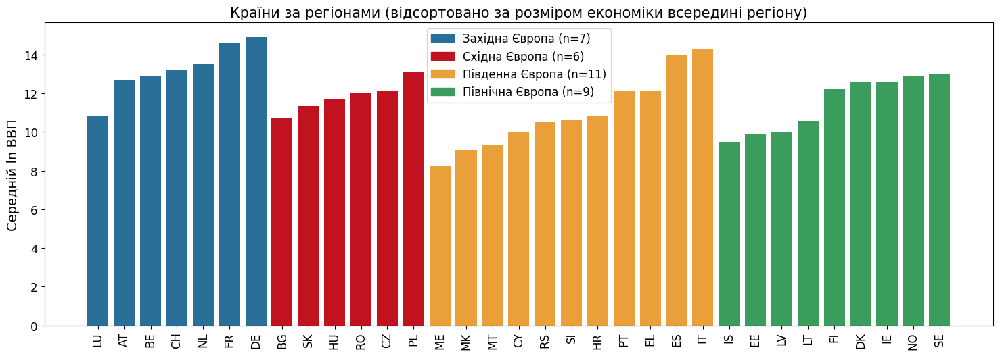

In [4]:
cs = (sdata_A.groupby("CNTR_ID")
      .agg(region=("region", "first"), ln_gdp=("log_gdp", "mean"), ln_ntl=("log_ntl_sum", "mean"),
           gdp_bn=("gdp_meur", lambda s: s.mean() / 1e3), n_obs=("year", "size"))
      .reset_index())
cs["gdp_per_light"] = cs["ln_gdp"] - cs["ln_ntl"]          # ln(ВВП / Sum of Lights): рівень ВВП на одиницю світла

members = {r: sorted(cs.loc[cs["region"] == r, "CNTR_ID"]) for r in REGIONS}
all_c = sorted(cs["CNTR_ID"])

reg_tab = (cs.groupby("region")
           .agg(n_countries=("CNTR_ID", "nunique"), countries=("CNTR_ID", lambda s: ", ".join(sorted(s))),
                n_obs=("n_obs", "sum"), mean_ln_gdp=("ln_gdp", "mean"), sd_ln_gdp=("ln_gdp", "std"),
                min_gdp_bn=("gdp_bn", "min"), max_gdp_bn=("gdp_bn", "max"),
                mean_ln_ntl=("ln_ntl", "mean"), sd_ln_ntl=("ln_ntl", "std"))
           .reindex(REGIONS))
reg_tab.index = [REG_LABEL[r] for r in reg_tab.index]
display(reg_tab.round(2))
reg_tab.to_csv(TABLES_DIR / "table_regions.csv")

too_small = [r for r in REGIONS if len(members[r]) < 5]
if too_small:
    print("УВАГА: у регіонах", too_small, "менше 5 країн; регіональні моделі там будуть вкрай нестабільними.")

fig, ax = plt.subplots(figsize=(15, 5.5))
order = cs.assign(o=cs["region"].map({r: i for i, r in enumerate(REGIONS)})).sort_values(["o", "ln_gdp"])
ax.bar(range(len(order)), order["ln_gdp"], color=[REG_COLOR[r] for r in order["region"]])
ax.set_xticks(range(len(order))); ax.set_xticklabels(order["CNTR_ID"], rotation=90, fontsize=12)
ax.set(ylabel="Середній ln ВВП", title="Країни за регіонами (відсортовано за розміром економіки всередині регіону)")
ax.legend(handles=[Patch(color=REG_COLOR[r], label=f"{REG_LABEL[r]} (n={len(members[r])})") for r in REGIONS], fontsize=12)
save_show(fig, "fig1_regions.png", bbox=False)

## 3. Допоміжні функції і набір моделей

Ті самі моделі, що у просторовому ноутбуці: Linear Regression, Ridge, SVR, Random Forest, Gradient Boosting, AdaBoost, XGBoost, LightGBM (останні два — якщо встановлені). На всіх ознаках навчаються лише моделі, що допускають корельовані ознаки (`CORR_TOLERANT`).

- `model_registry`, `search_spaces` — моделі з параметрами за замовчуванням і простори пошуку для tuning;
- `corr_select` — жадібний кореляційний відбір ознак;
- `sol_baseline` — базова модель: лінійна регресія ln ВВП на ln Sum of Lights.

In [5]:
model_registry = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "SVR": SVR(),
    "Random Forest": RandomForestRegressor(random_state=SEED, n_jobs=1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=SEED),
    "AdaBoost": AdaBoostRegressor(random_state=SEED),
}
if XGBRegressor is not None:
    model_registry["XGBoost"] = XGBRegressor(random_state=SEED, objective="reg:squarederror", n_jobs=1, verbosity=0)
if LGBMRegressor is not None:
    model_registry["LightGBM"] = LGBMRegressor(random_state=SEED, verbosity=-1, n_jobs=1)
CORR_TOLERANT = [m for m in ["Ridge", "Random Forest", "Gradient Boosting", "AdaBoost", "XGBoost", "LightGBM"] if m in model_registry]

search_spaces = {
    "Ridge": {"alpha": loguniform(1e-3, 1e3)},
    "SVR": {"C": loguniform(.1, 1000), "epsilon": loguniform(.01, 1), "gamma": loguniform(1e-4, 1)},
    "Random Forest": {"n_estimators": randint(100, 401), "max_depth": randint(2, 16),
                      "min_samples_leaf": randint(1, 9), "max_features": uniform(.4, .6)},
    "Gradient Boosting": {"n_estimators": randint(50, 401), "learning_rate": loguniform(.01, .3),
                          "max_depth": randint(2, 6), "subsample": uniform(.6, .4)},
    "AdaBoost": {"n_estimators": randint(50, 401), "learning_rate": loguniform(.01, 1)},
    "XGBoost": {"n_estimators": randint(50, 401), "max_depth": randint(2, 7),
                "learning_rate": loguniform(.01, .3), "subsample": uniform(.6, .4)},
    "LightGBM": {"n_estimators": randint(50, 401), "num_leaves": randint(4, 32),
                 "learning_rate": loguniform(.01, .3), "min_child_samples": randint(5, 31)},
}


def corr_select(X, priority, thr):
    """Жадібний відбір: пріоритетна ознака першою; наступна ознака береться,
    лише якщо |r| з усіма вже обраними <= thr. Для відкинутої зберігаємо, з ким вона корелює."""
    X = X.loc[:, X.std() > 0]                       # сталі ознаки не мають кореляції
    C = X.corr()
    order = ([priority] if priority in X.columns else []) + [f for f in X.columns if f != priority]
    selected, dropped = [], {}
    for f in order:
        if selected:
            r = C.loc[f, selected].abs()
            if r.max() > thr:
                dropped[f] = (r.idxmax(), float(C.loc[f, r.idxmax()]))
                continue
        selected.append(f)
    return selected, dropped, C


def sol_baseline(dfit, dpred):
    """Базова модель: лінійна регресія ln ВВП на ln Sum of Lights (єдина ознака світла), навчена на dfit."""
    m = LinearRegression().fit(dfit[["log_ntl_sum"]], dfit[TARGET])
    return m.predict(dpred[["log_ntl_sum"]])

### Функції навчання та оцінки моделей

Ці функції замінюють блоки, що повторювалися для кожної специфікації (лише світло / світло + додаткові змінні) і для кожного варіанта фінальної моделі.

- `reg_metrics` — метрики в логарифмах (R², RMSE, MAE) і відносні похибки в рівнях ВВП (MedAPE, MAPE, частка прогнозів з похибкою ≤ 10 % і ≤ 25 %);
- `year_cv` — rolling-origin CV усередині Train: фолд — один рік, навчання — усі попередні роки;
- `region_data` — спостереження регіону, за потреби лише вказаних вибірок (`"Train"`, `"Validation"`, `"Test"`);
- `fit_model` — копія моделі з `model_registry` з заданими параметрами, навчена на переданих даних;
- `fit_final` — навчає модель на Train+Validation регіону і додає прогноз `pred` і залишок `resid` для всіх його років;
- `test_metrics` — метрики моделі на Test разом з базовою моделлю Sum of Lights (навченою на Train+Validation);
- `evaluate_best` — для обраної в кожному регіоні моделі виконує `fit_final` і збирає таблицю метрик на Test;
- `run_validation` — етап Train → Validation для заданих функцій ознак: усі моделі з параметрами за замовчуванням, потім tuning `TOP_K` найкращих;
- `best_per_set` — найкраща за Validation RMSE модель у кожному регіоні та наборі ознак;
- `show_validation` — виводить таблиці Validation і найкращі моделі кожного набору.

In [6]:
VAL_COLS = ["Train RMSE", "Val RMSE", "Val R2", "Val MedAPE_%", "Val MAE", "Val MAPE_%", "Val within10_%", "Val within25_%"]
FS_ORDER = {FS_PCA: 0, FS_SEL: 1, FS_ALL: 2, "—": 3}          # групи наборів ознак, базова модель - в кінці
TRAIN_VAL = ["Train", "Validation"]


def reg_metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    ape = np.abs(np.exp(p - y) - 1)                       # відносна похибка в рівнях ВВП
    ss = ((y - y.mean()) ** 2).sum()
    return {"R2": 1 - ((y - p) ** 2).sum() / ss if ss > 0 else np.nan,
            "RMSE": float(np.sqrt(np.mean((y - p) ** 2))),
            "MAE": float(np.mean(np.abs(y - p))),
            "MedAPE_%": 100 * float(np.median(ape)),
            "MAPE_%": 100 * float(np.mean(ape)),
            "within10_%": 100 * float(np.mean(ape <= .10)), "within25_%": 100 * float(np.mean(ape <= .25))}


def year_cv(d, n_folds=3, min_train_years=4):
    """Rolling-origin CV усередині Train: валідаційний фолд = один рік, навчання = усі попередні роки."""
    yr = d["year"].to_numpy()
    folds = []
    for v in np.sort(np.unique(yr))[-n_folds:]:
        tr_i, te_i = np.where(yr < v)[0], np.where(yr == v)[0]
        if len(np.unique(yr[tr_i])) >= min_train_years:
            folds.append((tr_i, te_i))
    return folds


def region_data(r, *roles):
    d = tdata[tdata["region"] == r]
    if roles:
        d = d[d["role"].isin(roles)]
    return d.reset_index(drop=True)


def fit_model(name, params, fn, d):
    return clone(model_registry[name]).set_params(**params).fit(fn(d), d[TARGET].to_numpy())


def fit_final(r, name, params, fn):
    """Модель на Train+Validation регіону r; прогноз і залишок (= ln(прогноз / факт)) для всіх років."""
    d = region_data(r)
    est = fit_model(name, params, fn, d[d["role"].isin(TRAIN_VAL)])
    d["pred"] = est.predict(fn(d))
    d["resid"] = d["pred"] - d[TARGET]
    return d


def test_metrics(d):
    """Метрики на Test для d з колонкою pred і базової моделі Sum of Lights (Train+Validation -> Test)."""
    dtv, dt = d[d["role"].isin(TRAIN_VAL)], d[d["role"] == "Test"]
    base_m = reg_metrics(dt[TARGET].to_numpy(), sol_baseline(dtv, dt))
    m = reg_metrics(dt[TARGET], dt["pred"])
    ape = 100 * np.abs(np.exp(dt["pred"] - dt[TARGET]) - 1)             # відносна похибка по спостереженнях Test, %
    return {"R2": m["R2"], "RMSE": m["RMSE"], "MedAPE": m["MedAPE_%"], "MAE": m["MAE"], "MAPE": m["MAPE_%"], "within25": m["within25_%"],
            "Baseline R2": base_m["R2"], "Baseline RMSE": base_m["RMSE"], "Baseline MedAPE": base_m["MedAPE_%"],
            "Baseline MAE": base_m["MAE"], "Baseline MAPE": base_m["MAPE_%"], "розбиттів": 1,
            "MedAPE [Q25; Q75]": f"{ape.median():.1f} [{ape.quantile(.25):.1f}; {ape.quantile(.75):.1f}]",
            "краща за baseline (RMSE)": "так" if m["RMSE"] < base_m["RMSE"] else "ні",
            "within10": m["within10_%"]}


def evaluate_best(best, fns, row_prefix):
    """best[r]: dict(model, stage, params, val_rmse); fns[r]: функція ознак; row_prefix(r): перші колонки рядка таблиці."""
    final, rows = {}, []
    for r in REGIONS:
        b = best[r]
        final[r] = d = fit_final(r, b["model"], b["params"], fns[r])
        rows.append({**row_prefix(r), "Модель": f'{b["model"]} | {b["stage"]}', "Val RMSE": b["val_rmse"], **test_metrics(d)})
    return final, pd.DataFrame(rows)


def val_row(r, fs, name, stage, ytr, ptr, yva, pva, params):
    return {"region": r, "Набір ознак": fs, "Модель": name, "Етап": stage,
            "Train RMSE": reg_metrics(ytr, ptr)["RMSE"],
            **{"Val " + k: v for k, v in reg_metrics(yva, pva).items()}, "params": params}


def run_validation(fns, with_baseline=False):
    """Train -> Validation у кожному регіоні: усі моделі (Default), потім tuning TOP_K найкращих (Tuned).
    fns[(r, fs)] перетворює таблицю спостережень на матрицю ознак (навчену лише на Train)."""
    rows, t0 = [], time.time()
    for r in REGIONS:
        dtr, dva = region_data(r, "Train"), region_data(r, "Validation")
        ytr, yva = dtr[TARGET].to_numpy(), dva[TARGET].to_numpy()
        cv = year_cv(dtr)
        X = {fs: (fns[(r, fs)](dtr), fns[(r, fs)](dva)) for fs in FS_MODELS}

        if with_baseline:                                    # лінійна регресія ln ВВП на ln Sum of Lights
            rows.append(val_row(r, "—", "Sum of Lights (базова)", "—",
                                ytr, sol_baseline(dtr, dtr), yva, sol_baseline(dtr, dva), {}))

        cands = []
        for fs, names in FS_MODELS.items():                  # 1) default
            Xa, Xb = X[fs]
            for name in names:
                m = clone(model_registry[name]).fit(Xa, ytr)
                row = val_row(r, fs, name, "Default", ytr, m.predict(Xa), yva, m.predict(Xb), {})
                rows.append(row); cands.append(row)
        top = pd.DataFrame([c for c in cands if c["Модель"] in search_spaces]).nsmallest(TOP_K, "Val RMSE")
        for _, t in top.iterrows():                          # 2) tuning TOP_K з rolling-origin CV
            fs, name = t["Набір ознак"], t["Модель"]
            Xa, Xb = X[fs]
            try:
                s = RandomizedSearchCV(clone(model_registry[name]), search_spaces[name], n_iter=N_ITER,
                                       scoring="neg_root_mean_squared_error", cv=cv, random_state=SEED,
                                       n_jobs=-1, refit=True, error_score=np.nan).fit(Xa, ytr)
                rows.append(val_row(r, fs, name, "Tuned", ytr, s.predict(Xa), yva, s.predict(Xb), dict(s.best_params_)))
            except Exception as e:
                print("tuning пропущено:", r, name, e)
        print(f"{REG_LABEL[r]}: готово, {time.time() - t0:.0f} с")

    res = pd.DataFrame(rows)
    res["Регіон"] = res["region"].map(REG_LABEL)
    return res


def best_per_set(res):
    best = {}
    for r in REGIONS:
        t = res[res["region"] == r]
        for fs in FS_MODELS:
            b = t[t["Набір ознак"] == fs].sort_values("Val RMSE").iloc[0]
            best[(r, fs)] = {"model": b["Модель"], "stage": b["Етап"], "params": b["params"], "val_rmse": b["Val RMSE"]}
    return best


def show_validation(res, best, suffix=""):
    for r in REGIONS:
        t = res[res["region"] == r]
        print(f"\n{REG_LABEL[r]}{suffix}: Validation {val_years[0]}-{val_years[-1]}")
        tt = t.assign(_o=t["Набір ознак"].map(FS_ORDER)).sort_values(["_o", "Val RMSE"]).drop(columns="_o")   # усередині набору - за Val RMSE
        display(tt.set_index(["Набір ознак", "Модель", "Етап"])[VAL_COLS].round(3))
        print("Найкраща за Validation RMSE у кожному наборі:")
        for fs in FS_MODELS:
            b = best[(r, fs)]
            print(f"  {fs}: {b['model']} | {b['stage']} (Val RMSE = {b['val_rmse']:.3f})")

### Функції для графіків

Однакові рисунки будуються для кожної специфікації, тому вони оформлені як функції. Усі рисунки мають збільшений шрифт (`FS_PLOT`, `FS_TS`, `FS_LC`), сітку, менше поділок на осях і спільну легенду над панелями:

- `shade_roles` — фонові смуги Train / Validation / Test на осі років;
- `plot_pred_vs_actual` — рисунок 2×4: прогноз vs факт (верхній ряд) і залишки (нижній ряд) для чотирьох регіонів; з `label_outliers=True` підписуються викиди на Test (код країни і рік), а підписи розставляються без накладання (`_place_labels`);
- `learning_curve` — RMSE на Train і Validation залежно від кількості перших років Train, на яких навчена модель;
- `plot_learning_curves` — криві навчання для чотирьох регіонів: суцільна лінія - Validation, пунктир - Train; у кожній панелі легенда з моделлю регіону, над панелями - спільна легенда (колір - набір ознак або специфікація, тип лінії - вибірка);
- `plot_country_timeseries` — ВВП кожної країни регіону в млрд євро: факт і прогнози однієї або кількох моделей.

In [7]:
import textwrap
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

# ---------------- оформлення графіків (збільшений шрифт) ----------------
FS_PLOT = 16        # базовий шрифт рисунків «прогноз vs факт»
FS_TS = 15          # базовий шрифт рядів ВВП країн
FS_LC = 15          # базовий шрифт кривих навчання
SCATTER_STYLE = {"Train": dict(s=22, alpha=.35), "Validation": dict(s=30, alpha=.6),
                 "Test": dict(s=70, alpha=.95, edgecolor="black", linewidth=.7)}


def shade_roles(ax, train_alpha=.06):
    for ys, role, al in ((train_years, "Train", train_alpha), (val_years, "Validation", .25), (test_years, "Test", .18)):
        ax.axvspan(ys[0] - .5, ys[-1] + .5, color=ROLE_COLOR[role], alpha=al)


def _legend_top(fig, labels, fs, ncol):
    """Частка висоти рисунка під спільну легенду над панелями (щоб легенда не налазила на заголовки панелей)."""
    rows = math.ceil(len(labels) / ncol)
    return 1 - (rows * fs * 1.6 / 72 + 0.15) / fig.get_figheight()


def _legend_ncol(labels, fs, width_in, extra_chars=6):
    """Скільки колонок легенди вміщується в ширину рисунка."""
    char_in = fs / 72 * 0.6
    widest = max(len(l) for l in labels) + extra_chars
    return max(1, min(len(labels), int(width_in / (widest * char_in))))


def _place_labels(ax, pts, fs, pad=0.01):
    """Підписи точок без накладання одне на одного: для кожного підпису шукається найближче вільне місце
    вище або нижче точки (в межах панелі). pts: список (x, y, текст) у координатах даних."""
    if not pts:
        return
    ax.autoscale_view()
    fig = ax.figure
    to_ax = ax.transData + ax.transAxes.inverted()
    size = ax.get_window_extent().transformed(fig.dpi_scale_trans.inverted())   # розмір осі в дюймах
    h = fs / 72 * 1.3 / size.height                                            # висота підпису в частках осі
    placed = []

    def free(lx, ly, w):
        return all(not (lx < px + pw + pad and px < lx + w + pad and ly < py + ph and py < ly + h)
                   for px, py, pw, ph in placed)

    for x, y, text in sorted(pts, key=lambda p: -p[1]):
        fx, fy = to_ax.transform((x, y))
        w = len(text) * fs / 72 * 0.62 / size.width                            # ширина підпису в частках осі
        sides = [fx + 0.015, fx - 0.015 - w] if fx < 0.7 else [fx - 0.015 - w, fx + 0.015]
        spot = None
        for k in range(0, 40):                                                 # 0, +1, -1, +2, -2, ... кроки по вертикалі
            dy = (k + 1) // 2 * h * 0.6 * (1 if k % 2 else -1)
            ly = min(max(fy - h / 2 + dy, 0.0), 1 - h)
            for lx in sides:
                lx = min(max(lx, 0.0), 1 - w)
                if free(lx, ly, w):
                    spot = (lx, ly); break
            if spot:
                break
        lx, ly = spot or (min(max(sides[0], 0.0), 1 - w), min(max(fy, 0.0), 1 - h))
        placed.append((lx, ly, w, h))
        ann = ax.annotate(text, (x, y), xytext=(lx, ly + h / 2), textcoords="axes fraction",
                          fontsize=fs, ha="left", va="center", zorder=5,
                          arrowprops=dict(arrowstyle="-", color="gray", lw=0.6, shrinkA=0, shrinkB=3))
        ann.set_in_layout(False)


def _suptitle(fig, text, fs, top, width=110):
    """Заголовок рисунка над легендою; довгий заголовок переноситься на кілька рядків."""
    text = textwrap.fill(text, width)
    n = text.count("\n") + 1
    fig.suptitle(text, fontsize=fs, y=1 + (n * fs * 1.5 / 72 + 0.1) / fig.get_figheight())


def plot_pred_vs_actual(final, titles, suptitle, fname, label_outliers=False, thr=0.10):
    """Прогноз vs факт (верхній ряд) і залишки (нижній ряд) для чотирьох регіонів.
    final[r]: таблиця з pred і resid; titles[r]: заголовок колонки регіону (можна в кілька рядків).
    label_outliers=True: підписати спостереження Test з |залишок| > thr (без накладання підписів)."""
    n_lines = max(titles[r].count("\n") + 1 for r in REGIONS)
    title_fs = FS_PLOT if n_lines <= 2 else FS_PLOT - 2
    fig, axes = plt.subplots(2, 4, figsize=(18, 10.5 if n_lines <= 2 else 11.5))
    for j, r in enumerate(REGIONS):
        d, top, bot = final[r], axes[0, j], axes[1, j]
        for role, col in ROLE_COLOR.items():
            s = d[d["role"] == role]
            top.scatter(s[TARGET], s["pred"], color=col, label=role, zorder=3 if role == "Test" else 2, **SCATTER_STYLE[role])
            bot.scatter(s["pred"], s["resid"], color=col, zorder=3 if role == "Test" else 2, **SCATTER_STYLE[role])
        lo, hi = min(d[TARGET].min(), d["pred"].min()), max(d[TARGET].max(), d["pred"].max())
        top.plot([lo, hi], [lo, hi], "k--", lw=1.2); bot.axhline(0, color="k", lw=1.2)
        for v in (-thr, thr):
            bot.axhline(v, color="gray", ls=":", lw=1.5)
        for ax in (top, bot):                                     # менше поділок -> більші підписи не налазять
            ax.xaxis.set_major_locator(MaxNLocator(4)); ax.yaxis.set_major_locator(MaxNLocator(5))
            ax.tick_params(labelsize=FS_PLOT - 2); ax.grid(alpha=.25)
        top.set_title(titles[r], fontsize=title_fs)
        top.set_xlabel("Факт ln ВВП", fontsize=FS_PLOT - 1); bot.set_xlabel("Прогноз ln ВВП", fontsize=FS_PLOT - 1)

        if label_outliers:                                        # підписи викидів на Test: код країни і рік
            out = d[(d["role"] == "Test") & (d["resid"].abs() > thr)]
            labels = [f'{o["CNTR_ID"]} {int(o["year"])}' for _, o in out.iterrows()]
            _place_labels(top, list(zip(out[TARGET], out["pred"], labels)), FS_PLOT - 5)
            _place_labels(bot, list(zip(out["pred"], out["resid"], labels)), FS_PLOT - 5)
    axes[0, 0].set_ylabel("Прогноз ln ВВП", fontsize=FS_PLOT); axes[1, 0].set_ylabel("Прогноз - факт (ln)", fontsize=FS_PLOT)
    handles, labs = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labs, loc="upper center", ncol=3, fontsize=FS_PLOT, frameon=False,
               bbox_to_anchor=(0.5, 1.0), markerscale=1.3)
    fig.tight_layout(rect=[0, 0, 1, _legend_top(fig, labs, FS_PLOT, 3)])
    _suptitle(fig, suptitle, FS_PLOT + 1, 1.0)
    save_show(fig, fname, tight=False)


def learning_curve(name, params, fn, dtr, dva, start=3):
    """Модель навчається на перших k роках Train (k = start..усі); RMSE на цих роках і на Validation."""
    ks, e_tr, e_va = [], [], []
    for k in range(start, len(train_years) + 1):
        sub = dtr[dtr["year"] <= train_years[k - 1]]
        est = fit_model(name, params, fn, sub)
        ks.append(k)
        e_tr.append(reg_metrics(sub[TARGET], est.predict(fn(sub)))["RMSE"])
        e_va.append(reg_metrics(dva[TARGET], est.predict(fn(dva)))["RMSE"])
    return ks, e_tr, e_va


def plot_learning_curves(specs, suptitle, fname, titles=None):
    """Криві навчання для чотирьох регіонів: суцільна - Validation, пунктир - Train.
    specs[r]: список dict(model, params, fn, color, group) - group (напр. набір ознак) іде в спільну легенду
    з кольором, а назва моделі - у легенду панелі регіону."""
    n_lines = max(titles[r].count("\n") + 1 for r in REGIONS) if titles else 1
    fig, axes = plt.subplots(1, 4, figsize=(18, 5.6 + 0.3 * (n_lines - 1)))
    groups = {}
    for ax, r in zip(axes, REGIONS):
        dtr, dva = region_data(r, "Train"), region_data(r, "Validation")
        for s in specs[r]:
            ks, e_tr, e_va = learning_curve(s["model"], s["params"], s["fn"], dtr, dva)
            ax.plot(ks, e_va, "o-", color=s["color"], lw=2, ms=6, label=s["model"])
            ax.plot(ks, e_tr, "o--", color=s["color"], lw=1.6, ms=5, alpha=.6)
            groups.setdefault(s["group"], s["color"])
        ax.set_title(titles[r] if titles else REG_LABEL[r], fontsize=FS_LC + 1)
        ax.set_xlabel("Кількість років у Train", fontsize=FS_LC - 1)
        ax.xaxis.set_major_locator(MaxNLocator(5, integer=True)); ax.yaxis.set_major_locator(MaxNLocator(5))
        ax.tick_params(labelsize=FS_LC - 2); ax.grid(alpha=.25)
        ax.legend(title="Модель", fontsize=FS_LC - 4, title_fontsize=FS_LC - 4, loc="best")   # модель свого регіону
    axes[0].set_ylabel("RMSE (ln ВВП)", fontsize=FS_LC)

    # спільна легенда: колір - набір ознак / специфікація, тип лінії - вибірка
    handles = [Line2D([], [], color=c, lw=3, label=g) for g, c in groups.items()] + \
              [Line2D([], [], color="gray", lw=2, ls="-", marker="o", label="Validation"),
               Line2D([], [], color="gray", lw=2, ls="--", marker="o", alpha=.6, label="Train")]
    labs = [h.get_label() for h in handles]
    ncol = _legend_ncol(labs, FS_LC, 18)
    fig.legend(handles=handles, loc="upper center", ncol=ncol, fontsize=FS_LC, frameon=False, bbox_to_anchor=(0.5, 1.0))
    fig.tight_layout(rect=[0, 0, 1, _legend_top(fig, labs, FS_LC, ncol)])
    _suptitle(fig, suptitle, FS_LC + 2, 1.0)
    save_show(fig, fname, tight=False)


def plot_country_timeseries(r, series, suptitle, fname, start_year=None):
    """ВВП кожної країни регіону r (млрд євро): факт і прогнози. series: список dict(d, fmt, color, label);
    факт береться з першої таблиці. start_year - показати лише роки від start_year."""
    base = series[0]["d"]
    cl = sorted(base["CNTR_ID"].unique()); nc = 4; nr = math.ceil(len(cl) / nc)
    fig, axes = plt.subplots(nr, nc, figsize=(18, 3.9 * nr + 1.2), squeeze=False)

    def country(d, cn):
        g = d[d["CNTR_ID"] == cn].sort_values("year")
        return g[g["year"] >= start_year] if start_year else g

    for ax, cn in zip(axes.ravel(), cl):
        shade_roles(ax)
        g = country(base, cn)
        ax.plot(g["year"], np.exp(g[TARGET]) / 1e3, "k-o", ms=5, lw=1.8, label="Факт")
        for s in series:
            h = country(s["d"], cn)
            ax.plot(h["year"], np.exp(h["pred"]) / 1e3, s["fmt"], ms=5, lw=1.8, color=s["color"], label=s["label"])
        ax.set_title(cn, fontsize=FS_TS + 1, fontweight="bold")
        ax.xaxis.set_major_locator(MaxNLocator(5, integer=True))   # роки через один-два, щоб підписи не налазили
        ax.yaxis.set_major_locator(MaxNLocator(4))
        ax.tick_params(labelsize=FS_TS - 2); ax.grid(alpha=.25)
    for ax in axes.ravel()[len(cl):]:
        ax.axis("off")
    for ax in axes[:, 0]:
        ax.set_ylabel("ВВП, млрд євро", fontsize=FS_TS - 1)

    handles, labs = axes[0, 0].get_legend_handles_labels()            # спільна легенда над панелями
    ncol = _legend_ncol(labs, FS_TS, 18)
    fig.legend(handles, labs, loc="upper center", ncol=ncol, fontsize=FS_TS, frameon=False, bbox_to_anchor=(0.5, 1.0))
    fig.tight_layout(rect=[0, 0, 1, _legend_top(fig, labs, FS_TS, ncol)])
    _suptitle(fig, suptitle, FS_TS + 2, 1.0)
    save_show(fig, fname, tight=False)

## 4. Поділ за роками: Train / Validation / Test

`N_TEST_YEARS` останніх років — Test, `N_VAL_YEARS` років перед ними — Validation, решта — Train. Країни не діляться: кожна присутня в усіх трьох вибірках.

Train: 2012-2021 | Validation: 2022-2023 | Test: 2024-2025


,країн,Train,Validation,Test
Регіон,,,,
Західна Європа,7,70,14,14
Східна Європа,6,60,12,12
Південна Європа,11,110,22,22
Північна Європа,9,90,18,18


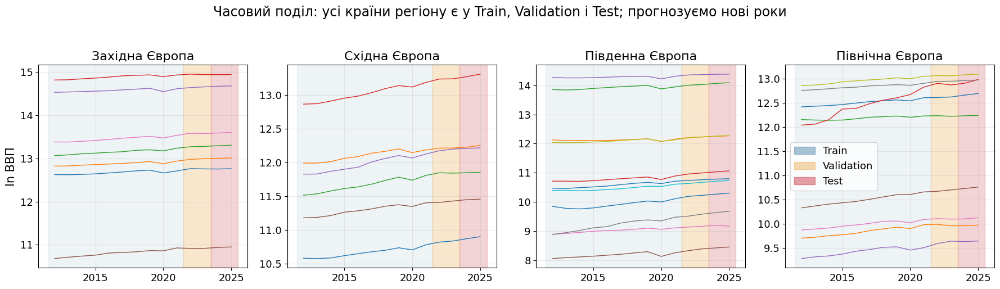

In [8]:
# ===== поділ на Train / Validation / Test за РОКАМИ (усередині кожного регіону) =====
years = sorted(sdata_A["year"].unique())
test_years = years[-N_TEST_YEARS:]
val_years = years[-(N_TEST_YEARS + N_VAL_YEARS):-N_TEST_YEARS]
train_years = years[:-(N_TEST_YEARS + N_VAL_YEARS)]
role_of_year = {**{y: "Train" for y in train_years}, **{y: "Validation" for y in val_years}, **{y: "Test" for y in test_years}}
tdata = sdata_A.assign(role=sdata_A["year"].map(role_of_year)).reset_index(drop=True)
print(f"Train: {train_years[0]}-{train_years[-1]} | Validation: {val_years[0]}-{val_years[-1]} | Test: {test_years[0]}-{test_years[-1]}")

rows = []
for r in REGIONS:
    t = region_data(r)
    cnt = t.groupby("role").size()
    assert all(cnt.get(k, 0) > 0 for k in ROLE_COLOR), f"У регіоні {r} немає спостережень в одній із вибірок"
    rows.append({"Регіон": REG_LABEL[r], "країн": t["CNTR_ID"].nunique(),
                 "Train": cnt["Train"], "Validation": cnt["Validation"], "Test": cnt["Test"]})
display(pd.DataFrame(rows).set_index("Регіон"))

fig, axes = plt.subplots(1, 4, figsize=(18, 5), sharey=False)
for ax, r in zip(axes, REGIONS):
    for c, g in region_data(r).groupby("CNTR_ID"):
        ax.plot(g["year"], g[TARGET], lw=1, label=c)
    shade_roles(ax, train_alpha=.08)
    ax.set_title(REG_LABEL[r], fontsize=16); ax.tick_params(labelsize=13); ax.grid(alpha=.25)
axes[0].set_ylabel("ln ВВП", fontsize=15)
axes[-1].legend(handles=[Patch(color=c, alpha=.4, label=k) for k, c in ROLE_COLOR.items()], fontsize=13)
fig.suptitle("Часовий поділ: усі країни регіону є у Train, Validation і Test; прогнозуємо нові роки", y=1.03, fontsize=17)
save_show(fig, "fig_temporal_split.png")

Таблиця: кількість спостережень у розбиттях Train, Validation, Test для кожної підвибірки


Графіки: Кожна лінія - логарифм ВВП однієї країни.Кольорові смуги показують, як ділимо роки: синя (Train) охоплює 2012–2021, жовта (Validation) — 2022–2023, червона (Test) — 2024–2025

### Пропуски в контрольних змінних по всій панелі

Та сама перевірка, що в розділі 1, але для всієї панелі з ВВП, включно з виключеними країнами (`AL`, `BA`).

In [9]:
# ===== Пропуски у контрольних змінних (населення, широта, площа): країни і роки =====
panel = pd.read_csv(PANEL_PATH).dropna(subset=["gdp_meur"])
ctrl_all = pd.read_csv(CONTROLS_PATH)

chk = add_log_controls(panel[["CNTR_ID", "year", "total_mask_km2"]].merge(
    ctrl_all[["CNTR_ID", "year", "population", "latitude"]], on=["CNTR_ID", "year"], how="left"))

miss = chk[chk[STRUCT_NOREG].isna().any(axis=1)].copy()
miss["відсутні змінні"] = missing_vars_text(miss, STRUCT_NOREG)
miss["виключена з вибірки"] = miss["CNTR_ID"].isin(EXCLUDED).map({True: "так", False: "ні"})

print(f"Спостережень з ВВП: {len(chk)} | без хоча б однієї контрольної змінної: {len(miss)}")
if miss.empty:
    print("Пропусків у контрольних змінних немає.")
else:
    summary = (miss.groupby("CNTR_ID")
               .agg(роки=("year", lambda s: ", ".join(map(str, sorted(s)))),
                    кількість=("year", "size"),
                    відсутні=("відсутні змінні", lambda s: "; ".join(sorted(set(s)))),
                    виключена=("виключена з вибірки", "first")))
    display(summary)
    display(miss[["CNTR_ID", "year", "відсутні змінні", "виключена з вибірки"]].reset_index(drop=True))
    miss.to_csv(TABLES_DIR / "missing_control_variables_full_panel.csv", index=False)

Спостережень з ВВП: 489 | без хоча б однієї контрольної змінної: 14


,роки,кількість,відсутні,виключена
CNTR_ID,,,,
AL,2024,1,"ln_population, latitude",так
BA,"2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020...",13,"ln_population, latitude",так


,CNTR_ID,year,відсутні змінні,виключена з вибірки
0,AL,2024,"ln_population, latitude",так
1,BA,2013,"ln_population, latitude",так
2,BA,2014,"ln_population, latitude",так
3,BA,2015,"ln_population, latitude",так
4,BA,2016,"ln_population, latitude",так
5,BA,2017,"ln_population, latitude",так
6,BA,2018,"ln_population, latitude",так
7,BA,2019,"ln_population, latitude",так
8,BA,2020,"ln_population, latitude",так
9,BA,2021,"ln_population, latitude",так


## 5. Кореляційний аналіз і PCA на Train

У кожному регіоні ознаки світла логарифмуються (`log1p`), далі  відкидаються ознаки з |r| > `CORR_THRESHOLD` відносно вже обраних (пріоритетна ознака — `PRIORITY_FEATURE`). Для обраних ознак будується scaler + PCA (`PCA_VARIANCE` дисперсії). Червоним на рисунку позначені відкинуті ознаки.

- `build_features` — кореляційний відбір, scaler і PCA на Train регіону; повертає функції, що перетворюють дані на матриці ознак для трьох наборів;
- `plot_corr_heatmaps` — кореляційні матриці ознак на Train для чотирьох регіонів (будується у двох варіантах компонування).


Західна Європа: обрано 4 -> ['ntl_sum_area_weighted', 'ntl_mean', 'ntl_p25', 'ntl_cv']
  відкинуті: ntl_mean_area_weighted <- ntl_mean (+1.00); ntl_median <- ntl_mean (+0.85); ntl_std <- ntl_mean (+0.90); ntl_p75 <- ntl_mean (+0.91); ntl_p90 <- ntl_mean (+0.96); ntl_p95 <- ntl_mean (+0.96); ntl_iqr <- ntl_mean (+0.92); lit_area_km2 <- ntl_sum_area_weighted (+0.95); lit_area_share_valid <- ntl_mean (+0.91); ntl_positive_mean <- ntl_mean (+0.87); ntl_sum_cap50 <- ntl_sum_area_weighted (+0.99); ntl_sum_cap100 <- ntl_sum_area_weighted (+0.99); ntl_sum_log1p <- ntl_sum_area_weighted (+0.97); lit_area_km2_t1 <- ntl_sum_area_weighted (+0.96); lit_area_km2_t2 <- ntl_sum_area_weighted (+0.97); lit_area_km2_t5 <- ntl_sum_area_weighted (+0.98); ntl_share_ge100 <- ntl_cv (+0.80); ntl_coverage_share <- ntl_mean (-0.84)

Східна Європа: обрано 5 -> ['ntl_sum_area_weighted', 'ntl_mean', 'ntl_p75', 'ntl_cv', 'ntl_positive_mean']
  відкинуті: ntl_mean_area_weighted <- ntl_mean (+1.00); ntl_std <- ntl_s

,спостережень Train,ознак до відбору,після кореляцій,PC,"PC1, %","усі PC, %"
Регіон,,,,,,
Західна Європа,70,22,4,3,44.2,96.8
Східна Європа,60,22,5,3,49.2,95.8
Південна Європа,110,22,4,3,38.6,92.0
Північна Європа,90,22,11,5,46.8,91.7


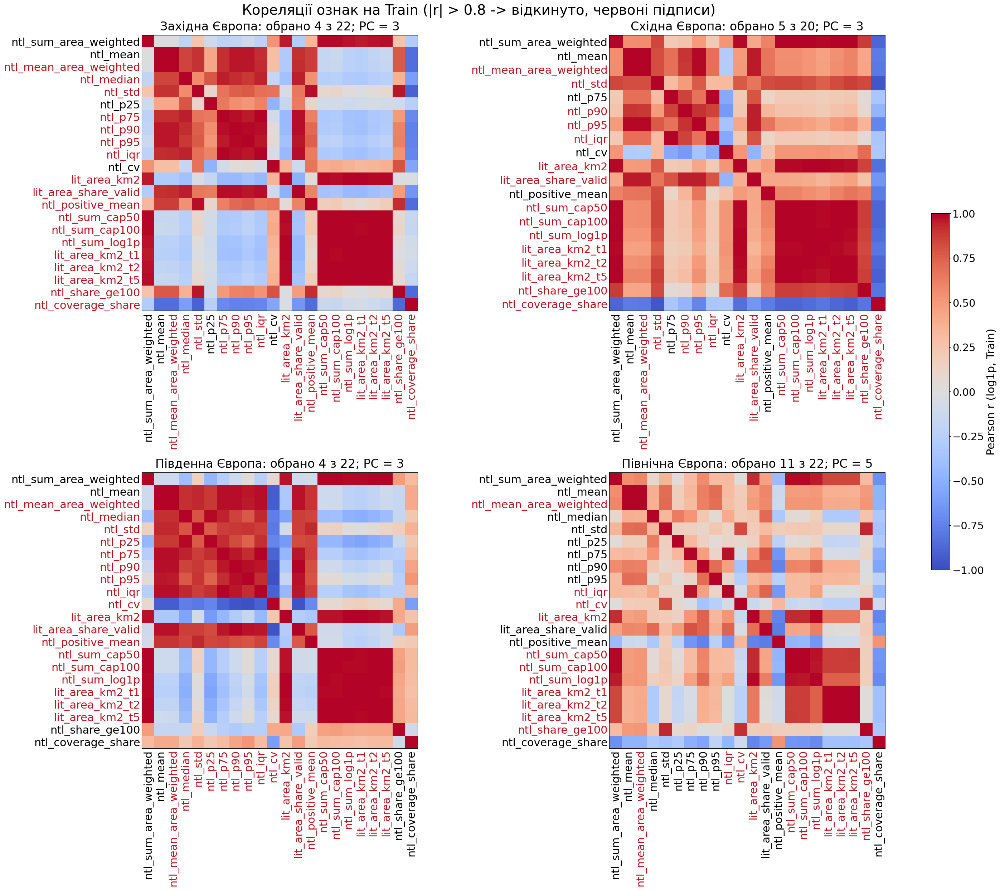

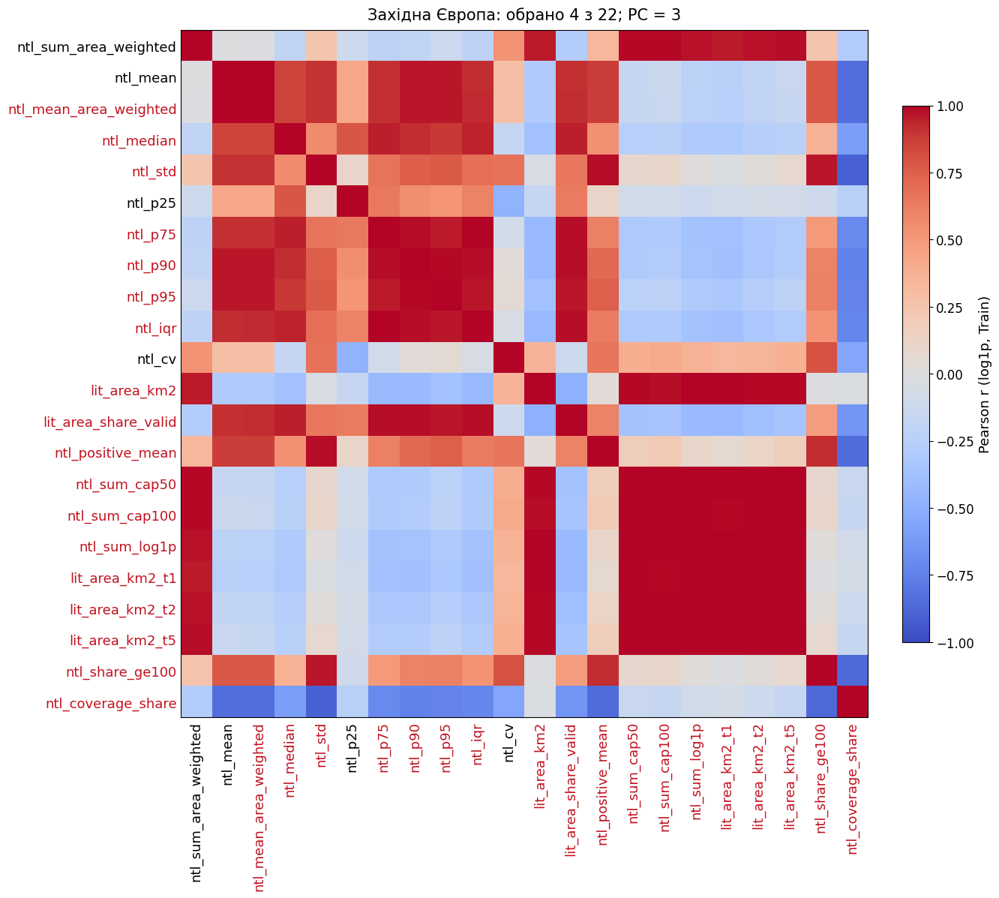

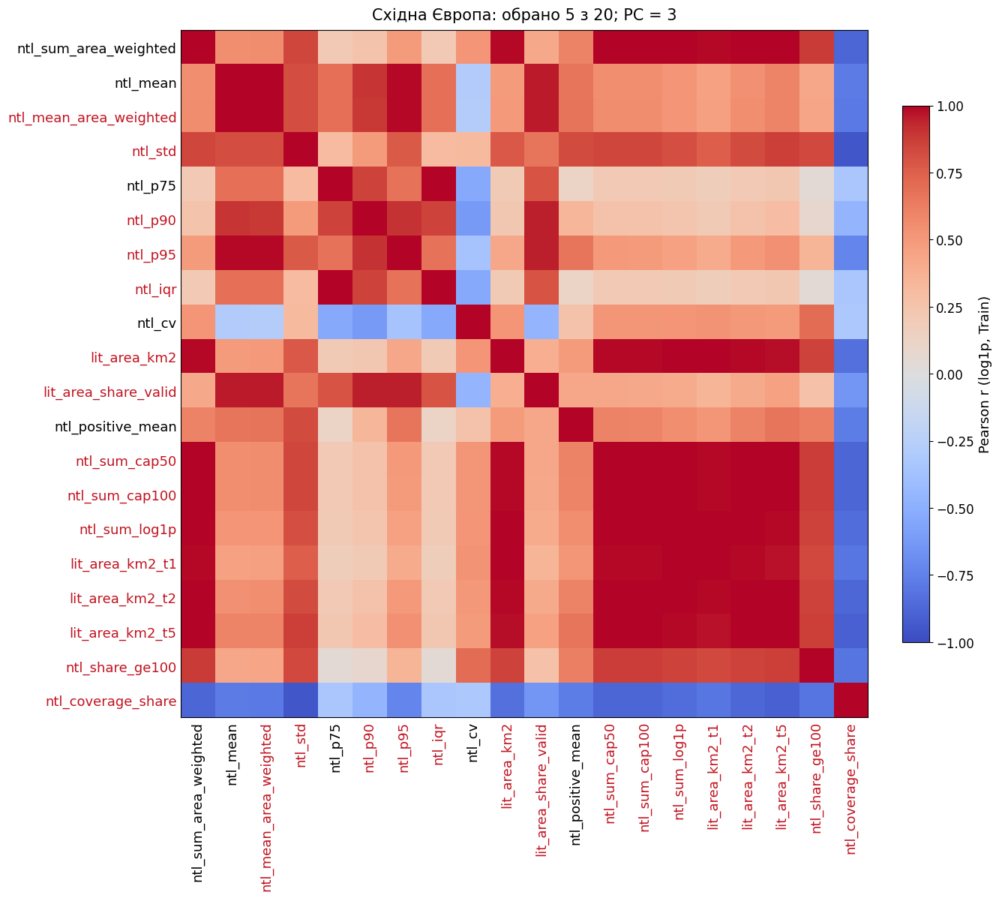

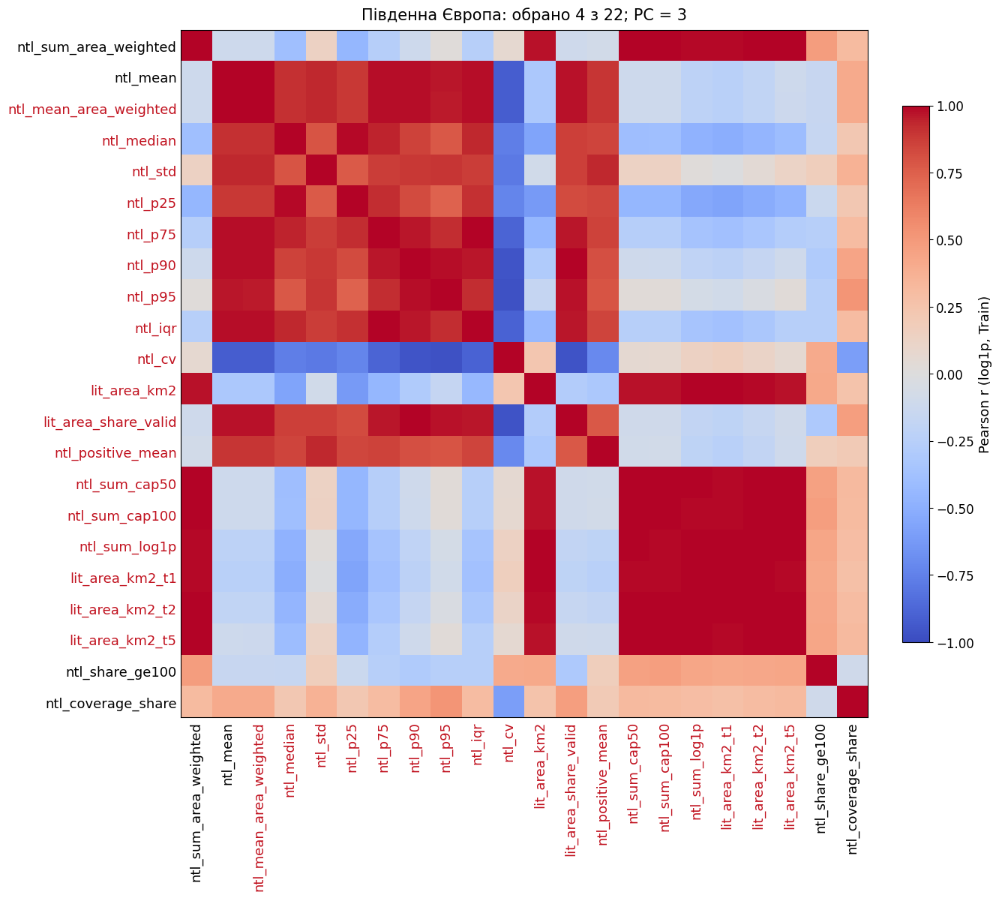

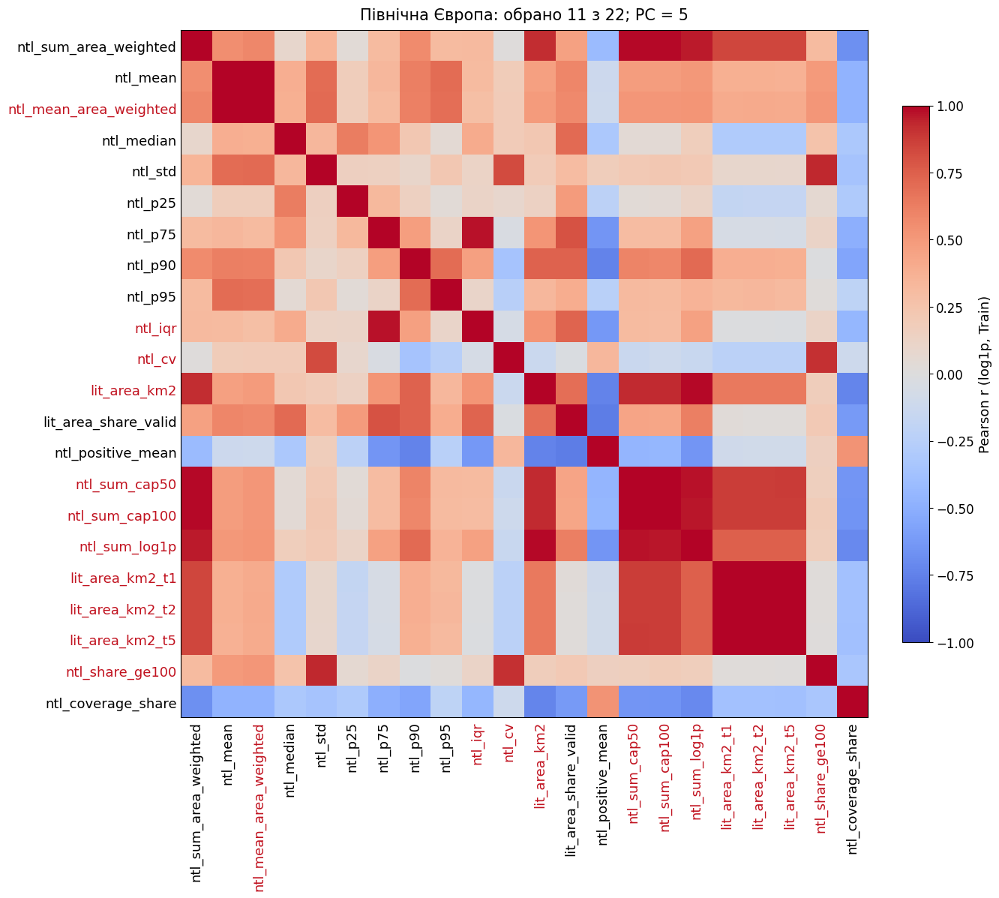

In [10]:
# ===== кореляційний відбір і PCA на Train кожного регіону =====
feats = [f for f in CANDIDATE_FEATURES if f in sdata_A.columns]


def build_features(dtr):
    """Кореляційний відбір + scaler + PCA, навчені лише на Train."""
    sel, drop, C = corr_select(np.log1p(dtr[feats]), PRIORITY_FEATURE, CORR_THRESHOLD)
    sc_s = StandardScaler().fit(np.log1p(dtr[sel]))
    pca = PCA(n_components=PCA_VARIANCE, svd_solver="full").fit(sc_s.transform(np.log1p(dtr[sel])))
    allf = [f for f in feats if np.log1p(dtr[f]).std() > 0]
    sc_a = StandardScaler().fit(np.log1p(dtr[allf]))
    sc_sel = StandardScaler().fit(np.log1p(dtr[sel]))                 # вибрані ознаки без PCA
    fn = {FS_PCA: lambda x: pca.transform(sc_s.transform(np.log1p(x[sel]))),
          FS_SEL: lambda x: sc_sel.transform(np.log1p(x[sel])),
          FS_ALL: lambda x: sc_a.transform(np.log1p(x[allf]))}
    return {"sel": sel, "drop": drop, "C": C, "pca": pca, "fn": fn, "allf": allf}


CORR_LABEL_FS = 13          # шрифт підписів на окремих рисунках регіонів (пт)
CORR_CELL_IN = 0.42         # розмір клітинки матриці на окремих рисунках (дюйми)
CORR_GRID_FS = 22           # шрифт підписів на зведеному рисунку 2x2 (пт)
CORR_GRID_CELL_IN = 0.42    # розмір клітинки на зведеному рисунку; має бути більшим за висоту шрифту (22 пт ≈ 0.31")


def draw_corr(ax, r, show_x=True, show_y=True, fs=CORR_LABEL_FS):
    """Кореляційна матриця регіону r; відкинуті ознаки - червоні підписи."""
    C, sel = TF[r]["C"], TF[r]["sel"]
    n = len(C)
    im = ax.imshow(C.values, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    ax.set_xticklabels(C.columns if show_x else [], rotation=90, fontsize=fs)
    ax.set_yticklabels(C.columns if show_y else [], fontsize=fs)
    for lab in ax.get_xticklabels() + ax.get_yticklabels():
        lab.set_color("black" if lab.get_text() in sel else "#c1121f")
    ax.tick_params(length=0)
    ax.set_title(f"{REG_LABEL[r]}: обрано {len(sel)} з {n}; PC = {TF[r]['pca'].n_components_}",
                 fontsize=fs + 2, pad=10)
    return im


def add_corr_colorbar(fig, ax, fs=CORR_LABEL_FS, shrink=0.6):
    cb = fig.colorbar(np.ravel(ax)[0].images[0], ax=ax, shrink=shrink)
    cb.set_label("Pearson r (log1p, Train)", fontsize=fs)
    cb.ax.tick_params(labelsize=fs - 1)


def plot_corr_heatmaps(per_region=True):
    """Зведений рисунок 2x2 і (за потреби) окремий рисунок для кожного регіону."""
    cols0 = list(TF[REGIONS[0]]["C"].columns)
    same = all(list(TF[r]["C"].columns) == cols0 for r in REGIONS)      # однаковий порядок ознак -> підписи стовпців лише внизу
    n = max(len(TF[r]["C"]) for r in REGIONS)
    title = f"Кореляції ознак на Train (|r| > {CORR_THRESHOLD} -> відкинуто, червоні підписи)"

    side = n * CORR_GRID_CELL_IN
    label_in = CORR_GRID_FS / 72 * 14                                # місце під найдовший підпис (~22 символи)
    fig, axes = plt.subplots(2, 2, figsize=(2 * (side + label_in) + 2, 2 * side + label_in + 2), constrained_layout=True)
    for i, (ax, r) in enumerate(zip(axes.ravel(), REGIONS)):
        draw_corr(ax, r, show_x=not same or i >= 2, fs=CORR_GRID_FS)   # підписи рядків - на кожній панелі: у кожного регіону свій відбір
    add_corr_colorbar(fig, axes, fs=CORR_GRID_FS, shrink=0.5)
    fig.suptitle(title, fontsize=CORR_GRID_FS + 6)
    save_show(fig, "fig_temporal_corr_train.png", tight=False)

    if per_region:                                                   # для вставки в текст на всю ширину сторінки
        side = n * CORR_CELL_IN
        for r in REGIONS:
            fig, ax = plt.subplots(figsize=(side + 4, side + 3), constrained_layout=True)
            draw_corr(ax, r)
            add_corr_colorbar(fig, ax, shrink=0.7)
            save_show(fig, f"fig_temporal_corr_train_{r}.png", tight=False)


TF, rows = {}, []
for r in REGIONS:
    dtr = region_data(r, "Train")
    TF[r] = b = build_features(dtr)
    ev = b["pca"].explained_variance_ratio_
    rows.append({"Регіон": REG_LABEL[r], "спостережень Train": len(dtr), "ознак до відбору": len(feats),
                 "після кореляцій": len(b["sel"]), "PC": b["pca"].n_components_,
                 "PC1, %": 100 * ev[0], "усі PC, %": 100 * ev.sum()})
    print(f"\n{REG_LABEL[r]}: обрано {len(b['sel'])} -> {b['sel']}")
    print("  відкинуті:", "; ".join(f"{f} <- {g} ({v:+.2f})" for f, (g, v) in b["drop"].items()))
tf_tab = pd.DataFrame(rows).set_index("Регіон")
display(tf_tab.round(1)); tf_tab.to_csv(TABLES_DIR / "temporal_corr_pca_summary.csv")

# кореляційні матриці: зведений рисунок 2x2 і окремий рисунок для кожного регіону (для вставки в текст)
plot_corr_heatmaps(per_region=True)

### Навантаження головних компонент

Навантаження рахуються у двох варіантах: як кореляція стандартизованої ознаки з компонентою (`kind="corr"`) і як коефіцієнти власних векторів (`kind="eigen"`). Обидва варіанти зберігаються в ті самі файли `pca_loadings_*.csv`, тому після виконання обох клітинок у файлах лишаються коефіцієнти власних векторів, і саме вони використовуються в графіках навантажень нижче.

- `pca_report` — таблиці поясненої дисперсії і навантажень для кожного регіону з збереженням у CSV;
- `plot_scree` — осипна діаграма: частка дисперсії кожної компоненти і накопичена частка.


Західна Європа: 4 ознак -> 3 головних компонент (Train, n = 70)


,Власне значення,"Частка дисперсії, %","Накопичена частка, %"
PC1,1.792,44.152,44.152
PC2,1.387,34.168,78.320
PC3,0.752,18.524,96.844


,PC1,PC2,PC3
ntl_sum_area_weighted,0.713,0.246,0.647
ntl_mean,-0.065,0.926,-0.333
ntl_p25,-0.685,0.587,0.389
ntl_cv,0.886,0.324,-0.244



Східна Європа: 5 ознак -> 3 головних компонент (Train, n = 60)


,Власне значення,"Частка дисперсії, %","Накопичена частка, %"
PC1,2.501,49.190,49.190
PC2,1.856,36.511,85.701
PC3,0.515,10.137,95.838


,PC1,PC2,PC3
ntl_sum_area_weighted,0.766,0.505,-0.342
ntl_mean,0.933,-0.276,0.104
ntl_p75,0.611,-0.673,-0.341
ntl_cv,0.005,0.959,-0.201
ntl_positive_mean,0.793,0.349,0.472


... (2 outputs left out)

,PC1,PC2,PC3
ntl_sum_area_weighted,0.830,0.369,-0.227
ntl_mean,-0.393,0.721,0.538
ntl_share_ge100,0.836,-0.049,0.485
ntl_coverage_share,0.020,0.897,-0.313



Північна Європа: 11 ознак -> 5 головних компонент (Train, n = 90)


,Власне значення,"Частка дисперсії, %","Накопичена частка, %"
PC1,5.206,46.799,46.799
PC2,1.815,16.315,63.114
PC3,1.583,14.229,77.343
PC4,0.992,8.916,86.259
PC5,0.605,5.442,91.701


,PC1,PC2,PC3,PC4,PC5
ntl_sum_area_weighted,0.655,0.355,-0.179,-0.496,0.176
ntl_mean,0.744,0.539,0.300,0.142,-0.081
ntl_median,0.598,-0.454,0.513,0.161,-0.088
ntl_std,0.422,0.449,0.677,-0.215,-0.174
ntl_p25,0.437,-0.496,0.454,0.183,0.522
ntl_p75,0.722,-0.414,-0.058,-0.086,-0.413
ntl_p90,0.825,0.186,-0.426,0.214,0.061
ntl_p95,0.533,0.558,-0.168,0.563,0.094
lit_area_share_valid,0.942,-0.253,0.006,0.096,-0.124
ntl_positive_mean,-0.701,0.378,0.547,0.012,0.021


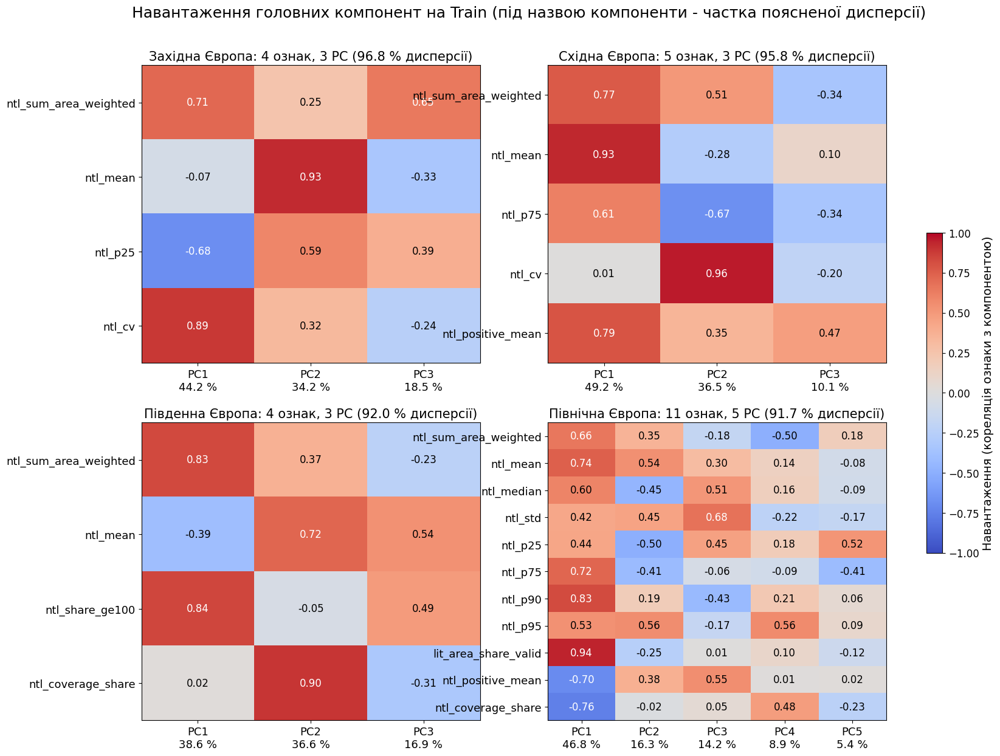

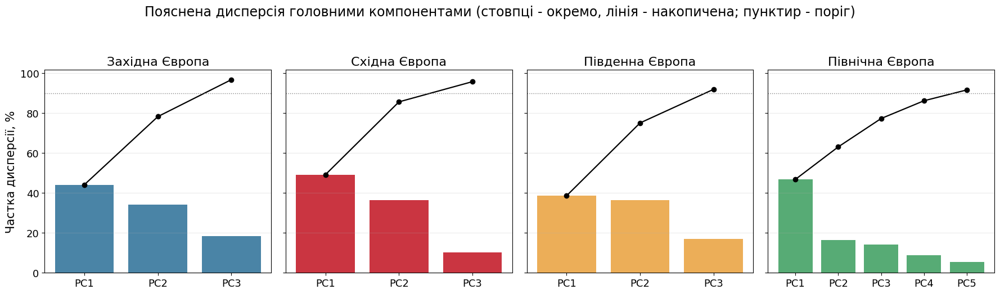

In [12]:
# ===== Навантаження головних компонент (PCA) на Train кожної підвибірки =====
def pca_report(kind):
    LOAD, EVAR = {}, {}
    for r in REGIONS:
        dtr = region_data(r, "Train")
        sel, pca = TF[r]["sel"], TF[r]["pca"]
        pcs = [f"PC{k + 1}" for k in range(pca.n_components_)]
        if kind == "corr":            # кореляція ознаки (після стандартизації) з головною компонентою
            Z = StandardScaler().fit_transform(np.log1p(dtr[sel]))
            S = pca.transform(Z)
            L = pd.DataFrame([[np.corrcoef(Z[:, j], S[:, k])[0, 1] for k in range(len(pcs))] for j in range(len(sel))],
                             index=sel, columns=pcs)
        else:                         # коефіцієнти власних векторів v_jk: ознаки x компоненти
            L = pd.DataFrame(pca.components_.T, index=sel, columns=pcs)
            assert np.allclose((L ** 2).sum(), 1)            # кожен вектор має одиничну довжину
        ev = pca.explained_variance_ratio_
        LOAD[r] = L
        EVAR[r] = pd.DataFrame({"Власне значення": pca.explained_variance_,
                                "Частка дисперсії, %": 100 * ev,
                                "Накопичена частка, %": 100 * np.cumsum(ev)}, index=pcs)

        print(f"\n{REG_LABEL[r]}: {len(sel)} ознак -> {len(pcs)} головних компонент (Train, n = {len(dtr)})")
        display(EVAR[r].round(3))
        display(L.round(3))
        EVAR[r].to_csv(TABLES_DIR / f"pca_explained_variance_{r}.csv")
        L.to_csv(TABLES_DIR / f"pca_loadings_{r}.csv")

    pd.concat({REG_LABEL[r]: LOAD[r] for r in REGIONS}, names=["Регіон", "Ознака"]).to_csv(TABLES_DIR / "pca_loadings_all_regions.csv")
    pd.concat({REG_LABEL[r]: EVAR[r] for r in REGIONS}, names=["Регіон", "Компонента"]).to_csv(TABLES_DIR / "pca_explained_variance_all_regions.csv")
    return LOAD, EVAR


def plot_scree(EVAR):
    fig, axes = plt.subplots(1, 4, figsize=(18, 5), sharey=True)
    for ax, r in zip(axes, REGIONS):
        e = EVAR[r]; x = np.arange(1, len(e) + 1)
        ax.bar(x, e["Частка дисперсії, %"], color=REG_COLOR[r], alpha=.85)
        ax.plot(x, e["Накопичена частка, %"], "k-o", ms=6, lw=1.6)
        ax.axhline(100 * PCA_VARIANCE, color="gray", ls=":", lw=1)
        ax.set_xticks(x); ax.set_xticklabels(e.index, fontsize=13); ax.set_title(REG_LABEL[r], fontsize=16)
        ax.tick_params(axis="y", labelsize=13); ax.grid(axis="y", alpha=.25)
    axes[0].set_ylabel("Частка дисперсії, %", fontsize=15)
    fig.suptitle("Пояснена дисперсія головними компонентами (стовпці - окремо, лінія - накопичена; пунктир - поріг)", y=1.05, fontsize=17)
    save_show(fig, "fig_temporal_pca_explained_variance.png")


LOAD, EVAR = pca_report("corr")

# теплові карти навантажень
fig, axes = plt.subplots(2, 2, figsize=(17, 14))
for ax, r in zip(axes.ravel(), REGIONS):
    L, ev = LOAD[r], EVAR[r]["Частка дисперсії, %"]
    im = ax.imshow(L.values, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(L.shape[1]))
    ax.set_xticklabels([f"{c}\n{ev.iloc[k]:.1f} %" for k, c in enumerate(L.columns)], fontsize=13)
    ax.set_yticks(range(L.shape[0])); ax.set_yticklabels(L.index, fontsize=13)
    for i in range(L.shape[0]):
        for j in range(L.shape[1]):
            v = L.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=12,
                    color="white" if abs(v) > .6 else "black")
    ax.set_title(f"{REG_LABEL[r]}: {L.shape[0]} ознак, {L.shape[1]} PC "
                 f"({EVAR[r]['Накопичена частка, %'].iloc[-1]:.1f} % дисперсії)", fontsize=15)
cb = fig.colorbar(im, ax=axes, fraction=0.02)
cb.set_label("Навантаження (кореляція ознаки з компонентою)", fontsize=14); cb.ax.tick_params(labelsize=12)
fig.suptitle("Навантаження головних компонент на Train (під назвою компоненти - частка поясненої дисперсії)", y=0.95, fontsize=18)
save_show(fig, "fig_temporal_pca_loadings.png", tight=False)

plot_scree(EVAR)


Західна Європа: 4 ознак -> 3 головних компонент (Train, n = 70)


,Власне значення,"Частка дисперсії, %","Накопичена частка, %"
PC1,1.792,44.152,44.152
PC2,1.387,34.168,78.320
PC3,0.752,18.524,96.844


,PC1,PC2,PC3
ntl_sum_area_weighted,0.536,0.210,0.752
ntl_mean,-0.049,0.792,-0.387
ntl_p25,-0.515,0.502,0.452
ntl_cv,0.667,0.277,-0.284



Східна Європа: 5 ознак -> 3 головних компонент (Train, n = 60)


,Власне значення,"Частка дисперсії, %","Накопичена частка, %"
PC1,2.501,49.190,49.190
PC2,1.856,36.511,85.701
PC3,0.515,10.137,95.838


,PC1,PC2,PC3
ntl_sum_area_weighted,0.488,0.374,-0.480
ntl_mean,0.595,-0.205,0.146
ntl_p75,0.390,-0.498,-0.478
ntl_cv,0.003,0.709,-0.282
ntl_positive_mean,0.506,0.259,0.663


... (3 outputs left out)


Північна Європа: 11 ознак -> 5 головних компонент (Train, n = 90)


,Власне значення,"Частка дисперсії, %","Накопичена частка, %"
PC1,5.206,46.799,46.799
PC2,1.815,16.315,63.114
PC3,1.583,14.229,77.343
PC4,0.992,8.916,86.259
PC5,0.605,5.442,91.701


,PC1,PC2,PC3,PC4,PC5
ntl_sum_area_weighted,0.289,0.265,-0.143,-0.501,0.227
ntl_mean,0.328,0.403,0.240,0.143,-0.105
ntl_median,0.263,-0.339,0.410,0.162,-0.114
ntl_std,0.186,0.335,0.541,-0.217,-0.225
ntl_p25,0.192,-0.370,0.363,0.185,0.675
ntl_p75,0.318,-0.309,-0.046,-0.087,-0.533
ntl_p90,0.364,0.139,-0.341,0.216,0.078
ntl_p95,0.235,0.417,-0.134,0.569,0.121
lit_area_share_valid,0.415,-0.189,0.005,0.097,-0.160
ntl_positive_mean,-0.309,0.282,0.438,0.012,0.027


,PC1,PC2,PC3,PC4,PC5,"Разом, %"
Західна Європа,44.2,34.2,18.5,NaN,NaN,96.8
Східна Європа,49.2,36.5,10.1,NaN,NaN,95.8
Південна Європа,38.6,36.6,16.9,NaN,NaN,92.0
Північна Європа,46.8,16.3,14.2,8.9,5.4,91.7


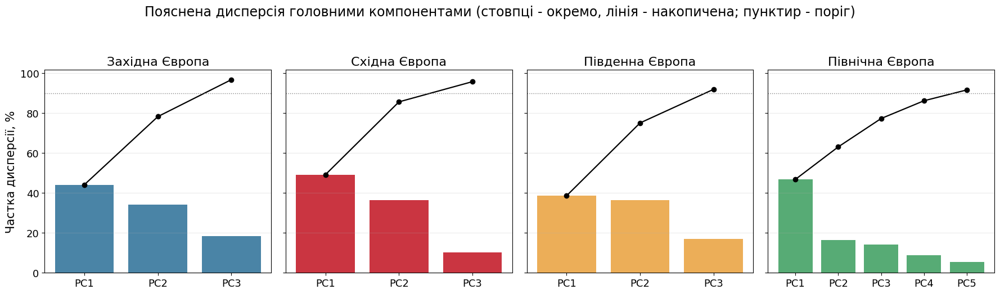

In [13]:
# ===== Навантаження головних компонент (коефіцієнти власних векторів) на Train кожної підвибірки =====
LOAD, EVAR = pca_report("eigen")

# зведена таблиця частки дисперсії по компонентах для всіх підвибірок (для тексту)
summ = pd.DataFrame({REG_LABEL[r]: EVAR[r]["Частка дисперсії, %"] for r in REGIONS}).T
summ["Разом, %"] = summ.sum(axis=1)
display(summ.round(1)); summ.to_csv(TABLES_DIR / "pca_explained_variance_summary.csv")

plot_scree(EVAR)

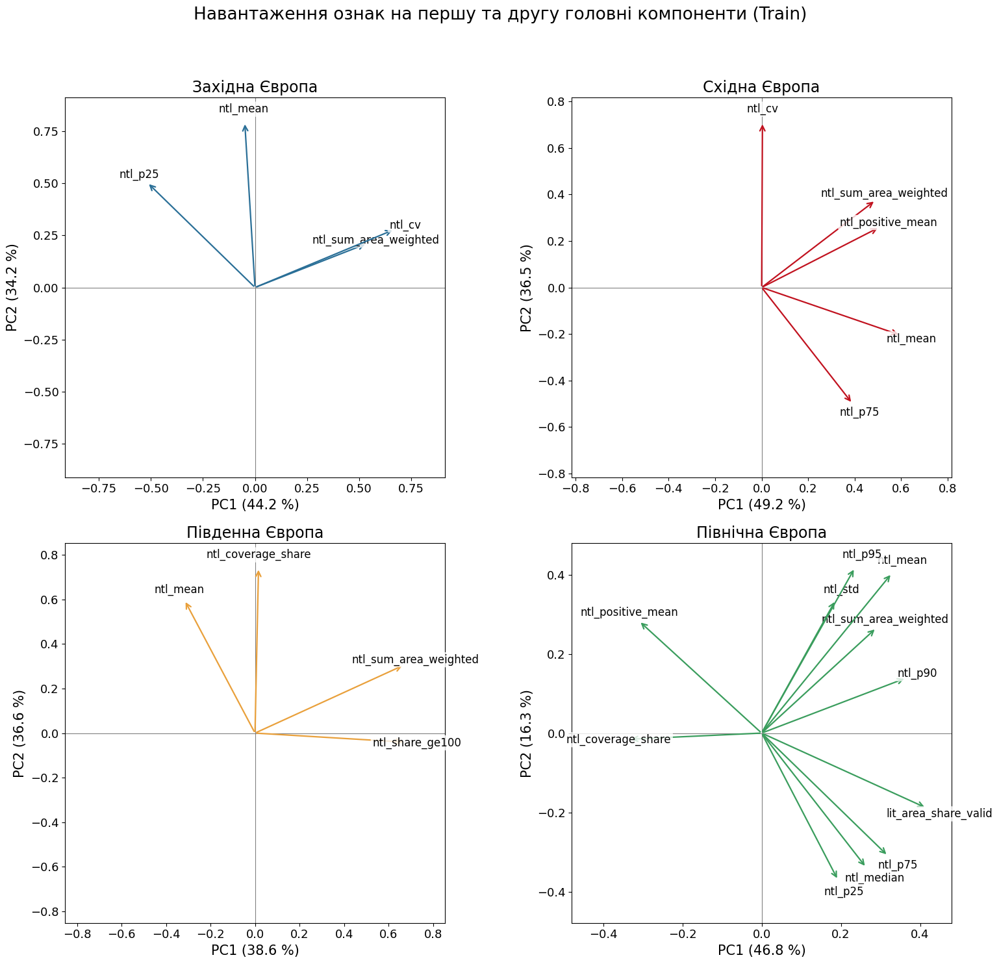

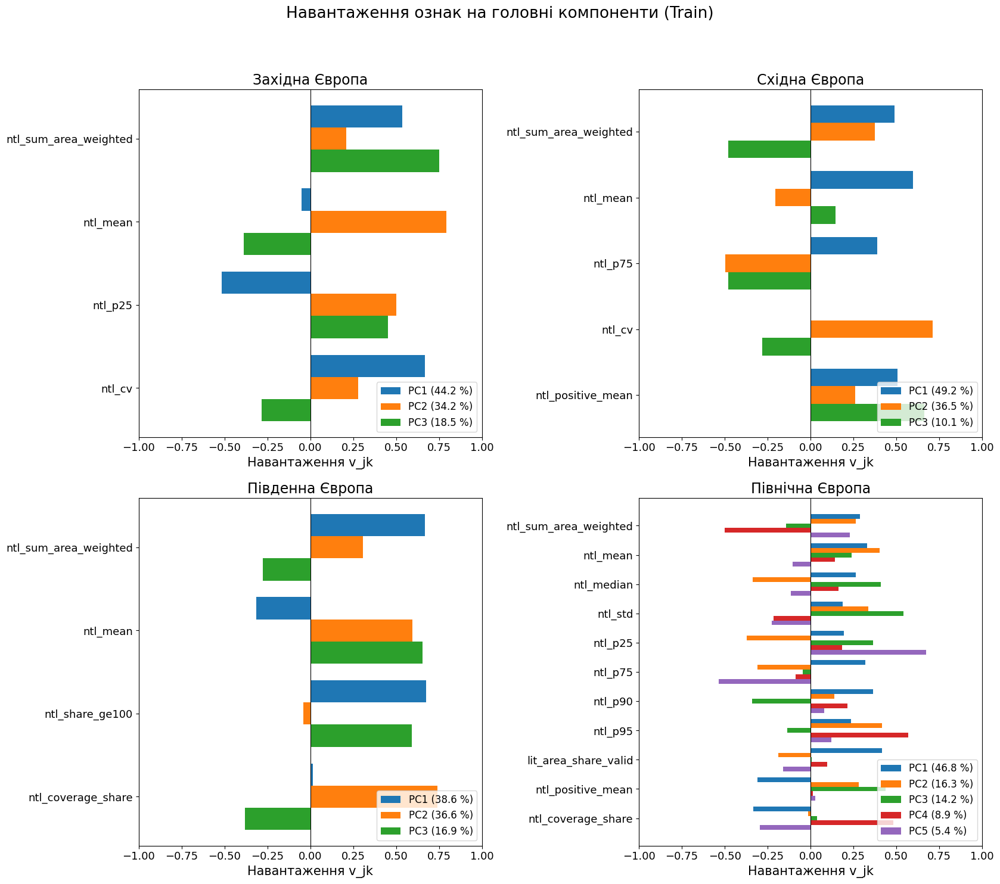

In [14]:
# ===== PCA loading plot: вплив кожної вихідної ознаки на головні компоненти =====
# 1) площина PC1-PC2: стрілки від початку координат до (v_j1, v_j2)
fig, axes = plt.subplots(2, 2, figsize=(16, 15))
for ax, r in zip(axes.ravel(), REGIONS):
    L, ev = LOAD[r], EVAR[r]["Частка дисперсії, %"]
    lim = 1.15 * max(L[["PC1", "PC2"]].abs().max().max(), 0.2)
    ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8)
    for f, row in L[["PC1", "PC2"]].iterrows():
        ax.annotate("", xy=(row["PC1"], row["PC2"]), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="->", color=REG_COLOR[r], lw=1.6))
        ax.text(row["PC1"] * 1.08, row["PC2"] * 1.08, f, fontsize=12, ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.set_xlabel(f"PC1 ({ev.iloc[0]:.1f} %)", fontsize=15); ax.set_ylabel(f"PC2 ({ev.iloc[1]:.1f} %)", fontsize=15)
    ax.tick_params(labelsize=13)
    ax.set_title(REG_LABEL[r], fontsize=17)
fig.suptitle("Навантаження ознак на першу та другу головні компоненти (Train)", y=0.99, fontsize=19)
fig.tight_layout(rect=[0, 0, 1, 0.96])
save_show(fig, "fig_pca_loading_plot_pc1_pc2.png", tight=False)

# 2) стовпчасті навантаження для всіх компонент кожної підвибірки
fig, axes = plt.subplots(2, 2, figsize=(17, 15))
for ax, r in zip(axes.ravel(), REGIONS):
    L, ev = LOAD[r], EVAR[r]["Частка дисперсії, %"]
    h = 0.8 / L.shape[1]; y = np.arange(len(L))
    for k, pc in enumerate(L.columns):
        ax.barh(y + (k - (L.shape[1] - 1) / 2) * h, L[pc], height=h, label=f"{pc} ({ev.iloc[k]:.1f} %)")
    ax.set_yticks(y); ax.set_yticklabels(L.index, fontsize=13); ax.invert_yaxis()
    ax.axvline(0, color="black", lw=0.8); ax.set_xlim(-1, 1)
    ax.set_xlabel("Навантаження v_jk", fontsize=15); ax.set_title(REG_LABEL[r], fontsize=17)
    ax.tick_params(axis="x", labelsize=13)
    ax.legend(fontsize=12, loc="lower right")
fig.suptitle("Навантаження ознак на головні компоненти (Train)", y=0.99, fontsize=19)
fig.tight_layout(rect=[0, 0, 1, 0.96])
save_show(fig, "fig_pca_loadings_bars.png", tight=False)

### Параметри моделей за замовчуванням

Версії бібліотек, повні параметри кожної моделі з `model_registry` і зведена таблиця ключових параметрів, що визначають гнучкість моделі.

In [15]:
# ===== Параметри моделей за замовчуванням (як у model_registry) =====
import importlib.metadata as md


def lib_version(name):
    try:
        return md.version(name)
    except md.PackageNotFoundError:
        return "не встановлено"


print("Версії:", "scikit-learn", lib_version("scikit-learn"), "| xgboost", lib_version("xgboost"),
      "| lightgbm", lib_version("lightgbm"))

# 1) повні параметри кожної моделі
for name, m in model_registry.items():
    print(f"\n{name}: {type(m).__name__}")
    print({k: v for k, v in m.get_params().items()})

# 2) ключові параметри, що впливають на гнучкість моделі
KEY = {
    "Ridge": ["alpha"],
    "SVR": ["kernel", "C", "epsilon", "gamma"],
    "Random Forest": ["n_estimators", "max_depth", "min_samples_leaf", "max_features"],
    "Gradient Boosting": ["n_estimators", "learning_rate", "max_depth", "subsample"],
    "AdaBoost": ["n_estimators", "learning_rate", "estimator"],
    "XGBoost": ["n_estimators", "learning_rate", "max_depth", "subsample"],
    "LightGBM": ["n_estimators", "learning_rate", "num_leaves", "min_child_samples"],
}
rows = []
for name, keys in KEY.items():
    if name in model_registry:
        p = model_registry[name].get_params()
        rows.append({"Модель": name, **{k: p.get(k) for k in keys}})
display(pd.DataFrame(rows).set_index("Модель"))

Версії: scikit-learn 1.6.1 | xgboost 3.4.1 | lightgbm 4.6.0

Linear Regression: LinearRegression
{'copy_X': True, 'fit_intercept': True, 'n_jobs': None, 'positive': False}

Ridge: Ridge
{'alpha': 1.0, 'copy_X': True, 'fit_intercept': True, 'max_iter': None, 'positive': False, 'random_state': None, 'solver': 'auto', 'tol': 0.0001}

SVR: SVR
{'C': 1.0, 'cache_size': 200, 'coef0': 0.0, 'degree': 3, 'epsilon': 0.1, 'gamma': 'scale', 'kernel': 'rbf', 'max_iter': -1, 'shrinking': True, 'tol': 0.001, 'verbose': False}

Random Forest: RandomForestRegressor
{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 1.0, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': 1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}

Gradient Boosting: GradientBoostingRegressor
{'al

,alpha,kernel,C,epsilon,gamma,n_estimators,max_depth,min_samples_leaf,max_features,learning_rate,subsample,estimator,num_leaves,min_child_samples
Модель,,,,,,,,,,,,,,
Ridge,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SVR,NaN,rbf,1.0,0.1,scale,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Random Forest,NaN,NaN,NaN,NaN,NaN,100.0,NaN,1.0,1.0,NaN,NaN,NaN,NaN,NaN
Gradient Boosting,NaN,NaN,NaN,NaN,NaN,100.0,3.0,NaN,NaN,0.1,1.0,NaN,NaN,NaN
AdaBoost,NaN,NaN,NaN,NaN,NaN,50.0,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN
XGBoost,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LightGBM,NaN,NaN,NaN,NaN,NaN,100.0,NaN,NaN,NaN,0.1,NaN,NaN,31.0,20.0


## 6. Моделі: Train → Validation

Кожна модель навчається на Train у трьох наборах ознак: PCA за некорельованими ознаками; вибрані кореляційним аналізом ознаки без PCA; усі ознаки (лише `CORR_TOLERANT`). Tuning для `TOP_K` найкращих використовує rolling-origin CV за роками (навчання на ранніх роках, перевірка на наступному). Результати кожного регіону виводяться один раз, а найкраща модель кожного набору запам'ятовується в `CH2` для наступного розділу.

In [16]:
# ===== моделі на Train -> оцінка на Validation (наступні роки) =====
# некорельовані набори (PCA, вибрані ознаки) - усі моделі; усі ознаки - лише моделі, що витримують кореляцію
FS_MODELS = {FS_PCA: list(model_registry), FS_SEL: list(model_registry), FS_ALL: CORR_TOLERANT}
FN_BASE = {(r, fs): TF[r]["fn"][fs] for r in REGIONS for fs in FS_MODELS}      # функції ознак специфікації «лише світло»

res = run_validation(FN_BASE, with_baseline=True)
res.drop(columns="params").to_csv(TABLES_DIR / "temporal_validation_results.csv", index=False)

CH2 = best_per_set(res)                       # найкраща за Validation RMSE модель у кожному наборі ознак
show_validation(res, CH2)

Західна Європа: готово, 50 с
Східна Європа: готово, 81 с
Південна Європа: готово, 133 с
Північна Європа: готово, 190 с

Західна Європа: Validation 2022-2023


Train RMSE  Val RMSE  \
Набір ознак              Модель                 Етап                            
PCA (некорельовані)      AdaBoost               Default       0.048     0.264   
                         SVR                    Default       0.128     0.290   
                         Linear Regression      Default       0.333     0.373   
                         Ridge                  Default       0.333     0.374   
                         Gradient Boosting      Default       0.011     0.549   
                         Random Forest          Default       0.095     0.550   
                         LightGBM               Default       0.166     0.716   
                         XGBoost                Default       0.001     1.023   
Вибрані ознаки (без PCA) AdaBoost               Default       0.079     0.253   
                         Gradient Boosting      Default       0.011     0.275   
                         Random Forest          Default       0.021     0.280   
                         SVR                    Default       0.096     0.338   
                         Ridge                  Default       0.301     0.394   
                         Linear Regression      Default       0.300     0.402   
                         LightGBM               Default       0.221     0.625   
                         XGBoost                Default       0.001     0.706   
Усі ознаки               Random Forest          Default       0.022     0.186   
                                                Tuned         0.026     0.193   
                         Ridge                  Default       0.100     0.199   
                         Gradient Boosting      Default       0.003     0.199   
                                                Tuned         0.030     0.203   
                         AdaBoost               Default       0.042     0.220   
                         Ridge                  Tuned         0.053     0.253   
                         LightGBM               Default       0.117     0.400   
                         XGBoost                Default       0.001     0.699   
—                        Sum of Lights (базова) —             0.494     0.463   

                                                         Val R2  Val MedAPE_%  \
Набір ознак              Модель                 Етап                            
PCA (некорельовані)      AdaBoost               Default   0.954         9.983   
                         SVR                    Default   0.945        20.944   
                         Linear Regression      Default   0.909        25.518   
                         Ridge                  Default   0.908        25.908   
                         Gradient Boosting      Default   0.802         9.854   
                         Random Forest          Default   0.802        11.560   
                         LightGBM               Default   0.664        31.623   
                         XGBoost                Default   0.314        29.482   
Вибрані ознаки (без PCA) AdaBoost               Default   0.958         6.578   
                         Gradient Boosting      Default   0.951         9.825   
                         Random Forest          Default   0.948         8.607   
                         SVR                    Default   0.925        18.198   
                         Ridge                  Default   0.898        30.152   
                         Linear Regression      Default   0.894        27.772   
                         LightGBM               Default   0.744        19.559   
                         XGBoost                Default   0.673        11.039   
Усі ознаки               Random Forest          Default   0.977         9.941   
                                                Tuned     0.976         9.086   
                         Ridge                  Default   0.974        17.932   
                         Gradient Boosting      Default   0.974        10.558   
      

Найкраща за Validation RMSE у кожному наборі:
  PCA (некорельовані): AdaBoost | Default (Val RMSE = 0.264)
  Вибрані ознаки (без PCA): AdaBoost | Default (Val RMSE = 0.253)
  Усі ознаки: Random Forest | Default (Val RMSE = 0.186)

Східна Європа: Validation 2022-2023


Train RMSE  Val RMSE  \
Набір ознак              Модель                 Етап                            
PCA (некорельовані)      Linear Regression      Default       0.303     0.381   
                         Ridge                  Default       0.303     0.387   
                         SVR                    Default       0.096     0.512   
                         Random Forest          Default       0.082     0.554   
                         Gradient Boosting      Default       0.014     0.606   
                         XGBoost                Default       0.001     0.625   
                         LightGBM               Default       0.301     0.644   
                         AdaBoost               Default       0.095     0.670   
Вибрані ознаки (без PCA) Gradient Boosting      Default       0.010     0.197   
                                                Tuned         0.000     0.243   
                         LightGBM               Default       0.153     0.291   
                         Random Forest          Default       0.037     0.297   
                         Ridge                  Default       0.199     0.306   
                         XGBoost                Default       0.001     0.335   
                         Linear Regression      Default       0.197     0.340   
                         SVR                    Default       0.083     0.516   
                         AdaBoost               Default       0.066     0.521   
Усі ознаки               Gradient Boosting      Default       0.003     0.107   
                         XGBoost                Tuned         0.001     0.199   
                         Gradient Boosting      Tuned         0.000     0.207   
                         XGBoost                Default       0.001     0.212   
                         Random Forest          Default       0.027     0.214   
                         AdaBoost               Default       0.040     0.221   
                         LightGBM               Default       0.115     0.282   
                         Ridge                  Default       0.153     0.358   
—                        Sum of Lights (базова) —             0.298     0.330   

                                                         Val R2  Val MedAPE_%  \
Набір ознак              Модель                 Етап                            
PCA (некорельовані)      Linear Regression      Default   0.739        24.947   
                         Ridge                  Default   0.730        25.265   
                         SVR                    Default   0.527        36.436   
                         Random Forest          Default   0.448        37.565   
                         Gradient Boosting      Default   0.338        50.614   
                         XGBoost                Default   0.297        50.245   
                         LightGBM               Default   0.252        25.842   
                         AdaBoost               Default   0.192        44.579   
Вибрані ознаки (без PCA) Gradient Boosting      Default   0.930        14.897   
                                                Tuned     0.894        19.488   
                         LightGBM               Default   0.847        16.812   
                         Random Forest          Default   0.842        16.844   
                         Ridge                  Default   0.831        16.464   
                         XGBoost                Default   0.797        10.444   
                         Linear Regression      Default   0.792        21.940   
                         SVR                    Default   0.521        29.786   
                         AdaBoost               Default   0.510        13.318   
Усі ознаки               Gradient Boosting      Default   0.980         7.531   
                         XGBoost                Tuned     0.929        20.219   
                         Gradient Boosting      Tuned     0.923        13.284   
      

Найкраща за Validation RMSE у кожному наборі:
  PCA (некорельовані): Linear Regression | Default (Val RMSE = 0.381)
  Вибрані ознаки (без PCA): Gradient Boosting | Default (Val RMSE = 0.197)
  Усі ознаки: Gradient Boosting | Default (Val RMSE = 0.107)

Південна Європа: Validation 2022-2023


Train RMSE  Val RMSE  \
Набір ознак              Модель                 Етап                            
PCA (некорельовані)      AdaBoost               Default       0.145     0.362   
                         LightGBM               Default       0.317     0.609   
                         SVR                    Default       0.674     0.737   
                         Ridge                  Default       0.764     0.792   
                         Linear Regression      Default       0.764     0.793   
                         Random Forest          Default       0.136     0.812   
                         XGBoost                Default       0.002     0.946   
                         Gradient Boosting      Default       0.026     0.967   
Вибрані ознаки (без PCA) Gradient Boosting      Tuned         0.004     0.163   
                                                Default       0.022     0.166   
                         Random Forest          Default       0.063     0.204   
                         AdaBoost               Default       0.141     0.230   
                         SVR                    Default       0.117     0.268   
                         AdaBoost               Tuned         0.168     0.270   
                         XGBoost                Default       0.001     0.288   
                         LightGBM               Default       0.217     0.330   
                         Random Forest          Tuned         0.057     0.331   
                         Ridge                  Default       0.466     0.483   
                         Linear Regression      Default       0.465     0.484   
Усі ознаки               Gradient Boosting      Default       0.013     0.246   
                         XGBoost                Default       0.001     0.275   
                         Random Forest          Default       0.052     0.276   
                         AdaBoost               Default       0.109     0.347   
                         LightGBM               Default       0.105     0.425   
                         Ridge                  Default       0.361     0.447   
—                        Sum of Lights (базова) —             0.569     0.611   

                                                         Val R2  Val MedAPE_%  \
Набір ознак              Модель                 Етап                            
PCA (некорельовані)      AdaBoost               Default   0.961        14.360   
                         LightGBM               Default   0.888        36.556   
                         SVR                    Default   0.836        24.938   
                         Ridge                  Default   0.811        22.454   
                         Linear Regression      Default   0.811        22.037   
                         Random Forest          Default   0.802        17.179   
                         XGBoost                Default   0.731        15.733   
                         Gradient Boosting      Default   0.718        14.583   
Вибрані ознаки (без PCA) Gradient Boosting      Tuned     0.992         9.198   
                                                Default   0.992         8.468   
                         Random Forest          Default   0.987        11.790   
                         AdaBoost               Default   0.984        13.152   
                         SVR                    Default   0.978        17.766   
                         AdaBoost               Tuned     0.978        13.963   
                         XGBoost                Default   0.975        11.921   
                         LightGBM               Default   0.967        20.455   
                         Random Forest          Tuned     0.967        16.561   
                         Ridge                  Default   0.930        25.340   
                         Linear Regression      Default   0.929        24.558   
Усі ознаки               Gradient Boosting      Default   0.982         9.646   
      

Найкраща за Validation RMSE у кожному наборі:
  PCA (некорельовані): AdaBoost | Default (Val RMSE = 0.362)
  Вибрані ознаки (без PCA): Gradient Boosting | Tuned (Val RMSE = 0.163)
  Усі ознаки: Gradient Boosting | Default (Val RMSE = 0.246)

Північна Європа: Validation 2022-2023


Train RMSE  Val RMSE  \
Набір ознак              Модель                 Етап                            
PCA (некорельовані)      Ridge                  Default       0.734     0.771   
                         Linear Regression      Default       0.734     0.776   
                         Random Forest          Default       0.195     0.776   
                         AdaBoost               Default       0.172     0.803   
                         LightGBM               Default       0.294     0.834   
                         SVR                    Default       0.531     0.841   
                         Gradient Boosting      Default       0.047     0.909   
                         XGBoost                Default       0.001     0.923   
Вибрані ознаки (без PCA) Ridge                  Default       0.280     0.482   
                         Linear Regression      Default       0.269     0.532   
                         SVR                    Default       0.222     0.642   
                         Random Forest          Default       0.186     0.964   
                         LightGBM               Default       0.360     0.973   
                         AdaBoost               Default       0.160     1.031   
                         XGBoost                Default       0.001     1.105   
                         Gradient Boosting      Default       0.023     1.126   
Усі ознаки               Gradient Boosting      Tuned         0.001     0.220   
                                                Default       0.012     0.234   
                         XGBoost                Default       0.001     0.244   
                                                Tuned         0.002     0.269   
                         AdaBoost               Default       0.076     0.282   
                         Random Forest          Default       0.050     0.284   
                         LightGBM               Default       0.082     0.303   
                         AdaBoost               Tuned         0.080     0.305   
                         Ridge                  Default       0.214     0.452   
—                        Sum of Lights (базова) —             0.985     1.070   

                                                         Val R2  Val MedAPE_%  \
Набір ознак              Модель                 Етап                            
PCA (некорельовані)      Ridge                  Default   0.678        52.797   
                         Linear Regression      Default   0.674        52.670   
                         Random Forest          Default   0.674        27.008   
                         AdaBoost               Default   0.651        26.221   
                         LightGBM               Default   0.623        54.746   
                         SVR                    Default   0.617        41.217   
                         Gradient Boosting      Default   0.552        28.790   
                         XGBoost                Default   0.539        21.972   
Вибрані ознаки (без PCA) Ridge                  Default   0.874        34.516   
                         Linear Regression      Default   0.847        42.471   
                         SVR                    Default   0.777        46.847   
                         Random Forest          Default   0.497        24.418   
                         LightGBM               Default   0.487        39.106   
                         AdaBoost               Default   0.425        25.488   
                         XGBoost                Default   0.338        21.392   
                         Gradient Boosting      Default   0.313        23.953   
Усі ознаки               Gradient Boosting      Tuned     0.974        15.264   
                                                Default   0.970         9.229   
                         XGBoost                Default   0.968        14.653   
                                                Tuned     0.961        15.319   
      

Найкраща за Validation RMSE у кожному наборі:
  PCA (некорельовані): Ridge | Default (Val RMSE = 0.771)
  Вибрані ознаки (без PCA): Ridge | Default (Val RMSE = 0.482)
  Усі ознаки: Gradient Boosting | Tuned (Val RMSE = 0.220)


## 7. Найкращі моделі кожного набору: Train+Validation → Test

Для кожного регіону і набору ознак береться найкраща за Validation RMSE модель (`CH2`), перенавчається на Train+Validation (відбір ознак, scaler і PCA лишаються навчені на Train) і **один раз** оцінюється на Test. Усі метрики виводяться в одній таблиці разом із базовою моделлю (лінійна регресія ln ВВП на ln Sum of Lights). Далі — діагностичні графіки: прогноз vs факт і залишки, криві навчання, ВВП кожної країни за весь період. Для Train і Validation це in-sample прогноз, лише Test — справжній прогноз на новий період.

`final_by_set` виконує весь цей етап для заданих наборів ознак. Спершу він викликається для наборів PCA і «Вибрані ознаки», потім окремо для набору «Усі ознаки».

Test 2024-2025: найкраща за Validation модель у кожному наборі ознак


Модель  \
Регіон          Набір ознак                                             
Західна Європа  PCA (некорельовані)                AdaBoost | Default   
                Вибрані ознаки (без PCA)           AdaBoost | Default   
Східна Європа   PCA (некорельовані)       Linear Regression | Default   
                Вибрані ознаки (без PCA)  Gradient Boosting | Default   
Південна Європа PCA (некорельовані)                AdaBoost | Default   
                Вибрані ознаки (без PCA)    Gradient Boosting | Tuned   
Північна Європа PCA (некорельовані)                   Ridge | Default   
                Вибрані ознаки (без PCA)              Ridge | Default   

                                          Val RMSE     R2   RMSE  MedAPE  \
Регіон          Набір ознак                                                
Західна Європа  PCA (некорельовані)          0.264  0.991  0.118   6.226   
                Вибрані ознаки (без PCA)     0.253  0.996  0.081   7.931   
Східна Європа   PCA (некорельовані)          0.381  0.856  0.282  11.996   
                Вибрані ознаки (без PCA)     0.197  0.850  0.289   3.504   
Південна Європа PCA (некорельовані)          0.362  0.913  0.534  19.851   
                Вибрані ознаки (без PCA)     0.163  0.962  0.352   8.558   
Північна Європа PCA (некорельовані)          0.771  0.789  0.629  51.275   
                Вибрані ознаки (без PCA)     0.482  0.900  0.432  30.244   

                                            MAE    MAPE  within25  \
Регіон          Набір ознак                                         
Західна Європа  PCA (некорельовані)       0.093   8.878   100.000   
                Вибрані ознаки (без PCA)  0.073   7.019   100.000   
Східна Європа   PCA (некорельовані)       0.224  22.515    66.667   
                Вибрані ознаки (без PCA)  0.126  17.992    91.667   
Південна Європа PCA (некорельовані)       0.359  33.854    59.091   
                Вибрані ознаки (без PCA)  0.194  26.260    77.273   
Північна Європа PCA (некорельовані)       0.542  46.065    22.222   
                Вибрані ознаки (без PCA)  0.342  32.836    38.889   

                                          Baseline R2  Baseline RMSE  \
Регіон          Набір ознак                                            
Західна Європа  PCA (некорельовані)             0.847          0.481   
                Вибрані ознаки (без PCA)        0.847          0.481   
Східна Європа   PCA (некорельовані)             0.735          0.383   
                Вибрані ознаки (без PCA)        0.735          0.383   
Південна Європа PCA (некорельовані)             0.878          0.632   
                Вибрані ознаки (без PCA)        0.878          0.632   
Північна Європа PCA (некорельовані)             0.380          1.077   
                Вибрані ознаки (без PCA)        0.380          1.077   

                                          Baseline MedAPE  Baseline MAE  \
Регіон          Набір ознак                                               
Західна Європа  PCA (некорельовані)                25.541         0.362   
                Вибрані ознаки (без PCA)           25.541         0.362   
Східна Європа   PCA (некорельовані)                29.350         0.322   
                Вибрані ознаки (без PCA)           29.350         0.322   
Південна Європа PCA (некорельовані)                32.237         0.492   
                Вибрані ознаки (без PCA)           32.237         0.492   
Північна Європа PCA (некорельовані)                76.315         0.849   
                Вибрані ознаки (без PCA)           76.315         0.849   

                                          Baseline MAPE  розбиттів  \
Регіон          Набір ознак                                          
Західна Європа  PCA (некорельовані)              28.394          1   
                Вибрані ознаки (без PCA)         28.394          1   
Східна Європа   PCA (некорельовані)              36.052          1   
                Вибрані ознаки (без PCA)         36.052   

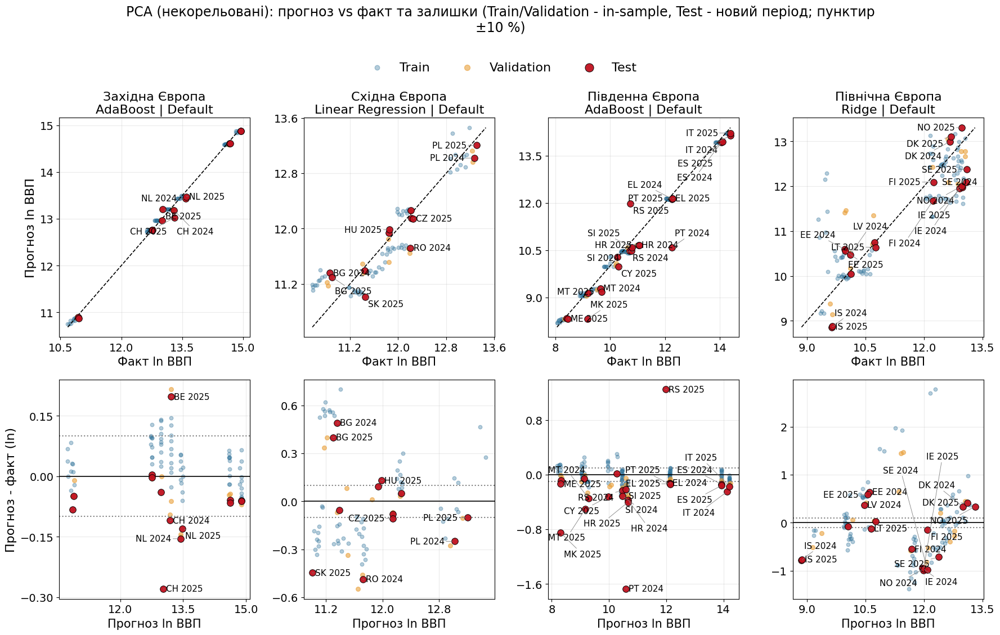

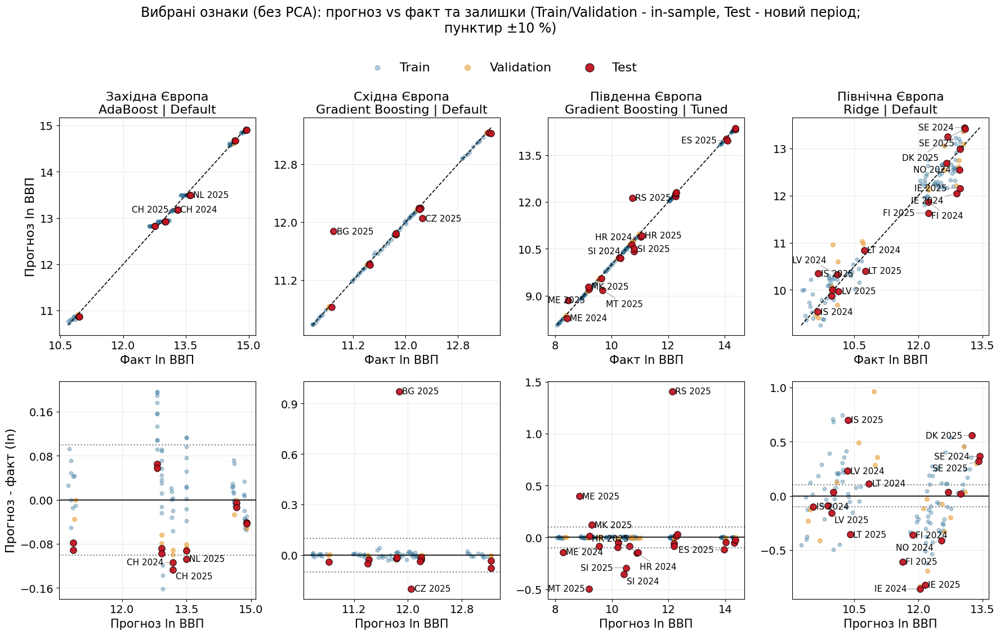

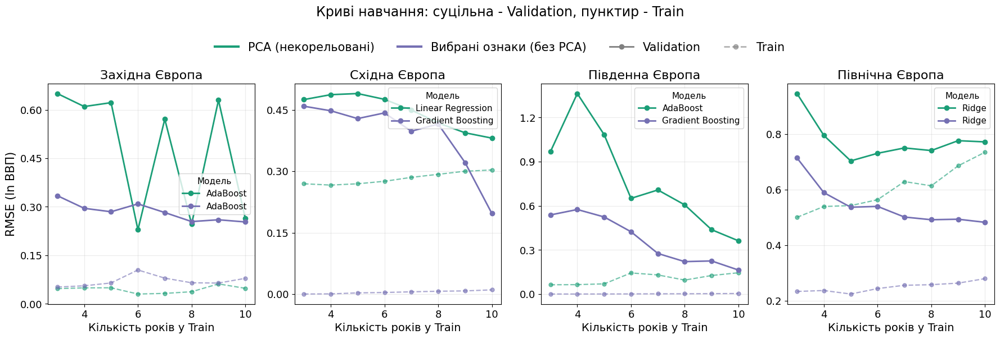

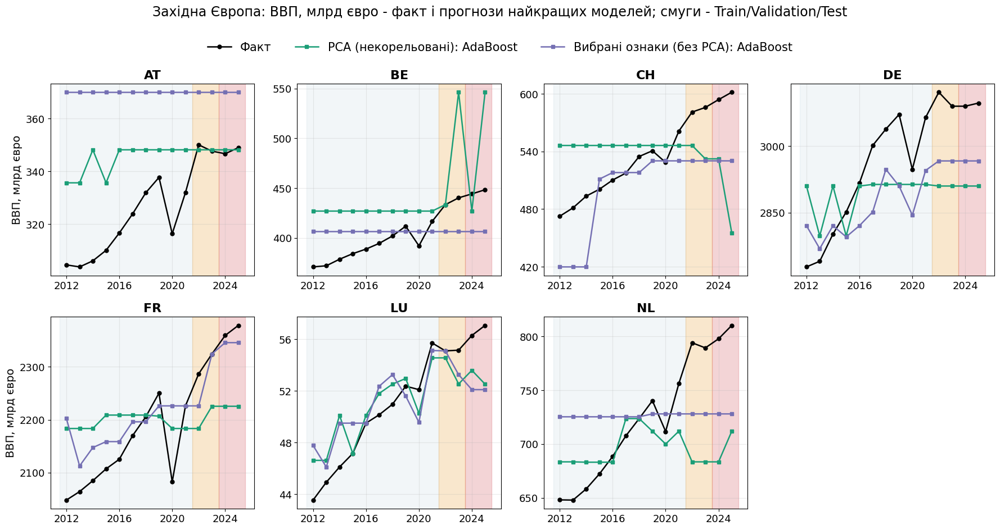

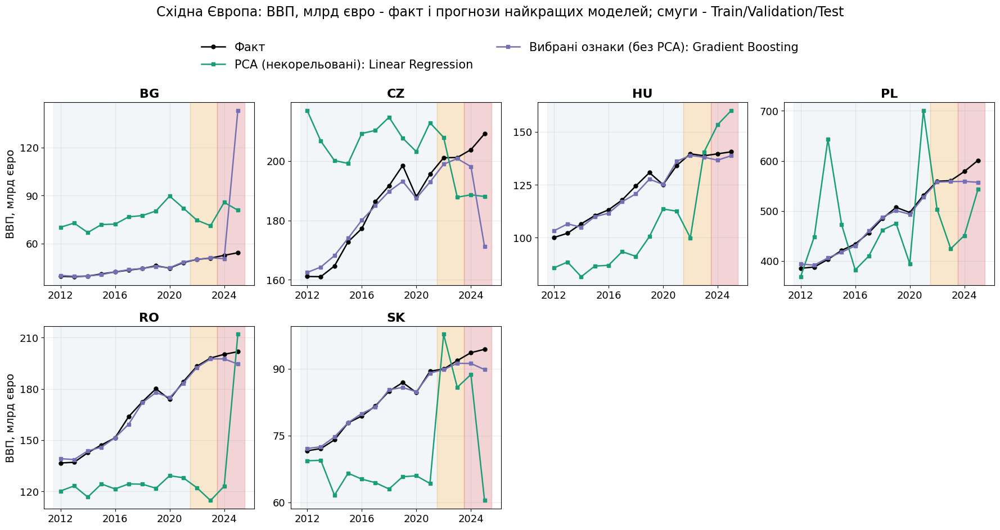

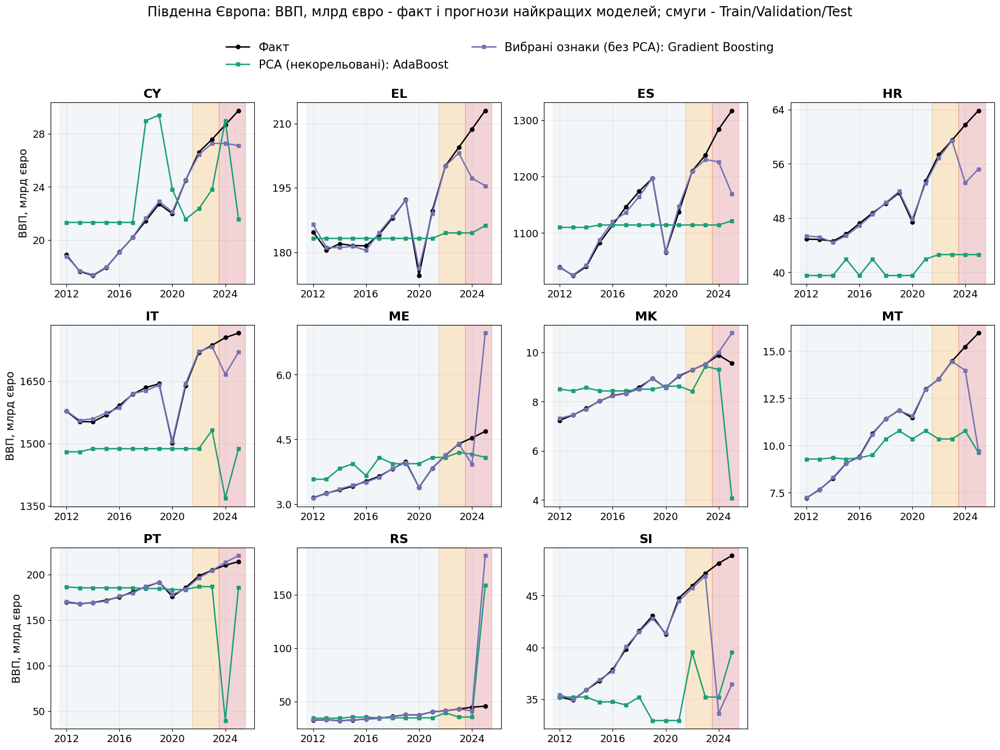

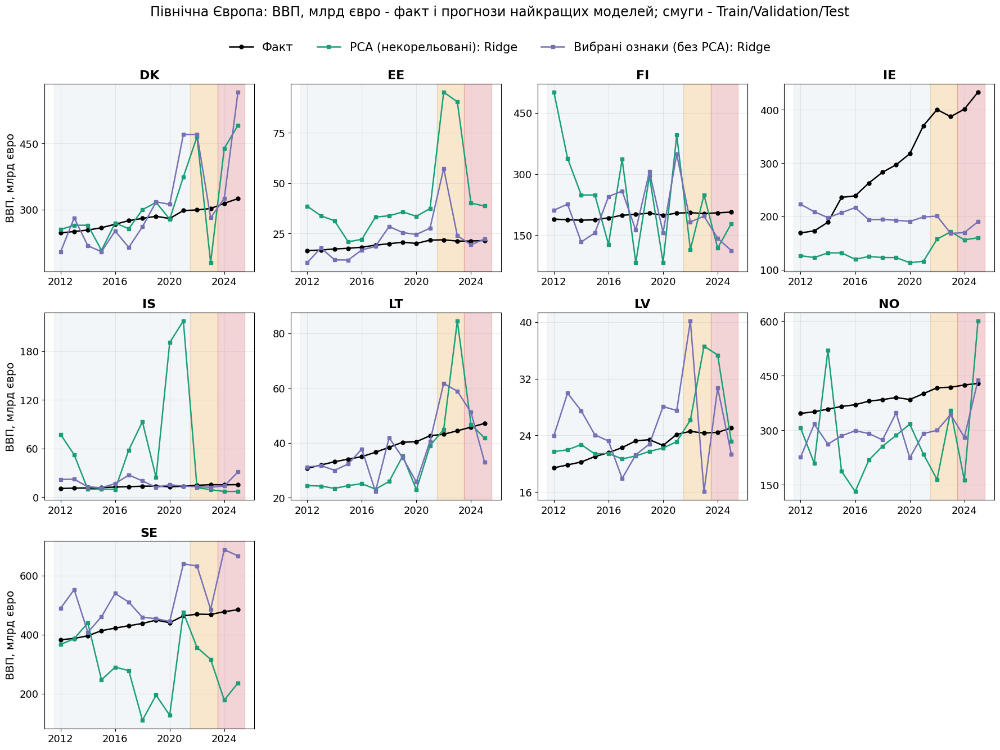

In [17]:
# ===== фінальні моделі (Train+Validation) -> Test, зведена таблиця і діагностичні графіки =====
def final_by_set(sets, csv_name, test_title, ts_fname, ts_title, lc_fname):
    """Найкраща модель (CH2) кожного регіону і набору з sets -> Train+Validation -> Test; таблиця і графіки."""
    # 1) перенавчання і зведена таблиця
    final, rows = {}, []
    for r in REGIONS:
        for fs in sets:
            c = CH2[(r, fs)]                                  # ознаки, scaler, PCA - навчені на Train
            final[(r, fs)] = d = fit_final(r, c["model"], c["params"], FN_BASE[(r, fs)])
            rows.append({"Регіон": REG_LABEL[r], "Набір ознак": fs, "Модель": f'{c["model"]} | {c["stage"]}',
                         "Val RMSE": c["val_rmse"], **test_metrics(d)})
    summary = pd.DataFrame(rows).set_index(["Регіон", "Набір ознак"])
    summary.to_csv(TABLES_DIR / csv_name)
    print(f"Test {test_years[0]}-{test_years[-1]}: найкраща за Validation модель {test_title}")
    display(summary.round(3))

    # 2) прогноз vs факт і залишки (по одному рисунку на набір ознак, з підписами викидів на Test)
    for fs in sets:
        plot_pred_vs_actual(
            {r: final[(r, fs)] for r in REGIONS},
            {r: f'{REG_LABEL[r]}\n{CH2[(r, fs)]["model"]} | {CH2[(r, fs)]["stage"]}' for r in REGIONS},
            f"{fs}: прогноз vs факт та залишки (Train/Validation - in-sample, Test - новий період; пунктир ±10 %)",
            f"fig_temporal_best_{SET_SLUG[fs]}_scatter_residuals.png", label_outliers=True)

    # 3) криві навчання (суцільна - Validation, пунктир - Train); модель навчається на перших k роках Train
    plot_learning_curves(
        {r: [dict(model=CH2[(r, fs)]["model"], params=CH2[(r, fs)]["params"], fn=FN_BASE[(r, fs)],
                  color=SET_COLOR[fs], group=fs) for fs in sets] for r in REGIONS},
        "Криві навчання: суцільна - Validation, пунктир - Train", lc_fname)

    # 4) ВВП кожної країни: факт і прогнози за весь період (млрд євро)
    for r in REGIONS:
        plot_country_timeseries(
            r, [dict(d=final[(r, fs)], fmt="-s", color=SET_COLOR[fs], label=f'{fs}: {CH2[(r, fs)]["model"]}') for fs in sets],
            f"{REG_LABEL[r]}: ВВП, млрд євро - факт і {ts_title}; смуги - Train/Validation/Test",
            ts_fname.format(r=r))
    return final, summary


FINAL_SETS = [FS_PCA, FS_SEL]            # набори ознак, для яких будуються фінальні моделі
FINAL, summary_t = final_by_set(
    FINAL_SETS, "temporal_test_summary_best_models.csv", "у кожному наборі ознак",
    "fig_temporal_best_country_timeseries_{r}.png", "прогнози найкращих моделей",
    "fig_temporal_best_learning_curves.png")

Test 2024-2025: найкраща за Validation модель у наборі «Усі ознаки»


,,Модель,Val RMSE,R2,RMSE,MedAPE,MAE,MAPE,within25,Baseline R2,Baseline RMSE,Baseline MedAPE,Baseline MAE,Baseline MAPE,розбиттів,MedAPE [Q25; Q75],краща за baseline (RMSE),within10
Регіон,Набір ознак,,,,,,,,,,,,,,,,,
Західна Європа,Усі ознаки,Random Forest | Default,0.186,0.997,0.067,5.969,0.057,5.588,100.000,0.847,0.481,25.541,0.362,28.394,1,6.0 [3.2; 7.5],так,92.857
Східна Європа,Усі ознаки,Gradient Boosting | Default,0.107,0.905,0.229,5.069,0.135,14.766,83.333,0.735,0.383,29.350,0.322,36.052,1,5.1 [2.8; 11.0],так,75.000
Південна Європа,Усі ознаки,Gradient Boosting | Default,0.246,0.947,0.415,7.665,0.206,33.899,86.364,0.878,0.632,32.237,0.492,51.878,1,7.7 [5.3; 12.3],так,63.636
Північна Європа,Усі ознаки,Gradient Boosting | Tuned,0.220,0.988,0.153,3.773,0.091,8.183,88.889,0.380,1.077,76.315,0.849,122.631,1,3.8 [2.3; 7.5],так,77.778


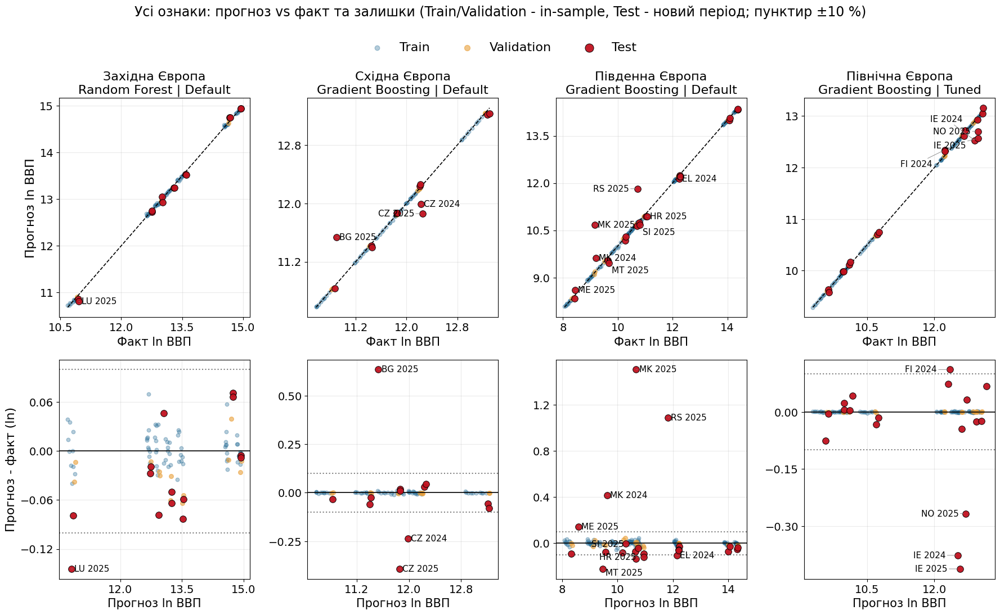

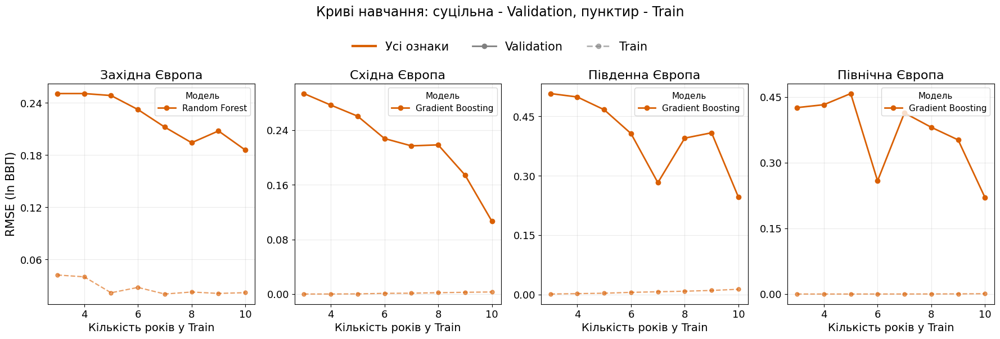

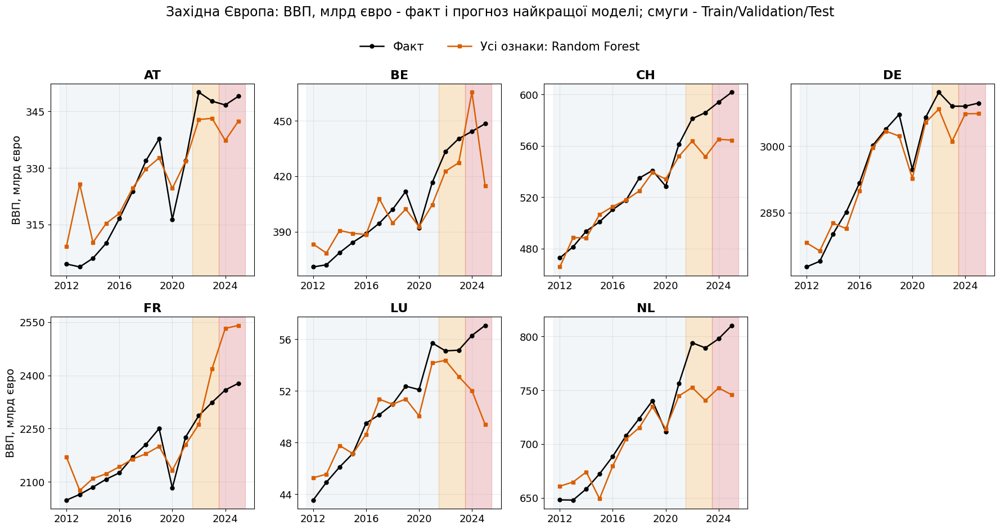

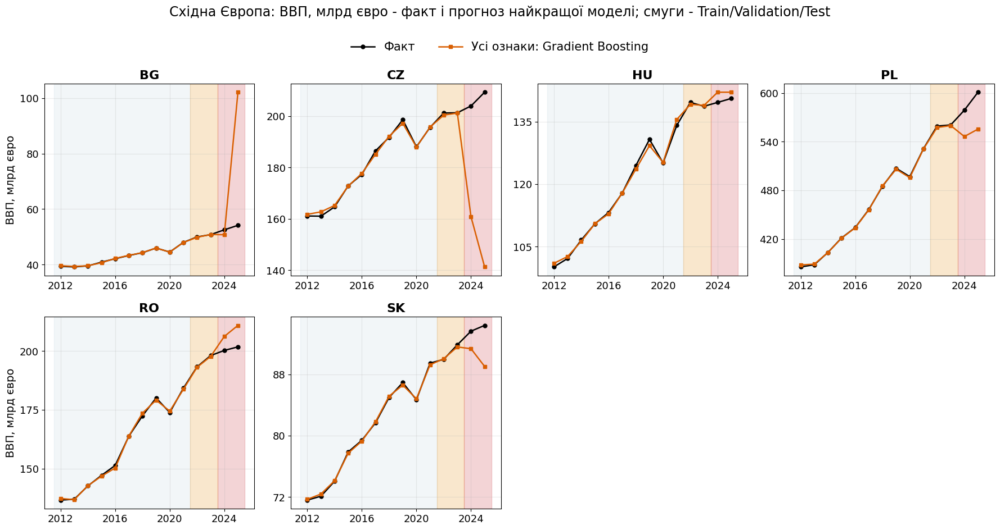

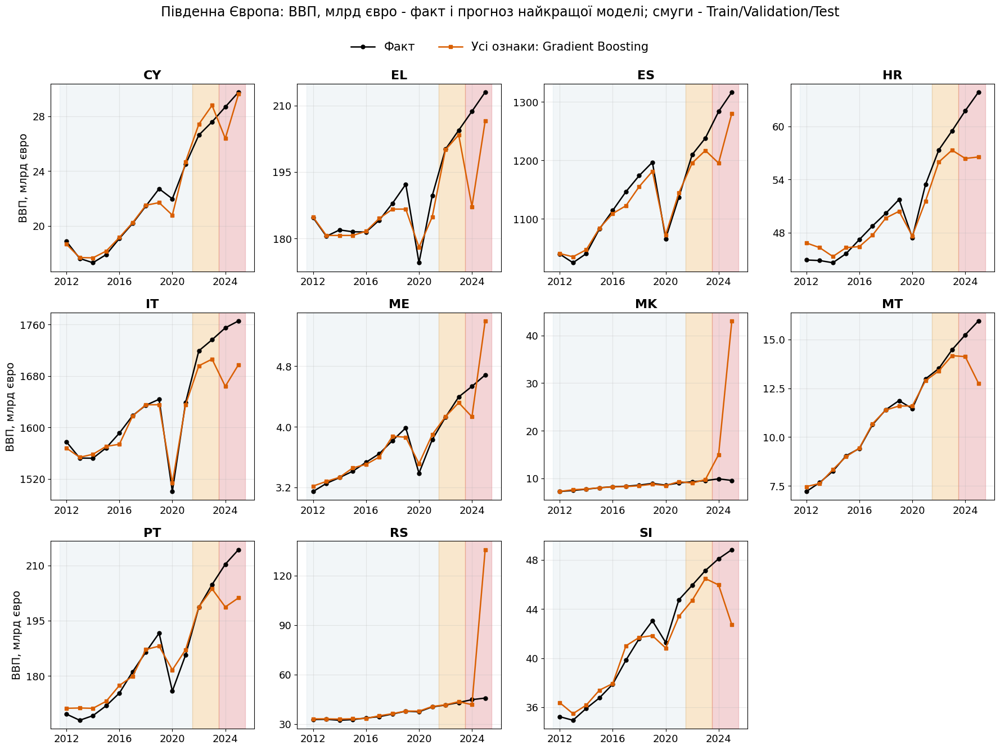

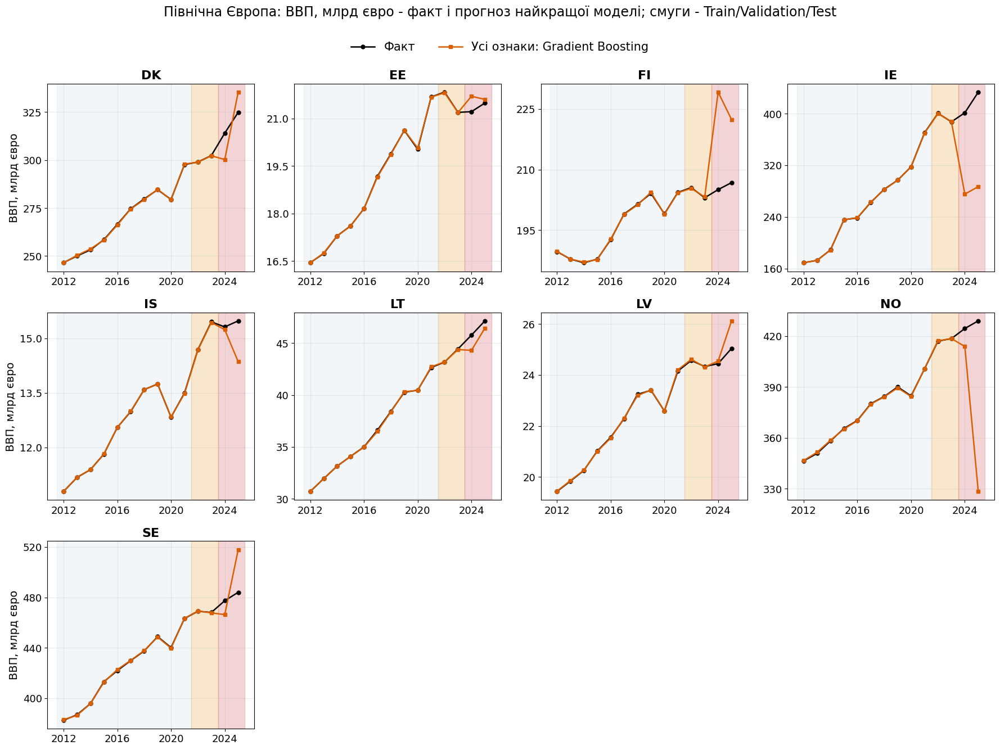

In [18]:
# ===== набір «Усі ознаки»: фінальні моделі (Train+Validation) -> Test, зведена таблиця і діагностичні графіки =====
FINAL_SETS = [FS_ALL]                    # лише набір «Усі ознаки»: найкраща за Validation RMSE модель у кожному регіоні
FINAL_ALL, summary_all = final_by_set(
    FINAL_SETS, "temporal_test_summary_best_models_all_features.csv", "у наборі «Усі ознаки»",
    "fig_temporal_best_all_country_timeseries_{r}.png", "прогноз найкращої моделі",
    "fig_temporal_best_all_learning_curves.png")

## 8. Діагностика стрибка світла в останні роки

Чи виходять ознаки світла Test за межі діапазону Train для окремої країни, як змінювався Sum of Lights по роках і чи пов'язані стрибки з показниками якості даних.

In [19]:
r, cn = "East", "BG"          # змінити на країну зі стрибком
d = region_data(r)
tr = d[(d["role"] == "Train") & (d["CNTR_ID"] == cn)]
x = d[d["CNTR_ID"] == cn].set_index("year")[feats]
lo, hi = tr[feats].min(), tr[feats].max()
chk = x.loc[[2023, 2024, 2025]]
out = (chk > hi) | (chk < lo)
print("Ознаки Test за межами діапазону Train цієї країни:")
display(chk.loc[:, out.any()].round(3))
display(x.loc[2019:2025, ["ntl_sum_area_weighted", "lit_area_km2", "ntl_coverage_share"]].round(3))

Ознаки Test за межами діапазону Train цієї країни:


,ntl_sum_area_weighted,ntl_mean,ntl_mean_area_weighted,ntl_std,ntl_p90,ntl_p95,ntl_cv,lit_area_km2,lit_area_share_valid,ntl_positive_mean,ntl_sum_cap50,ntl_sum_cap100,ntl_sum_log1p,lit_area_km2_t1,lit_area_km2_t2,lit_area_km2_t5,ntl_share_ge100
year,,,,,,,,,,,,,,,,,
2023,56727.796,0.511,0.512,3.006,0.813,1.793,5.879,21313.692,0.192,2.661,55432.880,56568.149,19280.380,9057.828,5033.361,2189.719,0.013
2024,57016.636,0.514,0.514,3.232,0.749,1.893,6.286,16561.617,0.149,3.440,55335.655,56781.018,17269.459,8824.433,5306.219,2368.551,0.017
2025,71031.330,0.640,0.641,3.487,1.001,2.255,5.445,27566.480,0.249,2.577,68913.672,70657.534,24320.649,11092.484,6172.038,2645.378,0.017


,ntl_sum_area_weighted,lit_area_km2,ntl_coverage_share
year,,,
2019,44396.267,12349.043,0.999
2020,45015.628,11480.665,0.999
2021,48720.615,13802.857,0.999
2022,51988.741,17623.399,0.999
2023,56727.796,21313.692,0.999
2024,57016.636,16561.617,0.999
2025,71031.330,27566.480,0.999


In [20]:
chg = (model_data.pivot_table(index="CNTR_ID", columns="year", values="ntl_sum_area_weighted")
       .pipe(lambda p: p.pct_change(axis=1) * 100))
print("Річна зміна Sum of Lights, %: медіана по країнах")
display(chg.median().round(1).to_frame("медіана").T)
print("BG і найбільші зміни у 2025:")
display(chg[2025].sort_values(ascending=False).head(8).round(1))

Річна зміна Sum of Lights, %: медіана по країнах


year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
медіана,NaN,-3.1,-1.2,-0.5,0.8,1.5,1.9,-0.4,-2.1,6.7,5.0,-1.5,-0.0,6.1


BG і найбільші зміни у 2025:


,2025
CNTR_ID,
MK,33.7
ME,25.2
BG,24.6
IS,24.0
EL,17.0
PT,13.5
CY,13.2
RS,12.8


In [21]:
qa_cols = [c for c in dataset.columns if re.search(r"valid|qa|obs|n_pix|quality|good", c, re.I)]
print("Колонки про якість:", qa_cols)
cn = ["BG", "MK", "ME", "BA", "EL", "CY", "PT", "IS", "RO", "HU"]      # кластер зі стрибком і для порівняння кілька країн без стрибка
display(dataset[dataset["CNTR_ID"].isin(cn) & dataset["year"].between(2022, 2025)]
        .pivot_table(index="CNTR_ID", columns="year", values=qa_cols[:6]).round(3))

Колонки про якість: ['n_valid_pixels', 'valid_ntl_area_km2', 'lit_area_share_valid', 'mean_n_observations', 'invalid_radiance_km2', 'qa0_km2', 'qa1_km2', 'qa2_km2', 'invalid_radiance_share', 'qa0_share', 'qa1_share', 'qa2_share', 'valid_ntl_area_km2_qa01', 'ntl_mean_area_weighted_qa01', 'ntl_sum_area_weighted_qa01', 'ntl_coverage_share_qa01', 'valid_ntl_area_km2_mainland']


invalid_radiance_km2                lit_area_share_valid         \
year                    2022 2023 2024 2025                 2022   2023   
CNTR_ID                                                                   
BG                       0.0  0.0  0.0  0.0                0.159  0.192   
CY                       0.0  0.0  0.0  0.0                0.470  0.563   
EL                       0.0  0.0  0.0  0.0                0.300  0.352   
HU                       0.0  0.0  0.0  0.0                0.232  0.263   
IS                       0.0  0.0  0.0  0.0                0.733  0.604   
ME                       0.0  0.0  0.0  0.0                0.184  0.196   
MK                       0.0  0.0  0.0  0.0                0.156  0.174   
PT                       0.0  0.0  0.0  0.0                0.456  0.491   
RO                       0.0  0.0  0.0  0.0                0.214  0.248   

                      mean_n_observations          ... n_valid_pixels  \
year      2024   2025                2022    2023  ...           2024   
CNTR_ID                                            ...                  
BG       0.149  0.249              46.461  46.615  ...       702330.0   
CY       0.483  0.587              64.950  67.609  ...        52776.0   
EL       0.275  0.422              52.177  54.077  ...       787652.0   
HU       0.259  0.261              34.732  38.248  ...       631909.0   
IS       0.615  0.799              14.203  11.093  ...      1074205.0   
ME       0.152  0.265              41.294  46.437  ...        86745.0   
MK       0.151  0.268              52.563  45.940  ...       155665.0   
PT       0.416  0.560              49.029  56.871  ...       553855.0   
RO       0.236  0.275              34.669  36.617  ...      1585211.0   

                       qa0_km2                                      \
year          2025        2022        2023        2024        2025   
CNTR_ID                                                              
BG        702313.0  110878.140  110875.816  110873.443  110870.705   
CY         52770.0    9273.194    9273.899    9273.718    9272.662   
EL        786910.0  131236.636  131280.166  131369.015  131243.652   
HU        631991.0   92486.095   92488.184   92466.488   92478.529   
IS        966839.0   73398.466   91237.673   98143.506   88337.007   
ME         86718.0   13686.337   13685.230   13686.822   13682.526   
MK        155635.0   25017.780   25018.585   25019.080   25014.236   
PT        553740.0   91656.777   91677.500   91666.340   91647.338   
RO       1585221.0  237599.620  237589.607  237577.840  237579.459   

        valid_ntl_area_km2                                      
year                  2022        2023        2024        2025  
CNTR_ID                                                         
BG              110878.140  110875.816  110873.443  110870.705  
CY                9273.194    9273.899    9273.718    9272.662  
EL              131236.636  131280.166  131369.015  131243.652  
HU               92486.095   92488.184   92466.488   92478.529  
IS               73398.466   91237.673   98143.506   88337.007  
ME               13686.337   13685.230   13686.822   13682.526  
MK               25017.780   25018.585   25019.080   25014.236  
PT               91656.777   91677.500   91666.340   91647.338  
RO              237599.620  237589.607  237577.840  237579.459  

[9 rows x 24 columns]

## 9. Світло + додаткові змінні

Той самий протокол Train → Validation, але до кожного набору ознак світла додаються додаткові змінні (ln населення, широта, ln площі), стандартизовані за Train регіону. Наприкінці — порівняння найкращої Validation RMSE з специфікацією «лише світло».

In [23]:
# ===== світло + додаткові змінні: усі моделі, всі набори ознак, усі регіони (Train -> Validation) =====
STRUCT_USE = STRUCT_NOREG                      # ["ln_population", "latitude", "ln_area"]

# додаткові змінні стандартизуються за Train регіону і додаються до кожного набору ознак
SC_ST, FN_ST = {}, {}
for r in REGIONS:
    SC_ST[r] = StandardScaler().fit(region_data(r, "Train")[STRUCT_USE])
    for fs in FS_MODELS:
        FN_ST[(r, fs)] = (lambda x, _r=r, _fs=fs: np.hstack([TF[_r]["fn"][_fs](x), SC_ST[_r].transform(x[STRUCT_USE])]))

res_st = run_validation(FN_ST)
res_st.drop(columns="params").to_csv(TABLES_DIR / "temporal_validation_results_structural.csv", index=False)

CH2_ST = best_per_set(res_st)
show_validation(res_st, CH2_ST, suffix=f" + додаткові змінні ({', '.join(STRUCT_USE)})")

# зведене порівняння найкращої Val RMSE у наборі: базові ознаки / + додаткові змінні
cmp_st = pd.DataFrame([
    {"Регіон": REG_LABEL[r], "Набір ознак": fs,
     "Базові": CH2[(r, fs)]["val_rmse"], "Модель (базові)": CH2[(r, fs)]["model"],
     "+ додаткові": CH2_ST[(r, fs)]["val_rmse"], "Модель (+структ.)": CH2_ST[(r, fs)]["model"]}
    for r in REGIONS for fs in FS_MODELS]).set_index(["Регіон", "Набір ознак"])
display(cmp_st.round(3)); cmp_st.to_csv(TABLES_DIR / "temporal_structural_vs_baseline_val_rmse.csv")

Західна Європа: готово, 55 с
Східна Європа: готово, 70 с
Південна Європа: готово, 112 с
Північна Європа: готово, 158 с

Західна Європа + додаткові змінні (ln_population, latitude, ln_area): Validation 2022-2023


Train RMSE  Val RMSE  \
Набір ознак              Модель            Етап                            
PCA (некорельовані)      Linear Regression Default       0.066     0.173   
                         SVR               Default       0.081     0.185   
                         Gradient Boosting Default       0.004     0.194   
                         Ridge             Default       0.167     0.204   
                         XGBoost           Default       0.001     0.269   
                         Random Forest     Default       0.027     0.278   
                         AdaBoost          Default       0.049     0.279   
                         LightGBM          Default       0.078     0.358   
Вибрані ознаки (без PCA) Gradient Boosting Default       0.004     0.081   
                                           Tuned         0.008     0.123   
                         Linear Regression Default       0.056     0.128   
                         Random Forest     Default       0.014     0.160   
                         AdaBoost          Default       0.051     0.170   
                         Random Forest     Tuned         0.021     0.177   
                         SVR               Default       0.073     0.234   
                         Ridge             Default       0.152     0.268   
                         LightGBM          Default       0.120     0.319   
                         XGBoost           Default       0.001     0.668   
Усі ознаки               Gradient Boosting Default       0.002     0.141   
                                           Tuned         0.029     0.157   
                         Random Forest     Default       0.021     0.181   
                         Ridge             Default       0.076     0.182   
                         LightGBM          Default       0.109     0.188   
                         AdaBoost          Default       0.111     0.216   
                         XGBoost           Default       0.001     0.675   

                                                    Val R2  Val MedAPE_%  \
Набір ознак              Модель            Етап                            
PCA (некорельовані)      Linear Regression Default   0.980        11.226   
                         SVR               Default   0.978        12.412   
                         Gradient Boosting Default   0.975         6.218   
                         Ridge             Default   0.973        16.186   
                         XGBoost           Default   0.952         4.931   
                         Random Forest     Default   0.949         6.998   
                         AdaBoost          Default   0.949         8.876   
                         LightGBM          Default   0.916         5.659   
Вибрані ознаки (без PCA) Gradient Boosting Default   0.996         5.066   
                                           Tuned     0.990         5.507   
                         Linear Regression Default   0.989         9.311   
                         Random Forest     Default   0.983         6.798   
                         AdaBoost          Default   0.981         7.148   
                         Random Forest     Tuned     0.979         7.124   
                         SVR               Default   0.964        15.179   
                         Ridge             Default   0.953        19.982   
                         LightGBM          Default   0.933         6.565   
                         XGBoost           Default   0.708         8.899   
Усі ознаки               Gradient Boosting Default   0.987         4.671   
                                           Tuned     0.984         6.794   
                         Random Forest     Default   0.979         8.775   
                         Ridge             Default   0.978        12.919   
                         LightGBM          Default   0.977         6.894   
                         AdaBoost          Default   0.970         9.494   
                       

Найкраща за Validation RMSE у кожному наборі:
  PCA (некорельовані): Linear Regression | Default (Val RMSE = 0.173)
  Вибрані ознаки (без PCA): Gradient Boosting | Default (Val RMSE = 0.081)
  Усі ознаки: Gradient Boosting | Default (Val RMSE = 0.141)

Східна Європа + додаткові змінні (ln_population, latitude, ln_area): Validation 2022-2023


Train RMSE  Val RMSE  \
Набір ознак              Модель            Етап                            
PCA (некорельовані)      Gradient Boosting Default       0.009     0.153   
                         Ridge             Default       0.112     0.160   
                         Random Forest     Default       0.026     0.168   
                         AdaBoost          Default       0.064     0.176   
                         Linear Regression Default       0.107     0.183   
                         LightGBM          Default       0.085     0.254   
                         SVR               Default       0.074     0.415   
                         XGBoost           Default       0.001     0.507   
Вибрані ознаки (без PCA) Linear Regression Default       0.090     0.095   
                         Ridge             Tuned         0.090     0.097   
                         Gradient Boosting Tuned         0.000     0.108   
                         Ridge             Default       0.108     0.123   
                         Gradient Boosting Default       0.006     0.137   
                         Random Forest     Default       0.025     0.147   
                         LightGBM          Default       0.084     0.190   
                         AdaBoost          Default       0.059     0.233   
                         XGBoost           Default       0.001     0.354   
                         SVR               Default       0.072     0.441   
Усі ознаки               Ridge             Default       0.066     0.126   
                                           Tuned         0.055     0.153   
                         LightGBM          Default       0.068     0.160   
                         AdaBoost          Default       0.044     0.171   
                         Random Forest     Default       0.026     0.178   
                         Gradient Boosting Default       0.003     0.184   
                         XGBoost           Default       0.001     0.212   

                                                    Val R2  Val MedAPE_%  \
Набір ознак              Модель            Етап                            
PCA (некорельовані)      Gradient Boosting Default   0.958        13.193   
                         Ridge             Default   0.954         8.939   
                         Random Forest     Default   0.949        10.881   
                         AdaBoost          Default   0.944        14.004   
                         Linear Regression Default   0.940        15.813   
                         LightGBM          Default   0.884        19.303   
                         SVR               Default   0.690        18.612   
                         XGBoost           Default   0.537        13.905   
Вибрані ознаки (без PCA) Linear Regression Default   0.984         6.381   
                         Ridge             Tuned     0.983         6.258   
                         Gradient Boosting Tuned     0.979         7.801   
                         Ridge             Default   0.973        10.358   
                         Gradient Boosting Default   0.966        12.808   
                         Random Forest     Default   0.961        11.495   
                         LightGBM          Default   0.935        16.400   
                         AdaBoost          Default   0.902        13.305   
                         XGBoost           Default   0.775        10.616   
                         SVR               Default   0.649        18.572   
Усі ознаки               Ridge             Default   0.971         9.868   
                                           Tuned     0.958        12.581   
                         LightGBM          Default   0.954        10.751   
                         AdaBoost          Default   0.947         9.553   
                         Random Forest     Default   0.943        13.617   
                         Gradient Boosting Default   0.939        10.897   
                       

Найкраща за Validation RMSE у кожному наборі:
  PCA (некорельовані): Gradient Boosting | Default (Val RMSE = 0.153)
  Вибрані ознаки (без PCA): Linear Regression | Default (Val RMSE = 0.095)
  Усі ознаки: Ridge | Default (Val RMSE = 0.126)

Південна Європа + додаткові змінні (ln_population, latitude, ln_area): Validation 2022-2023


Train RMSE  Val RMSE  \
Набір ознак              Модель            Етап                            
PCA (некорельовані)      LightGBM          Default       0.073     0.210   
                         SVR               Default       0.247     0.263   
                         Gradient Boosting Default       0.017     0.293   
                         XGBoost           Default       0.001     0.312   
                         AdaBoost          Default       0.117     0.375   
                         Random Forest     Default       0.028     0.377   
                         Ridge             Default       0.387     0.409   
                         Linear Regression Default       0.383     0.411   
Вибрані ознаки (без PCA) XGBoost           Default       0.001     0.122   
                         Gradient Boosting Tuned         0.029     0.131   
                         Random Forest     Default       0.062     0.138   
                         Gradient Boosting Default       0.016     0.139   
                         LightGBM          Default       0.070     0.159   
                         Random Forest     Tuned         0.074     0.175   
                         XGBoost           Tuned         0.007     0.181   
                         AdaBoost          Default       0.100     0.188   
                         SVR               Default       0.100     0.188   
                         Linear Regression Default       0.354     0.342   
                         Ridge             Default       0.389     0.410   
Усі ознаки               LightGBM          Default       0.053     0.145   
                         Gradient Boosting Default       0.010     0.177   
                         Random Forest     Default       0.057     0.201   
                         XGBoost           Default       0.001     0.278   
                         AdaBoost          Default       0.106     0.368   
                         Ridge             Default       0.252     0.458   

                                                    Val R2  Val MedAPE_%  \
Набір ознак              Модель            Етап                            
PCA (некорельовані)      LightGBM          Default   0.987        11.909   
                         SVR               Default   0.979        21.138   
                         Gradient Boosting Default   0.974        11.981   
                         XGBoost           Default   0.971        12.328   
                         AdaBoost          Default   0.958        11.587   
                         Random Forest     Default   0.957        12.583   
                         Ridge             Default   0.950        21.071   
                         Linear Regression Default   0.949        25.113   
Вибрані ознаки (без PCA) XGBoost           Default   0.996         7.985   
                         Gradient Boosting Tuned     0.995         9.086   
                         Random Forest     Default   0.994        11.648   
                         Gradient Boosting Default   0.994         9.447   
                         LightGBM          Default   0.992         9.503   
                         Random Forest     Tuned     0.991        15.473   
                         XGBoost           Tuned     0.990         8.188   
                         AdaBoost          Default   0.989        12.462   
                         SVR               Default   0.989        17.138   
                         Linear Regression Default   0.965        22.675   
                         Ridge             Default   0.949        17.160   
Усі ознаки               LightGBM          Default   0.994         9.576   
                         Gradient Boosting Default   0.991         9.648   
                         Random Forest     Default   0.988        12.379   
                         XGBoost           Default   0.977         9.928   
                         AdaBoost          Default   0.959        12.535   
                       

Найкраща за Validation RMSE у кожному наборі:
  PCA (некорельовані): LightGBM | Default (Val RMSE = 0.210)
  Вибрані ознаки (без PCA): XGBoost | Default (Val RMSE = 0.122)
  Усі ознаки: LightGBM | Default (Val RMSE = 0.145)

Північна Європа + додаткові змінні (ln_population, latitude, ln_area): Validation 2022-2023


Train RMSE  Val RMSE  \
Набір ознак              Модель            Етап                            
PCA (некорельовані)      Gradient Boosting Default       0.008     0.105   
                                           Tuned         0.000     0.124   
                         Random Forest     Default       0.038     0.148   
                         LightGBM          Default       0.118     0.153   
                         AdaBoost          Default       0.066     0.158   
                         XGBoost           Default       0.001     0.162   
                         Linear Regression Default       0.265     0.368   
                         Ridge             Default       0.266     0.371   
                         SVR               Default       0.163     0.482   
Вибрані ознаки (без PCA) Gradient Boosting Default       0.008     0.132   
                                           Tuned         0.006     0.136   
                         AdaBoost          Default       0.078     0.185   
                         Random Forest     Default       0.034     0.200   
                         LightGBM          Default       0.116     0.214   
                         XGBoost           Default       0.001     0.268   
                         Ridge             Default       0.221     0.369   
                         Linear Regression Default       0.209     0.422   
                         SVR               Default       0.146     0.511   
Усі ознаки               Gradient Boosting Tuned         0.000     0.115   
                                           Default       0.006     0.141   
                         XGBoost           Default       0.001     0.191   
                         AdaBoost          Default       0.077     0.193   
                         LightGBM          Default       0.057     0.200   
                         Random Forest     Default       0.036     0.214   
                         Ridge             Default       0.203     0.411   

                                                    Val R2  Val MedAPE_%  \
Набір ознак              Модель            Етап                            
PCA (некорельовані)      Gradient Boosting Default   0.994         6.475   
                                           Tuned     0.992         6.668   
                         Random Forest     Default   0.988         9.995   
                         LightGBM          Default   0.987        12.252   
                         AdaBoost          Default   0.986        14.392   
                         XGBoost           Default   0.986        11.852   
                         Linear Regression Default   0.927        37.149   
                         Ridge             Default   0.925        37.339   
                         SVR               Default   0.874        27.041   
Вибрані ознаки (без PCA) Gradient Boosting Default   0.990         7.275   
                                           Tuned     0.990        11.046   
                         AdaBoost          Default   0.982        16.518   
                         Random Forest     Default   0.978        14.100   
                         LightGBM          Default   0.975        16.892   
                         XGBoost           Default   0.961        12.448   
                         Ridge             Default   0.926        27.139   
                         Linear Regression Default   0.903        29.643   
                         SVR               Default   0.859        29.753   
Усі ознаки               Gradient Boosting Tuned     0.993         4.942   
                                           Default   0.989         6.873   
                         XGBoost           Default   0.980        13.211   
                         AdaBoost          Default   0.980        14.190   
                         LightGBM          Default   0.978        14.982   
                         Random Forest     Default   0.975        13.960   
                       

Найкраща за Validation RMSE у кожному наборі:
  PCA (некорельовані): Gradient Boosting | Default (Val RMSE = 0.105)
  Вибрані ознаки (без PCA): Gradient Boosting | Default (Val RMSE = 0.132)
  Усі ознаки: Gradient Boosting | Tuned (Val RMSE = 0.115)


Базові    Модель (базові)  \
Регіон          Набір ознак                                           
Західна Європа  PCA (некорельовані)        0.264           AdaBoost   
                Вибрані ознаки (без PCA)   0.253           AdaBoost   
                Усі ознаки                 0.186      Random Forest   
Східна Європа   PCA (некорельовані)        0.381  Linear Regression   
                Вибрані ознаки (без PCA)   0.197  Gradient Boosting   
                Усі ознаки                 0.107  Gradient Boosting   
Південна Європа PCA (некорельовані)        0.362           AdaBoost   
                Вибрані ознаки (без PCA)   0.163  Gradient Boosting   
                Усі ознаки                 0.246  Gradient Boosting   
Північна Європа PCA (некорельовані)        0.771              Ridge   
                Вибрані ознаки (без PCA)   0.482              Ridge   
                Усі ознаки                 0.220  Gradient Boosting   

                                          + додаткові  Модель (+структ.)  
Регіон          Набір ознак                                               
Західна Європа  PCA (некорельовані)             0.173  Linear Regression  
                Вибрані ознаки (без PCA)        0.081  Gradient Boosting  
                Усі ознаки                      0.141  Gradient Boosting  
Східна Європа   PCA (некорельовані)             0.153  Gradient Boosting  
                Вибрані ознаки (без PCA)        0.095  Linear Regression  
                Усі ознаки                      0.126              Ridge  
Південна Європа PCA (некорельовані)             0.210           LightGBM  
                Вибрані ознаки (без PCA)        0.122            XGBoost  
                Усі ознаки                      0.145           LightGBM  
Північна Європа PCA (некорельовані)             0.105  Gradient Boosting  
                Вибрані ознаки (без PCA)        0.132  Gradient Boosting  
                Усі ознаки                      0.115  Gradient Boosting

### Найкраща модель регіону (світло + додаткові змінні): Train+Validation → Test

`final_report` обирає в кожному регіоні найкращу за Validation RMSE модель серед усіх наборів ознак, перенавчає її на Train+Validation, оцінює на Test і будує ті самі діагностичні графіки, що в розділі 7.


########## + додаткові ##########


,Набір ознак,Модель,Етап,Val RMSE
Західна Європа,Вибрані ознаки (без PCA),Gradient Boosting,Default,0.081
Східна Європа,Вибрані ознаки (без PCA),Linear Regression,Default,0.095
Південна Європа,Вибрані ознаки (без PCA),XGBoost,Default,0.122
Північна Європа,PCA (некорельовані),Gradient Boosting,Default,0.105


Test 2024-2025: найкраща за Validation модель у кожному регіоні (+ додаткові)


,,Модель,Val RMSE,R2,RMSE,MedAPE,MAE,MAPE,within25,Baseline R2,Baseline RMSE,Baseline MedAPE,Baseline MAE,Baseline MAPE,розбиттів,MedAPE [Q25; Q75],краща за baseline (RMSE),within10
Регіон,Набір ознак,,,,,,,,,,,,,,,,,
Західна Європа,Вибрані ознаки (без PCA) + додаткові,Gradient Boosting | Default,0.081,1.000,0.023,1.526,0.018,1.819,100.000,0.847,0.481,25.541,0.362,28.394,1,1.5 [0.6; 2.8],так,100.000
Східна Європа,Вибрані ознаки (без PCA) + додаткові,Linear Regression | Default,0.095,0.986,0.087,6.076,0.068,6.780,100.000,0.735,0.383,29.350,0.322,36.052,1,6.1 [1.4; 10.6],так,66.667
Південна Європа,Вибрані ознаки (без PCA) + додаткові,XGBoost | Default,0.122,0.994,0.141,6.585,0.102,9.716,90.909,0.878,0.632,32.237,0.492,51.878,1,6.6 [4.8; 10.3],так,68.182
Північна Європа,PCA (некорельовані) + додаткові,Gradient Boosting | Default,0.105,0.992,0.126,5.558,0.087,7.944,88.889,0.380,1.077,76.315,0.849,122.631,1,5.6 [1.5; 10.3],так,72.222


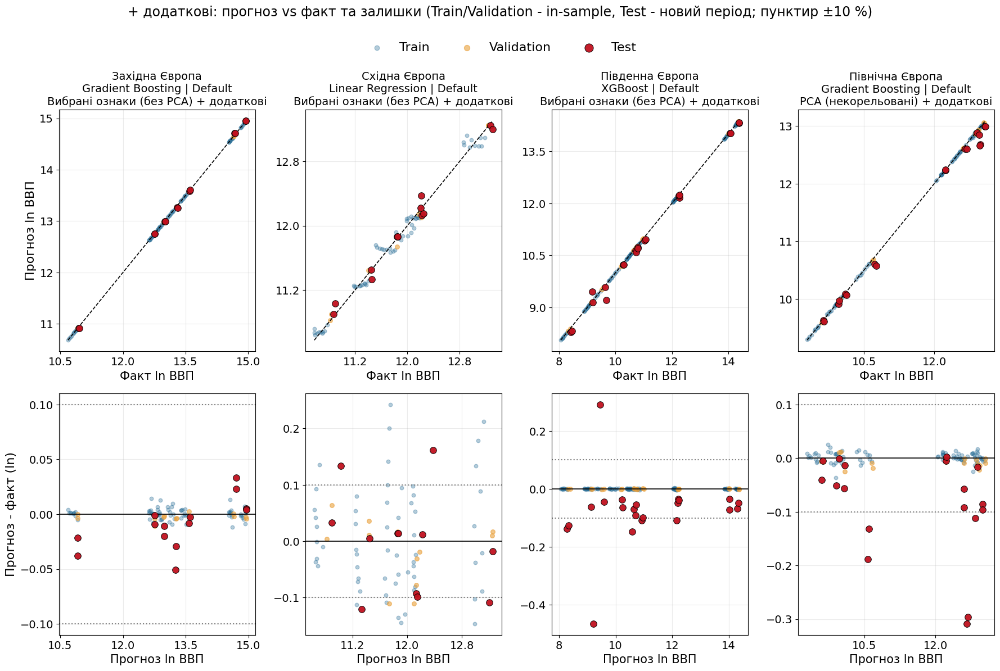

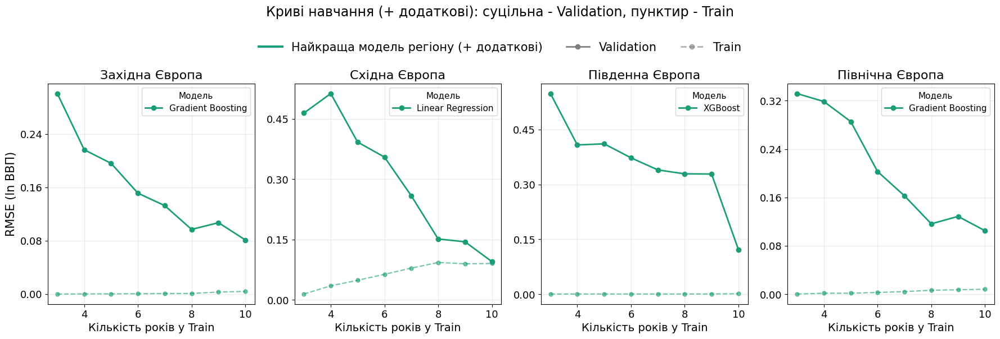

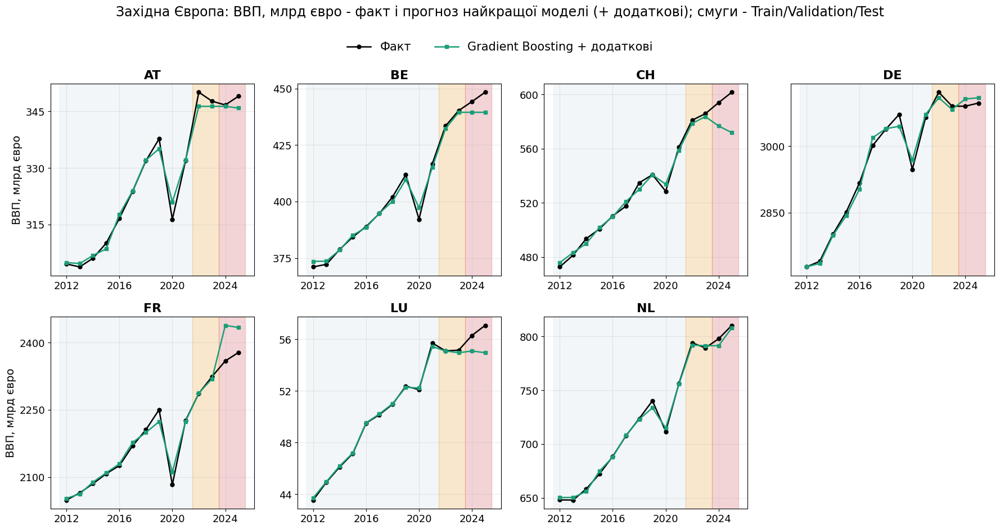

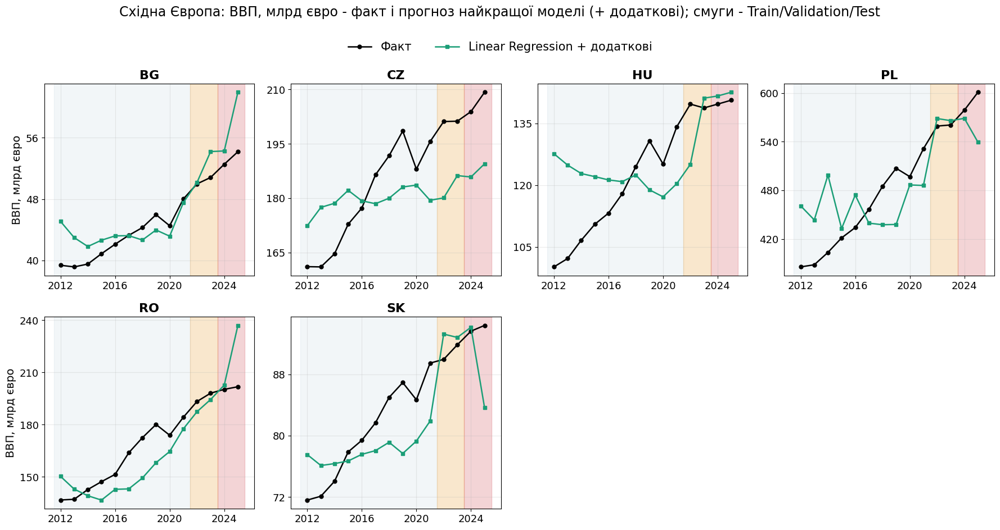

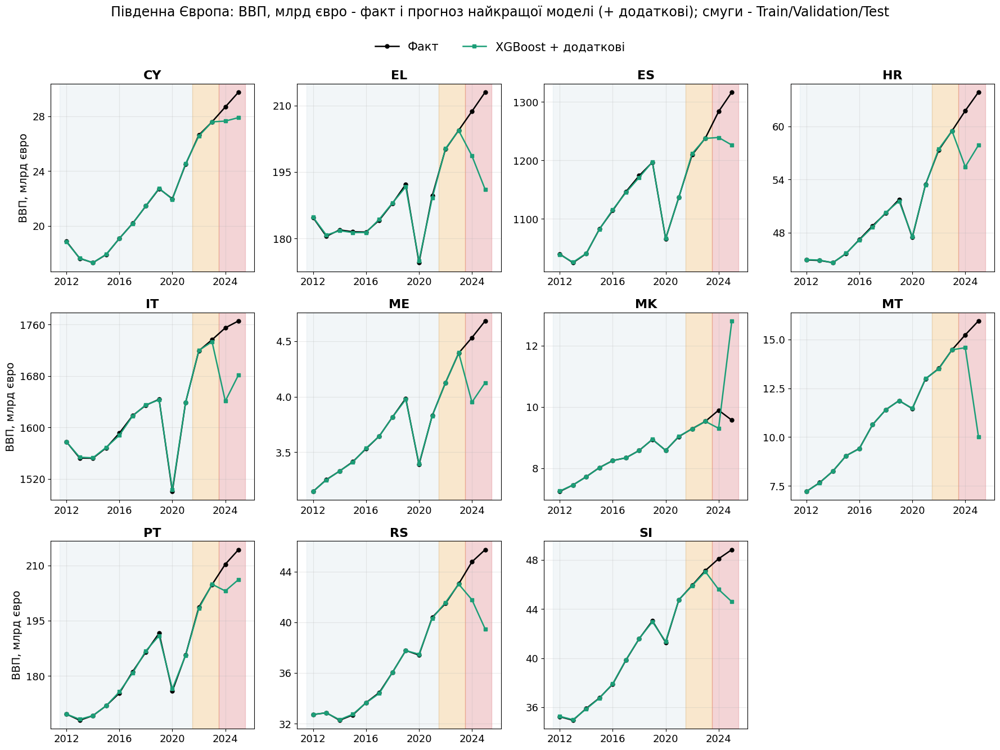

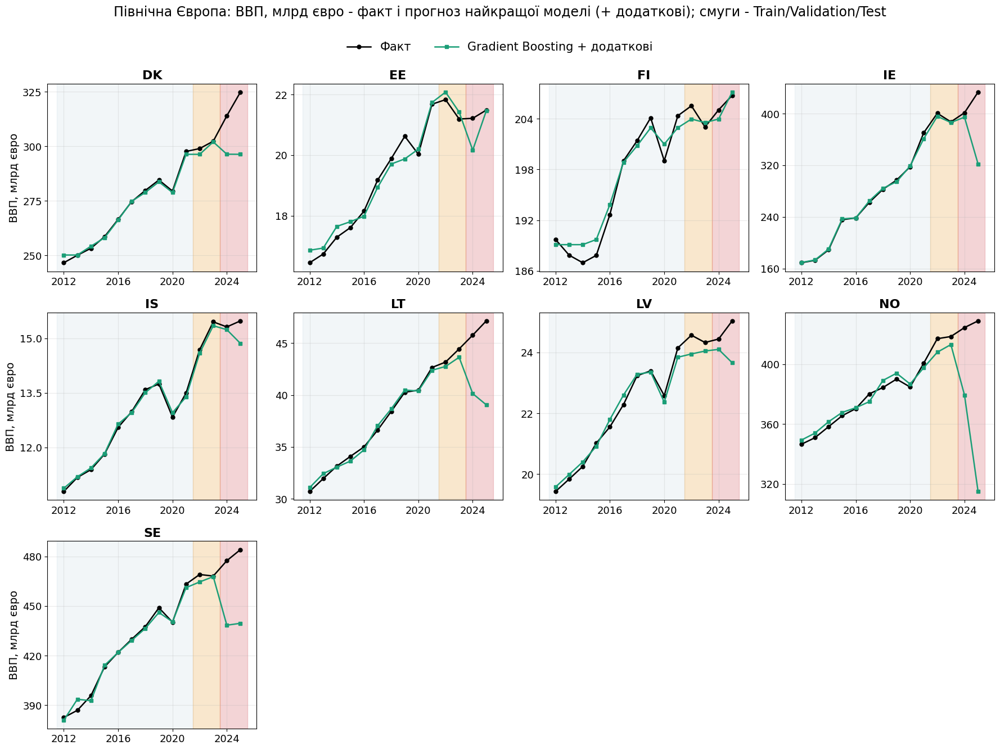

In [24]:
# ===== Світло + додаткові змінні: найкраща модель регіону (за Validation) -> Train+Validation -> Test + графіки =====
def final_report(tag, label, FN, CH, color):
    """Найкраща за Val RMSE модель у кожному регіоні (серед усіх наборів ознак) -> Train+Validation -> Test; таблиця і графіки."""
    BEST = {r: {"fs": (fs_b := min(FS_MODELS, key=lambda fs: CH[(r, fs)]["val_rmse"])), **CH[(r, fs_b)]} for r in REGIONS}
    print(f"\n########## {label} ##########")
    display(pd.DataFrame({REG_LABEL[r]: {"Набір ознак": b["fs"], "Модель": b["model"], "Етап": b["stage"], "Val RMSE": round(b["val_rmse"], 3)}
                          for r, b in BEST.items()}).T)
    fns = {r: FN[(r, BEST[r]["fs"])] for r in REGIONS}

    FINAL, summ = evaluate_best(BEST, fns, lambda r: {"Регіон": REG_LABEL[r], "Набір ознак": f'{BEST[r]["fs"]} {label}'})
    summ = summ.set_index(["Регіон", "Набір ознак"])
    summ.to_csv(TABLES_DIR / f"temporal_test_summary_best_models_{tag}.csv")
    print(f"Test {test_years[0]}-{test_years[-1]}: найкраща за Validation модель у кожному регіоні ({label})")
    display(summ.round(3))

    plot_pred_vs_actual(
        FINAL, {r: f'{REG_LABEL[r]}\n{BEST[r]["model"]} | {BEST[r]["stage"]}\n{BEST[r]["fs"]} {label}' for r in REGIONS},
        f"{label}: прогноз vs факт та залишки (Train/Validation - in-sample, Test - новий період; пунктир ±10 %)",
        f"fig_temporal_best_{tag}_scatter_residuals.png")

    plot_learning_curves(
        {r: [dict(model=BEST[r]["model"], params=BEST[r]["params"], fn=fns[r], color=color,
                  group=f"Найкраща модель регіону ({label})")] for r in REGIONS},
        f"Криві навчання ({label}): суцільна - Validation, пунктир - Train",
        f"fig_temporal_best_{tag}_learning_curves.png")

    for r in REGIONS:
        plot_country_timeseries(
            r, [dict(d=FINAL[r], fmt="-s", color=color, label=f'{BEST[r]["model"]} {label}')],
            f"{REG_LABEL[r]}: ВВП, млрд євро - факт і прогноз найкращої моделі ({label}); смуги - Train/Validation/Test",
            f"fig_temporal_best_{tag}_country_timeseries_{r}.png")
    return BEST, FINAL, summ


BEST_ST, FINAL_ST, summ_st = final_report("structural", "+ додаткові", FN_ST, CH2_ST, "#1b9e77")

## 10. Найкраща модель регіону серед усіх специфікацій

Результати Validation обох специфікацій (лише світло і + додаткові змінні) об'єднуються. У кожному регіоні обирається одна найкраща за Validation RMSE модель серед усіх специфікацій, наборів ознак, моделей і етапів (Default / Tuned), перенавчається на Train+Validation і оцінюється на Test.

Усього побудовано моделей: 200 (на регіон приблизно 50)

Західна Європа: топ-5 за Validation RMSE (2022-2023)


,Варіант,Набір ознак,Модель,Етап,Train RMSE,Val RMSE,Val R2,Val MedAPE_%,Val MAE,Val MAPE_%,Val within10_%,Val within25_%
0,+ додаткові,Вибрані ознаки (без PCA),Gradient Boosting,Default,0.004,0.081,0.996,5.066,0.064,6.100,85.714,100.000
1,+ додаткові,Вибрані ознаки (без PCA),Gradient Boosting,Tuned,0.008,0.123,0.990,5.507,0.084,7.737,85.714,85.714
2,+ додаткові,Вибрані ознаки (без PCA),Linear Regression,Default,0.056,0.128,0.989,9.311,0.110,10.707,64.286,100.000
3,+ додаткові,Усі ознаки,Gradient Boosting,Default,0.002,0.141,0.987,4.671,0.098,8.891,71.429,85.714
4,+ додаткові,Усі ознаки,Gradient Boosting,Tuned,0.029,0.157,0.984,6.794,0.117,10.560,71.429,85.714



Східна Європа: топ-5 за Validation RMSE (2022-2023)


,Варіант,Набір ознак,Модель,Етап,Train RMSE,Val RMSE,Val R2,Val MedAPE_%,Val MAE,Val MAPE_%,Val within10_%,Val within25_%
0,+ додаткові,Вибрані ознаки (без PCA),Linear Regression,Default,0.090,0.095,0.984,6.381,0.073,6.912,75.000,100.0
1,+ додаткові,Вибрані ознаки (без PCA),Ridge,Tuned,0.090,0.097,0.983,6.258,0.075,7.090,75.000,100.0
2,базові,Усі ознаки,Gradient Boosting,Default,0.003,0.107,0.980,7.531,0.085,8.030,66.667,100.0
3,+ додаткові,Вибрані ознаки (без PCA),Gradient Boosting,Tuned,0.000,0.108,0.979,7.801,0.097,9.250,66.667,100.0
4,+ додаткові,Вибрані ознаки (без PCA),Ridge,Default,0.108,0.123,0.973,10.358,0.110,10.510,50.000,100.0



Південна Європа: топ-5 за Validation RMSE (2022-2023)


,Варіант,Набір ознак,Модель,Етап,Train RMSE,Val RMSE,Val R2,Val MedAPE_%,Val MAE,Val MAPE_%,Val within10_%,Val within25_%
0,+ додаткові,Вибрані ознаки (без PCA),XGBoost,Default,0.001,0.122,0.996,7.985,0.102,9.504,54.545,100.000
1,+ додаткові,Вибрані ознаки (без PCA),Gradient Boosting,Tuned,0.029,0.131,0.995,9.086,0.111,10.359,59.091,95.455
2,+ додаткові,Вибрані ознаки (без PCA),Random Forest,Default,0.062,0.138,0.994,11.648,0.128,11.925,31.818,100.000
3,+ додаткові,Вибрані ознаки (без PCA),Gradient Boosting,Default,0.016,0.139,0.994,9.447,0.115,10.554,54.545,90.909
4,+ додаткові,Усі ознаки,LightGBM,Default,0.053,0.145,0.994,9.576,0.118,11.200,50.000,95.455


... (2 outputs left out)


Найкраща модель у кожному регіоні:


,Варіант,Набір ознак,Модель,Етап,Train RMSE,Val RMSE,Val R2,Val MedAPE_%,Val MAE,Val MAPE_%,Val within10_%,Val within25_%
Регіон,,,,,,,,,,,,
Західна Європа,+ додаткові,Вибрані ознаки (без PCA),Gradient Boosting,Default,0.004,0.081,0.996,5.066,0.064,6.100,85.714,100.0
Східна Європа,+ додаткові,Вибрані ознаки (без PCA),Linear Regression,Default,0.090,0.095,0.984,6.381,0.073,6.912,75.000,100.0
Південна Європа,+ додаткові,Вибрані ознаки (без PCA),XGBoost,Default,0.001,0.122,0.996,7.985,0.102,9.504,54.545,100.0
Північна Європа,+ додаткові,PCA (некорельовані),Gradient Boosting,Default,0.008,0.105,0.994,6.475,0.083,7.829,61.111,100.0



Test 2024-2025: найкраща за Validation модель у кожному регіоні (серед усіх варіантів)


,,,Модель,Val RMSE,R2,RMSE,MedAPE,MAE,MAPE,within25,Baseline R2,Baseline RMSE,Baseline MedAPE,Baseline MAE,Baseline MAPE,розбиттів,MedAPE [Q25; Q75],краща за baseline (RMSE),within10
Регіон,Варіант,Набір ознак,,,,,,,,,,,,,,,,,
Західна Європа,+ додаткові,Вибрані ознаки (без PCA),Gradient Boosting | Default,0.081,1.000,0.023,1.526,0.018,1.819,100.000,0.847,0.481,25.541,0.362,28.394,1,1.5 [0.6; 2.8],так,100.000
Східна Європа,+ додаткові,Вибрані ознаки (без PCA),Linear Regression | Default,0.095,0.986,0.087,6.076,0.068,6.780,100.000,0.735,0.383,29.350,0.322,36.052,1,6.1 [1.4; 10.6],так,66.667
Південна Європа,+ додаткові,Вибрані ознаки (без PCA),XGBoost | Default,0.122,0.994,0.141,6.585,0.102,9.716,90.909,0.878,0.632,32.237,0.492,51.878,1,6.6 [4.8; 10.3],так,68.182
Північна Європа,+ додаткові,PCA (некорельовані),Gradient Boosting | Default,0.105,0.992,0.126,5.558,0.087,7.944,88.889,0.380,1.077,76.315,0.849,122.631,1,5.6 [1.5; 10.3],так,72.222


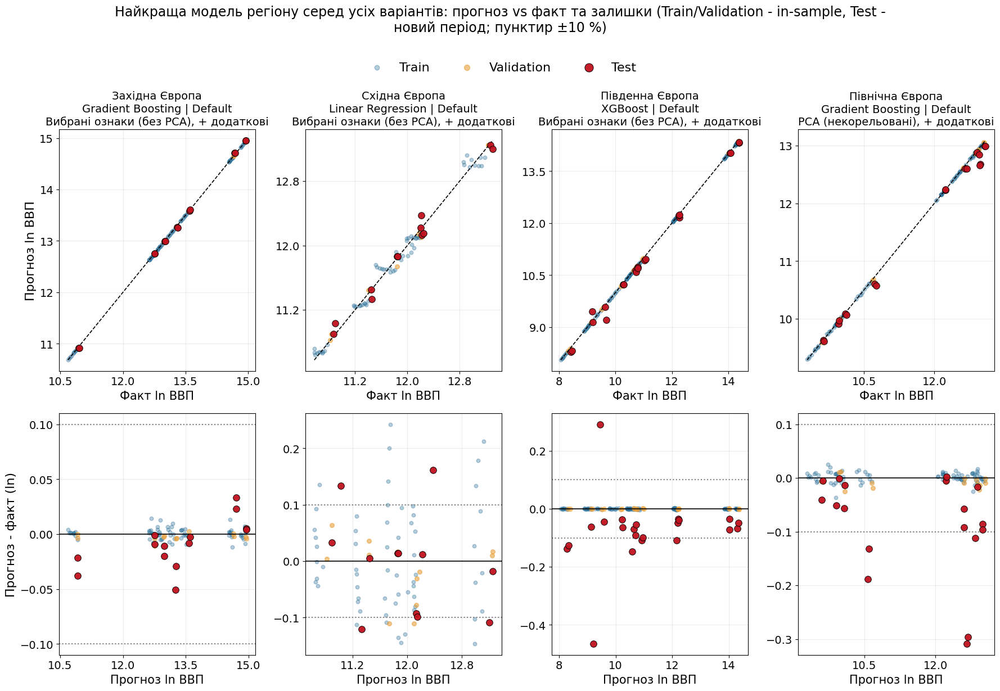

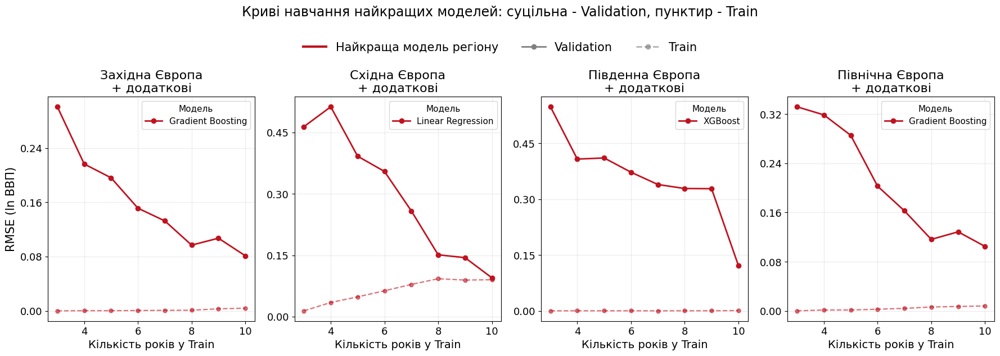

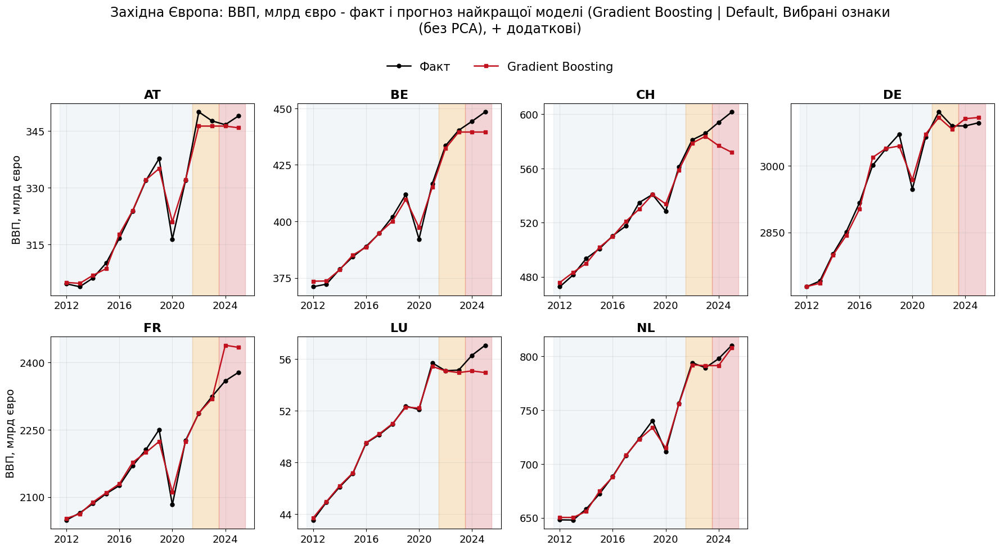

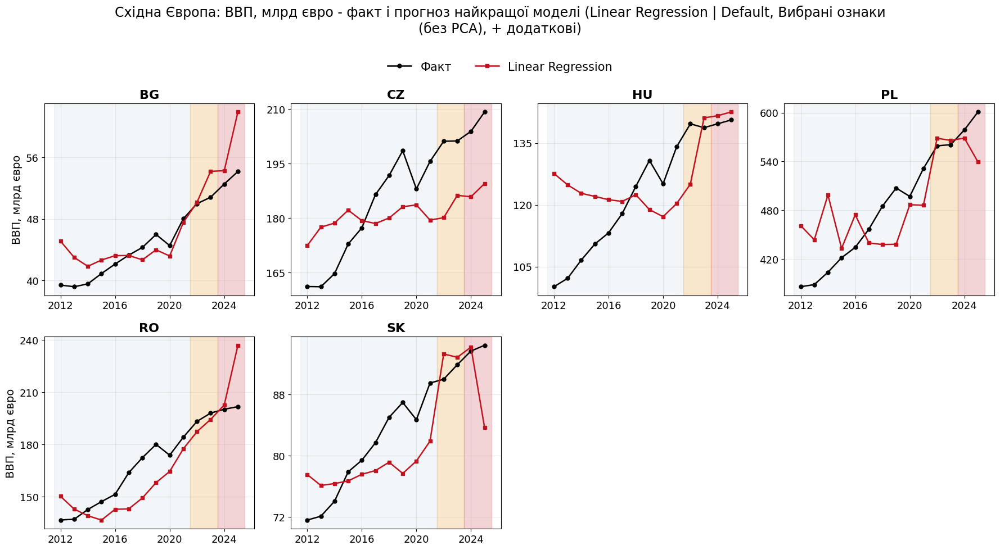

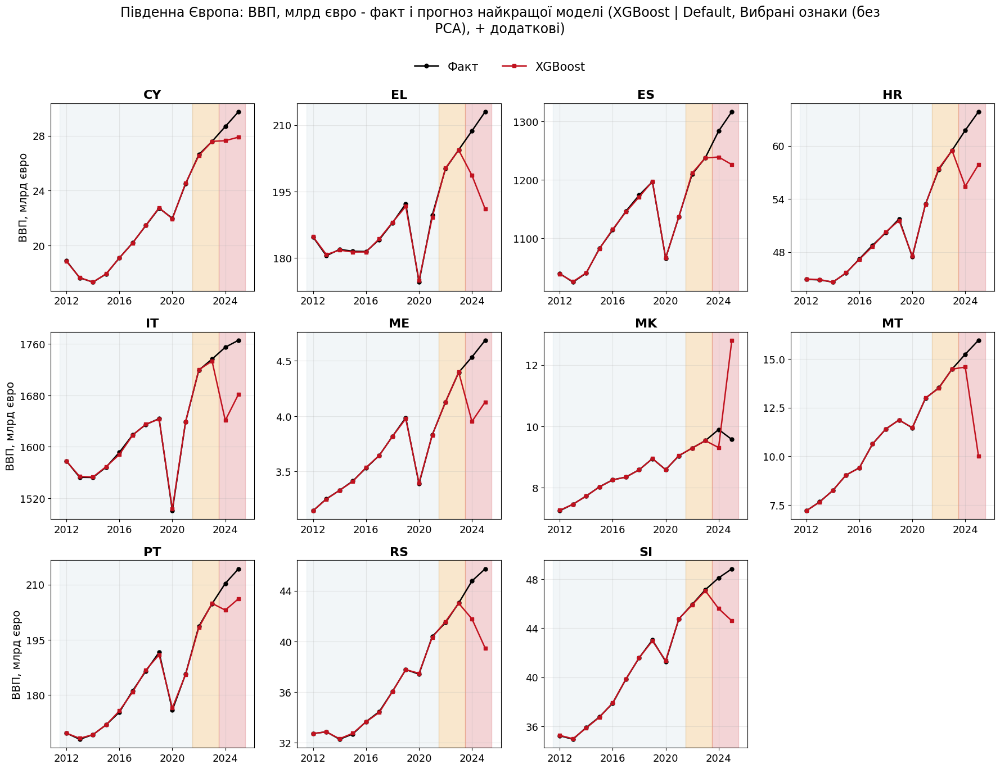

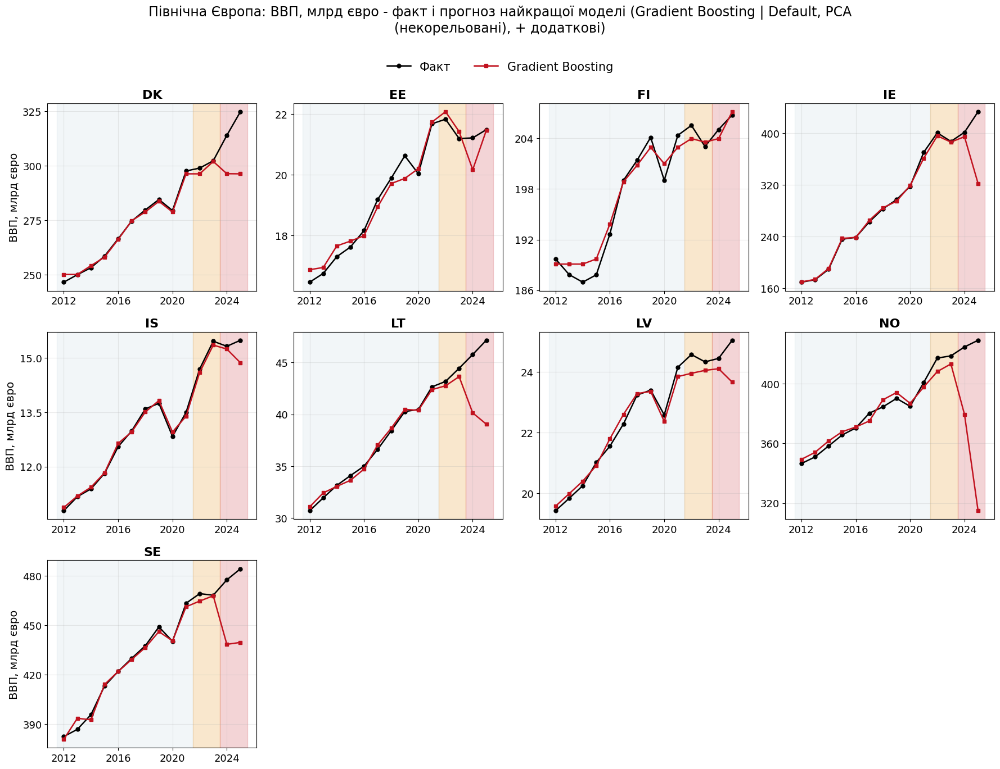

In [25]:
# ===== Найкраща модель у кожному регіоні серед УСІХ побудованих (2 специфікації x 3 набори x моделі x Default/Tuned) за Validation RMSE =====
# --- 1) об'єднання всіх результатів Validation і функцій ознак ---
VARIANTS = {   # назва варіанта: (таблиця результатів, функції ознак)
    "базові":       (res,    FN_BASE),
    "+ додаткові": (res_st, FN_ST),
}
allres = pd.concat([t[t["Набір ознак"] != "—"].assign(Варіант=v) for v, (t, _) in VARIANTS.items()], ignore_index=True)
allres["Регіон"] = allres["region"].map(REG_LABEL)
allres.drop(columns="params").to_csv(TABLES_DIR / "temporal_validation_results_all_variants.csv", index=False)
print(f"Усього побудовано моделей: {len(allres)} (на регіон приблизно {len(allres) // len(REGIONS)})")

# --- 2) найкраща за Val RMSE модель у кожному регіоні + топ-5 для контексту ---
OVERALL = {}
show = ["Варіант", "Набір ознак", "Модель", "Етап", "Train RMSE", "Val RMSE", "Val R2", "Val MedAPE_%", "Val MAE", "Val MAPE_%", "Val within10_%", "Val within25_%"]
for r in REGIONS:
    t = allres[allres["region"] == r].sort_values("Val RMSE").reset_index(drop=True)
    OVERALL[r] = t.iloc[0]
    print(f"\n{REG_LABEL[r]}: топ-5 за Validation RMSE ({val_years[0]}-{val_years[-1]})")
    display(t.head(5)[show].round(3))
best_tab = pd.DataFrame([{**{"Регіон": REG_LABEL[r]}, **OVERALL[r][show].to_dict()} for r in REGIONS]).set_index("Регіон")
print("\nНайкраща модель у кожному регіоні:")
display(best_tab.round(3)); best_tab.to_csv(TABLES_DIR / "temporal_best_overall_validation.csv")

# --- 3) фінальний етап: Train+Validation -> Test ---
BEST_O = {r: {"model": b["Модель"], "stage": b["Етап"], "params": b["params"], "val_rmse": b["Val RMSE"]} for r, b in OVERALL.items()}
FN_O = {r: VARIANTS[b["Варіант"]][1][(r, b["Набір ознак"])] for r, b in OVERALL.items()}
FINAL_O, summary_o = evaluate_best(BEST_O, FN_O, lambda r: {"Регіон": REG_LABEL[r], "Варіант": OVERALL[r]["Варіант"],
                                                            "Набір ознак": OVERALL[r]["Набір ознак"]})
summary_o = summary_o.set_index(["Регіон", "Варіант", "Набір ознак"])
summary_o.to_csv(TABLES_DIR / "temporal_test_summary_best_overall.csv")
print(f"\nTest {test_years[0]}-{test_years[-1]}: найкраща за Validation модель у кожному регіоні (серед усіх варіантів)")
display(summary_o.round(3))

# --- 4) графіки ---
COL = "#c1121f"
lab = {r: f'{OVERALL[r]["Модель"]} | {OVERALL[r]["Етап"]}\n{OVERALL[r]["Набір ознак"]}, {OVERALL[r]["Варіант"]}' for r in REGIONS}

plot_pred_vs_actual(
    FINAL_O, {r: f"{REG_LABEL[r]}\n{lab[r]}" for r in REGIONS},
    "Найкраща модель регіону серед усіх варіантів: прогноз vs факт та залишки (Train/Validation - in-sample, Test - новий період; пунктир ±10 %)",
    "fig_temporal_best_overall_scatter_residuals.png")

plot_learning_curves(
    {r: [dict(model=OVERALL[r]["Модель"], params=OVERALL[r]["params"], fn=FN_O[r], color=COL,
              group="Найкраща модель регіону")] for r in REGIONS},
    "Криві навчання найкращих моделей: суцільна - Validation, пунктир - Train",
    "fig_temporal_best_overall_learning_curves.png",
    titles={r: f'{REG_LABEL[r]}\n{OVERALL[r]["Варіант"]}' for r in REGIONS})

for r in REGIONS:
    b = OVERALL[r]
    plot_country_timeseries(
        r, [dict(d=FINAL_O[r], fmt="-s", color=COL, label=b["Модель"])],
        f'{REG_LABEL[r]}: ВВП, млрд євро - факт і прогноз найкращої моделі ({b["Модель"]} | {b["Етап"]}, '
        f'{b["Набір ознак"]}, {b["Варіант"]})',
        f"fig_temporal_best_overall_country_timeseries_{r}.png")

## 11. Контрольні лінійні моделі на Test

Дві прості лінійні моделі, навчені на Train+Validation: лише ln Sum of Lights і ln Sum of Lights разом зі додатковими змінними. Вони показують, скільки дають складніші моделі понад лінійну залежність.

In [26]:
# ===== Метрики на Test для двох контрольних лінійних моделей: Sum of Lights і Sum of Lights + додаткові змінні =====
KEYS = ["R2", "RMSE", "MAE", "MedAPE_%", "MAPE_%", "within10_%", "within25_%"]
COLS_EXT = ["log_ntl_sum"] + list(STRUCT_NOREG)          # ln Sum of Lights + ln населення, широта, ln площі
rows = []
for r in REGIONS:
    dtv, dte = region_data(r, *TRAIN_VAL), region_data(r, "Test")
    # 1) модель лише на світлі (Train+Validation -> Test)
    m0 = reg_metrics(dte[TARGET], sol_baseline(dtv, dte))
    rows.append({"Підвибірка": REG_LABEL[r], "Модель": "Sum of Lights", **{k: m0[k] for k in KEYS}})
    # 2) модель із додатковими змінними
    est = LinearRegression().fit(dtv[COLS_EXT], dtv[TARGET])
    m1 = reg_metrics(dte[TARGET], est.predict(dte[COLS_EXT]))
    rows.append({"Підвибірка": REG_LABEL[r], "Модель": "Sum of Lights із дод. змінними", **{k: m1[k] for k in KEYS}})
ctrl_test = pd.DataFrame(rows).set_index(["Підвибірка", "Модель"])
ctrl_test.to_csv(TABLES_DIR / "test_control_models_full_metrics.csv")
display(ctrl_test.round(3))

R2   RMSE    MAE  MedAPE_%  \
Підвибірка      Модель                                                          
Західна Європа  Sum of Lights                   0.847  0.481  0.362    25.541   
                Sum of Lights із дод. змінними  0.986  0.145  0.132    10.240   
Східна Європа   Sum of Lights                   0.735  0.383  0.322    29.350   
                Sum of Lights із дод. змінними  0.963  0.143  0.128    12.624   
Південна Європа Sum of Lights                   0.878  0.632  0.492    32.237   
                Sum of Lights із дод. змінними  0.937  0.453  0.330    22.335   
Північна Європа Sum of Lights                   0.380  1.077  0.849    76.315   
                Sum of Lights із дод. змінними  0.889  0.455  0.407    36.340   

                                                 MAPE_%  within10_%  \
Підвибірка      Модель                                                
Західна Європа  Sum of Lights                    28.394      28.571   
                Sum of Lights із дод. змінними   13.460      28.571   
Східна Європа   Sum of Lights                    36.052       8.333   
                Sum of Lights із дод. змінними   11.841      33.333   
Південна Європа Sum of Lights                    51.878      22.727   
                Sum of Lights із дод. змінними   31.902      27.273   
Північна Європа Sum of Lights                   122.631      11.111   
                Sum of Lights із дод. змінними   42.775       5.556   

                                                within25_%  
Підвибірка      Модель                                      
Західна Європа  Sum of Lights                       50.000  
                Sum of Lights із дод. змінними      85.714  
Східна Європа   Sum of Lights                       41.667  
                Sum of Lights із дод. змінними     100.000  
Південна Європа Sum of Lights                       36.364  
                Sum of Lights із дод. змінними      54.545  
Північна Європа Sum of Lights                       27.778  
                Sum of Lights із дод. змінними      11.111

## 12. Підсумкові моделі: викиди на Test і порівняння специфікацій

- прогноз vs факт найкращих моделей розділу 10 з підписами спостережень Test, де |залишок| > `THR`;
- ВВП кожної країни: факт і прогнози найкращих моделей двох специфікацій (лише світло / світло + додаткові змінні).

`fit_best` — найкраща за Validation RMSE модель заданої специфікації в регіоні, перенавчена на Train+Validation, з прогнозом на весь період.

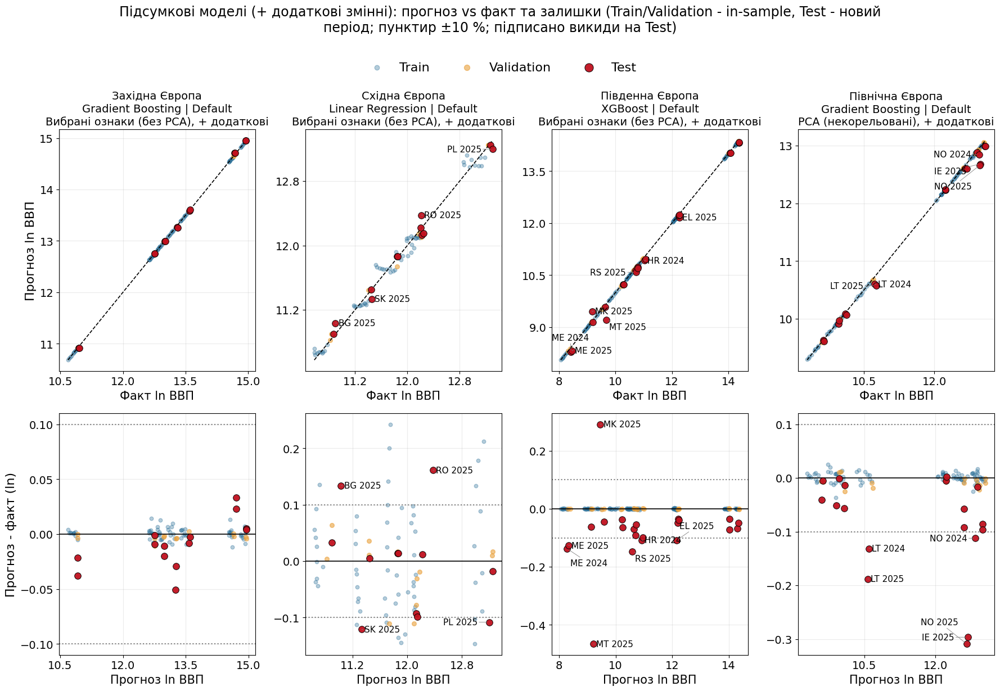

In [27]:
# ===== Прогноз vs факт і залишки підсумкових моделей (+ додаткові змінні) з підписами викидів на Test =====
THR = 0.10                                   # поріг |залишок| (ln), вище якого підписується спостереження
plot_pred_vs_actual(
    FINAL_O, {r: f"{REG_LABEL[r]}\n{lab[r]}" for r in REGIONS},
    "Підсумкові моделі (+ додаткові змінні): прогноз vs факт та залишки "
    "(Train/Validation - in-sample, Test - новий період; пунктир ±10 %; підписано викиди на Test)",
    "fig_temporal_best_structural_scatter_residuals_labeled.png",
    label_outliers=True, thr=THR)

,Світло: модель,Світло: набір ознак,Світло: Val RMSE,Світло + дод.: модель,Світло + дод.: набір ознак,Світло + дод.: Val RMSE
Регіон,,,,,,
Західна Європа,Random Forest | Default,Усі ознаки,0.186,Gradient Boosting | Default,Вибрані ознаки (без PCA),0.081
Східна Європа,Gradient Boosting | Default,Усі ознаки,0.107,Linear Regression | Default,Вибрані ознаки (без PCA),0.095
Південна Європа,Gradient Boosting | Tuned,Вибрані ознаки (без PCA),0.163,XGBoost | Default,Вибрані ознаки (без PCA),0.122
Північна Європа,Gradient Boosting | Tuned,Усі ознаки,0.220,Gradient Boosting | Default,PCA (некорельовані),0.105


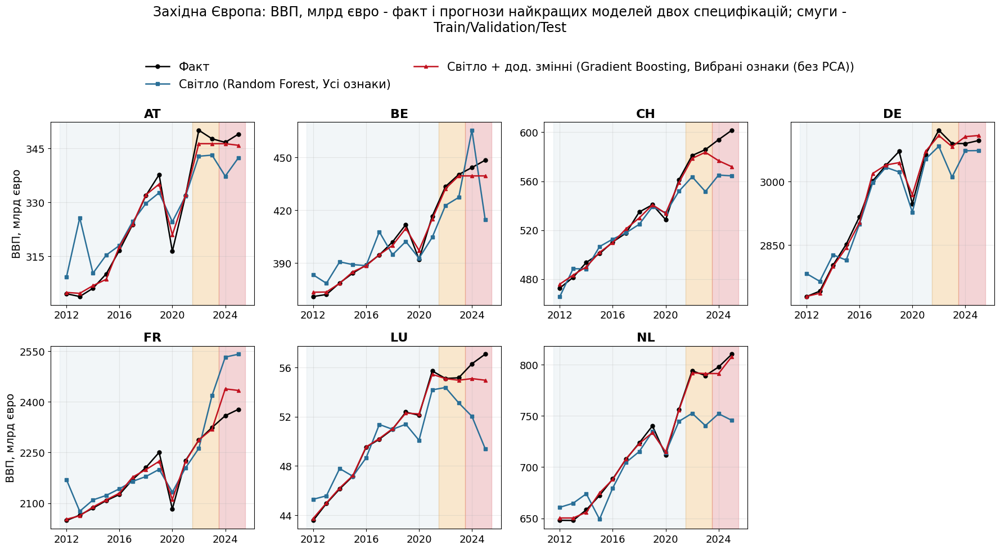

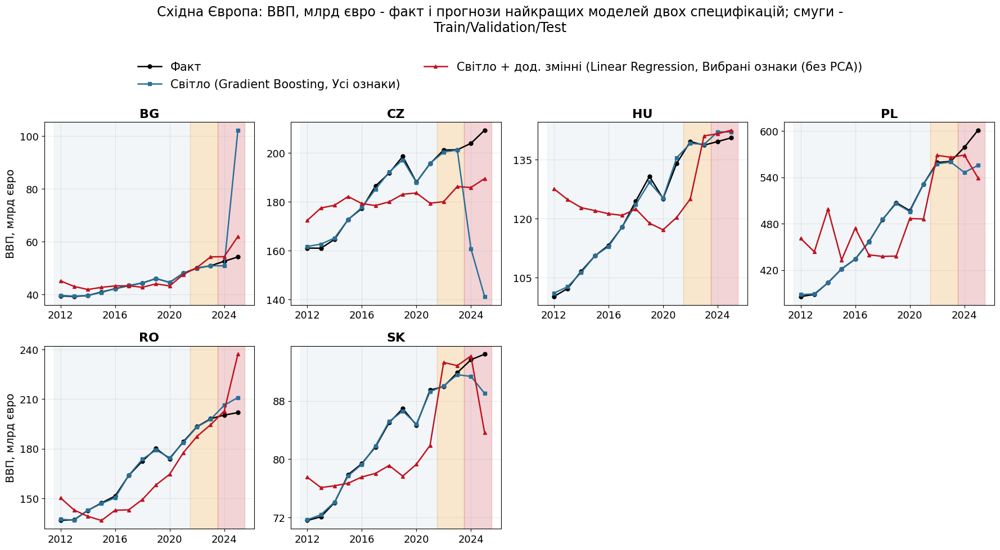

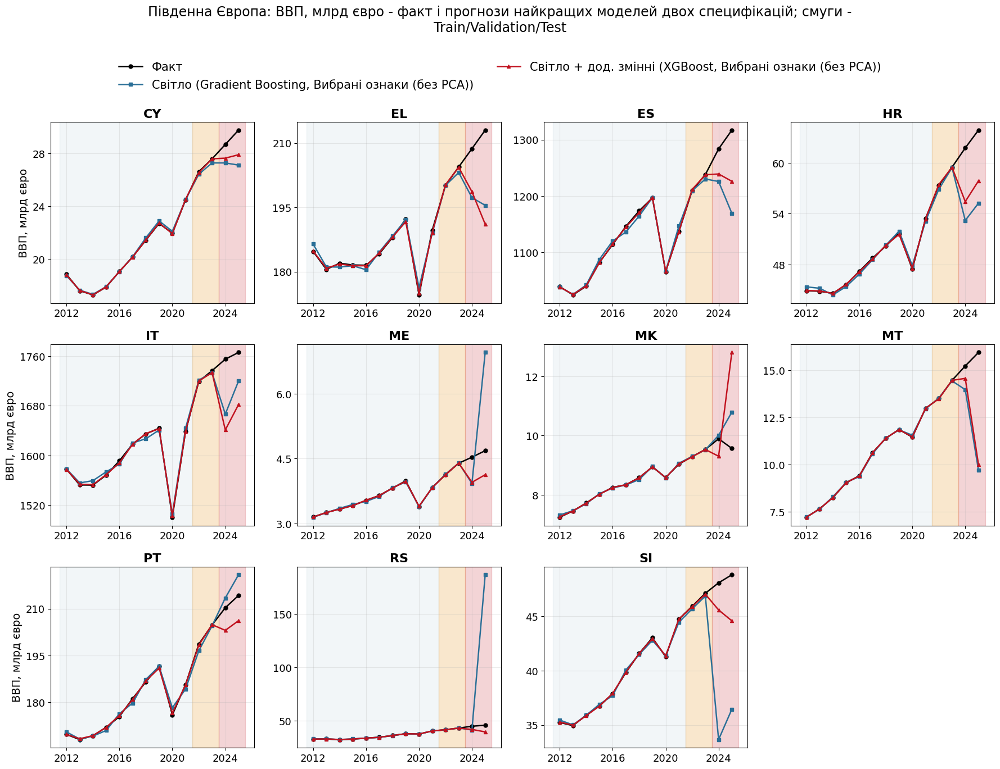

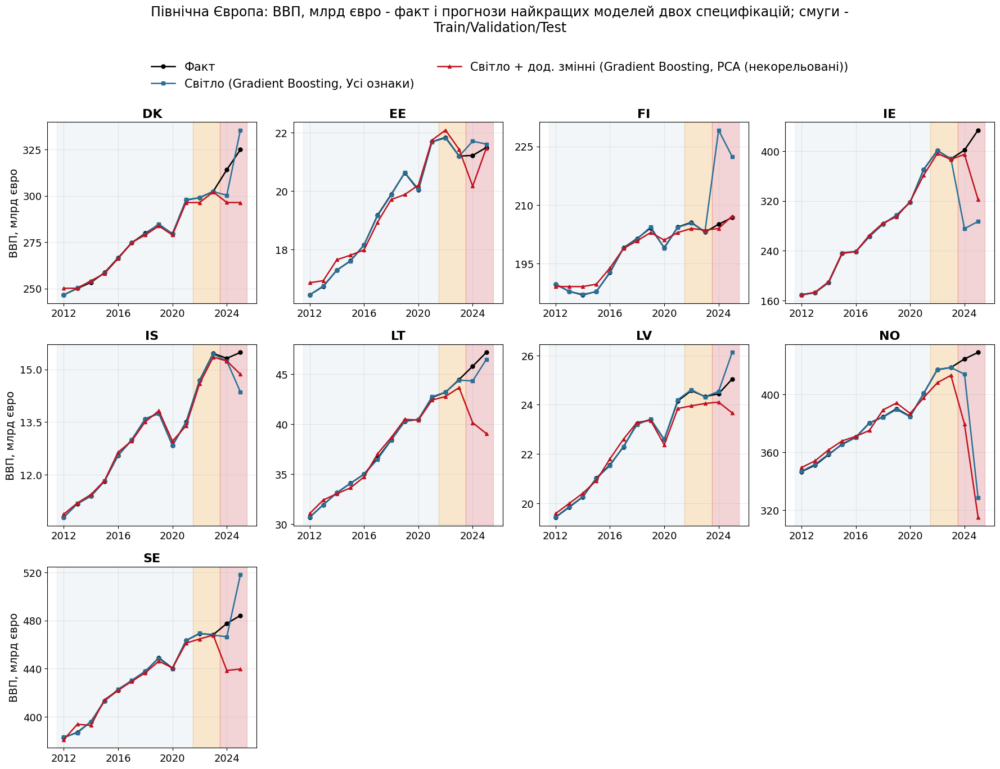

In [28]:
# ===== Порівняння специфікацій: ВВП країн — факт, найкраща модель на світлі, найкраща модель світло + додаткові змінні =====
C_BASE, C_ST = "#2a6f97", "#c1121f"      # колір прогнозу за світлом / за світлом із додатковими змінними
START_YEAR = None                        # напр. 2019, щоб показати лише 2019-2025; None - увесь період


def best_of_variant(variant, r):
    return allres[(allres["region"] == r) & (allres["Варіант"] == variant)].sort_values("Val RMSE").iloc[0]


def fit_best(variant, r):
    """Найкраща за Val RMSE модель варіанта у підвибірці r -> Train+Validation -> прогноз на весь період."""
    b = best_of_variant(variant, r)
    return fit_final(r, b["Модель"], b["params"], VARIANTS[variant][1][(r, b["Набір ознак"])]), b


CMP, rows = {}, []
for r in REGIONS:
    d0, b0 = fit_best("базові", r)
    d1, b1 = fit_best("+ додаткові", r)
    CMP[r] = (d0, b0, d1, b1)
    rows.append({"Регіон": REG_LABEL[r],
                 "Світло: модель": f'{b0["Модель"]} | {b0["Етап"]}', "Світло: набір ознак": b0["Набір ознак"], "Світло: Val RMSE": b0["Val RMSE"],
                 "Світло + дод.: модель": f'{b1["Модель"]} | {b1["Етап"]}', "Світло + дод.: набір ознак": b1["Набір ознак"], "Світло + дод.: Val RMSE": b1["Val RMSE"]})
display(pd.DataFrame(rows).set_index("Регіон").round(3))

for r in REGIONS:
    d0, b0, d1, b1 = CMP[r]
    plot_country_timeseries(
        r, [dict(d=d0, fmt="-s", color=C_BASE, label=f'Світло ({b0["Модель"]}, {b0["Набір ознак"]})'),
            dict(d=d1, fmt="-^", color=C_ST, label=f'Світло + дод. змінні ({b1["Модель"]}, {b1["Набір ознак"]})')],
        f"{REG_LABEL[r]}: ВВП, млрд євро - факт і прогнози найкращих моделей двох специфікацій; смуги - Train/Validation/Test",
        f"fig_temporal_compare_specs_country_timeseries_{r}.png",
        start_year=START_YEAR)

## 13. Аналіз аномалій

Таблиці для пояснення великих тестових помилок:
1. зміна яскравості і ВВП у 2023–2025 роках для всіх країн;
2. позначені спостереження: які ознаки виходять за діапазон Train+Validation і які найбільше змінюють прогноз, якщо повернути їх до значень 2023 року (`fit_est`, `feat_names`);
3. 2020 рік: падіння ВВП і зміна яскравості;
4. ряди 2019–2025 (індекс 2019 = 100);
5. концентрація тестової помилки в кількох найгірших спостереженнях;
6. кореляція світла і ВВП (рівнів і приростів) по країнах і її зв'язок з тестовою помилкою.

In [29]:
LIGHT = "log_ntl_sum"      # якщо назва інша - замінити

# ---- Таблиця 1: зміна яскравості і ВВП 2023-2025 для всіх країн ----
pl = tdata.pivot(index="CNTR_ID", columns="year", values=LIGHT)
pg = tdata.pivot(index="CNTR_ID", columns="year", values=TARGET)
pct = lambda p, a, b: 100 * (np.exp(p[b] - p[a]) - 1)
reg_of = tdata.drop_duplicates("CNTR_ID").set_index("CNTR_ID")["region"]
tab = pd.DataFrame({"Підвибірка": reg_of.map(REG_LABEL)})
for a, b in ((2023, 2024), (2024, 2025), (2023, 2025)):
    tab[f"Світло {a}→{b}, %"] = pct(pl, a, b)
    tab[f"ВВП {a}→{b}, %"] = pct(pg, a, b)
tab["Розрив 2023→2025, в.п."] = tab["Світло 2023→2025, %"] - tab["ВВП 2023→2025, %"]
tab = tab.sort_values(["Підвибірка", "Розрив 2023→2025, в.п."]).round(1)
display(tab); tab.to_csv(TABLES_DIR / "anomalies_light_vs_gdp_2023_2025.csv")

# ---- Таблиця 2: що саме змінює прогноз у викидах ----
def feat_names(r, fs, struct):
    nm = {FS_PCA: [f"PC{i+1}" for i in range(TF[r]["pca"].n_components_)],
          FS_SEL: list(TF[r]["sel"]), FS_ALL: list(TF[r]["allf"])}[fs]
    return nm + (list(STRUCT_NOREG) if struct else [])

def fit_est(variant, r):
    b = best_of_variant(variant, r)
    fn = VARIANTS[variant][1][(r, b["Набір ознак"])]
    dall = region_data(r)
    dtv = dall[dall["role"].isin(TRAIN_VAL)]
    return fit_model(b["Модель"], b["params"], fn, dtv), fn, b, dall, dtv

FLAG = [("BG", 2025), ("CZ", 2024), ("CZ", 2025), ("RS", 2025), ("ME", 2025), ("SI", 2024), ("SI", 2025),
        ("FI", 2024), ("FI", 2025), ("IE", 2024), ("NO", 2025), ("MT", 2025), ("MK", 2025)]
rows = []
for variant, struct in (("базові", False), ("+ додаткові", True)):
    for cn, yr in FLAG:
        r = reg_of[cn]
        est, fn, b, dall, dtv = fit_est(variant, r)
        names = feat_names(r, b["Набір ознак"], struct)
        Xtv = fn(dtv); lo, hi = Xtv.min(0), Xtv.max(0)
        row = dall[(dall["CNTR_ID"] == cn) & (dall["year"] == yr)]
        ref = dall[(dall["CNTR_ID"] == cn) & (dall["year"] == 2023)]
        x, x0 = fn(row), fn(ref)
        p, p0 = est.predict(x)[0], est.predict(x0)[0]
        out = [names[j] for j in range(x.shape[1]) if x[0, j] < lo[j] or x[0, j] > hi[j]]
        eff = []
        for j in range(x.shape[1]):                      # повернути ознаку j до значення 2023 р. і подивитися, як зміниться прогноз
            xj = x.copy(); xj[0, j] = x0[0, j]
            eff.append((est.predict(xj)[0] - p, names[j]))
        eff = sorted(eff, key=lambda e: -abs(e[0]))[:3]
        rows.append({"Варіант": variant, "Країна": cn, "Рік": yr, "Модель": f'{b["Модель"]} | {b["Етап"]}',
                     "Факт, млрд": np.exp(row[TARGET].iloc[0]) / 1e3, "Прогноз, млрд": np.exp(p) / 1e3,
                     "Прогноз vs 2023, %": 100 * (np.exp(p - p0) - 1),
                     "Ознак поза діапазоном Train+Val": f"{len(out)}/{x.shape[1]}", "Які": ", ".join(out[:6]),
                     "Найбільший внесок (зміна ln-прогнозу, якщо повернути до 2023)": "; ".join(f"{n} ({d:+.2f})" for d, n in eff)})
t2 = pd.DataFrame(rows).round(2)
display(t2); t2.to_csv(TABLES_DIR / "anomalies_flagged_observations.csv", index=False)

,Підвибірка,"Світло 2023→2024, %","ВВП 2023→2024, %","Світло 2024→2025, %","ВВП 2024→2025, %","Світло 2023→2025, %","ВВП 2023→2025, %","Розрив 2023→2025, в.п."
CNTR_ID,,,,,,,,
FR,Західна Європа,-10.4,1.5,3.8,0.8,-7.0,2.3,-9.3
CH,Західна Європа,-3.4,1.4,-0.2,1.3,-3.6,2.7,-6.3
AT,Західна Європа,0.4,-0.3,-1.6,0.7,-1.2,0.4,-1.6
DE,Західна Європа,-1.0,0.0,1.6,0.2,0.6,0.2,0.4
NL,Західна Європа,7.1,1.1,-0.7,1.6,6.3,2.7,3.6
LU,Західна Європа,8.0,2.1,-0.4,1.4,7.7,3.5,4.2
BE,Західна Європа,3.3,0.9,7.8,0.9,11.4,1.8,9.5
SI,Південна Європа,-2.8,2.0,0.9,1.5,-1.9,3.6,-5.5
ES,Південна Європа,-4.3,3.7,8.8,2.6,4.1,6.4,-2.2


,Варіант,Країна,Рік,Модель,"Факт, млрд","Прогноз, млрд","Прогноз vs 2023, %",Ознак поза діапазоном Train+Val,Які,"Найбільший внесок (зміна ln-прогнозу, якщо повернути до 2023)"
0,базові,BG,2025,Gradient Boosting | Default,54.16,102.16,100.87,0/20,,lit_area_km2_t1 (-0.15); ntl_p95 (-0.09); lit_...
1,базові,CZ,2024,Gradient Boosting | Default,203.89,160.81,-20.05,0/20,,lit_area_km2_t5 (+0.18); lit_area_km2 (+0.01);...
2,базові,CZ,2025,Gradient Boosting | Default,209.24,141.28,-29.76,0/20,,lit_area_km2_t5 (+0.21); lit_area_km2_t2 (+0.0...
3,базові,RS,2025,Gradient Boosting | Tuned,45.73,186.72,332.62,0/4,,ntl_sum_area_weighted (-1.50); ntl_share_ge100...
4,базові,ME,2025,Gradient Boosting | Tuned,4.68,6.96,58.31,0/4,,ntl_sum_area_weighted (-0.54); ntl_coverage_sh...
5,базові,SI,2024,Gradient Boosting | Tuned,48.10,33.65,-28.21,0/4,,ntl_coverage_share (+0.24); ntl_share_ge100 (+...
6,базові,SI,2025,Gradient Boosting | Tuned,48.84,36.44,-22.26,0/4,,ntl_coverage_share (+0.18); ntl_share_ge100 (+...
7,базові,FI,2024,Gradient Boosting | Tuned,205.05,229.16,12.77,3/22,"ntl_sum_area_weighted, lit_area_km2, ntl_sum_l...",ntl_positive_mean (-0.09); ntl_iqr (-0.03); nt...
8,базові,FI,2025,Gradient Boosting | Tuned,206.77,222.37,9.43,0/22,,ntl_positive_mean (-0.09); lit_area_km2_t1 (+0...
9,базові,IE,2024,Gradient Boosting | Tuned,401.33,275.39,-28.95,0/22,,ntl_cv (+0.15); ntl_sum_cap100 (+0.09); lit_ar...


In [30]:
# ---- Таблиця 3: 2020 р. (падіння ВВП і зміна яскравості) ----
t3 = pd.DataFrame({"Підвибірка": reg_of.map(REG_LABEL),
                   "Світло 2019→2020, %": pct(pl, 2019, 2020), "ВВП 2019→2020, %": pct(pg, 2019, 2020),
                   "Світло 2020→2021, %": pct(pl, 2020, 2021), "ВВП 2020→2021, %": pct(pg, 2020, 2021)}).round(1)
display(t3.sort_values("ВВП 2019→2020, %")); t3.to_csv(TABLES_DIR / "anomalies_covid_2020.csv")
print("Медіана за країнами:", tab.drop(columns="Підвибірка").mean().round(1).to_dict())

# ---- Таблиця 4: ряди 2019-2025 (індекс 2019 = 100) для спостережуваних країн ----
SEL = ["BG", "CZ", "IE", "NO", "FI", "MT", "MK", "RS", "ME", "SI", "LU", "IS"]
idx = lambda p: 100 * np.exp(p[list(range(2019, 2026))].sub(p[2019], axis=0))
t4 = pd.concat({"Світло": idx(pl).loc[SEL], "ВВП": idx(pg).loc[SEL]}, axis=1).round(1)
display(t4); t4.to_csv(TABLES_DIR / "anomalies_index_2019_2025.csv")

# ---- Таблиця 5: концентрація тестової помилки у кількох спостереженнях (важкий хвіст) ----
rows = []
for r in REGIONS:
    for lab, d in (("Світло", CMP[r][0]), ("Світло + дод. змінні", CMP[r][2])):
        te = d[d["role"] == "Test"].assign(e2=lambda x: (x["pred"] - x[TARGET]) ** 2).sort_values("e2", ascending=False)
        rows.append({"Підвибірка": REG_LABEL[r], "Специфікація": lab, "n Test": len(te),
                     "Частка SSE, 3 найгірші спостереження, %": 100 * te["e2"].head(3).sum() / te["e2"].sum(),
                     "Найгірші": ", ".join(f'{c} {int(y)}' for c, y in te[["CNTR_ID", "year"]].head(3).values)})
t5 = pd.DataFrame(rows).round(1); display(t5); t5.to_csv(TABLES_DIR / "anomalies_error_concentration.csv", index=False)

,Підвибірка,"Світло 2019→2020, %","ВВП 2019→2020, %","Світло 2020→2021, %","ВВП 2020→2021, %"
CNTR_ID,,,,,
ME,Південна Європа,-0.3,-15.0,10.6,13.0
ES,Південна Європа,-2.0,-10.9,4.0,6.7
EL,Південна Європа,2.0,-9.2,9.4,8.7
IT,Південна Європа,0.3,-8.7,4.1,9.2
HR,Південна Європа,-2.0,-8.3,4.8,12.6
PT,Південна Європа,-8.0,-8.2,3.5,5.6
FR,Західна Європа,-5.1,-7.4,1.1,6.9
IS,Північна Європа,67.1,-6.6,-1.3,5.2
AT,Західна Європа,0.7,-6.3,6.7,4.9


Медіана за країнами: {'Світло 2023→2024, %': 0.0, 'ВВП 2023→2024, %': 2.1, 'Світло 2024→2025, %': 6.4, 'ВВП 2024→2025, %': 1.9, 'Світло 2023→2025, %': 6.5, 'ВВП 2023→2025, %': 4.1, 'Розрив 2023→2025, в.п.': 2.4}


Світло                                              ВВП                \
year      2019   2020   2021   2022   2023   2024   2025   2019   2020   2021   
CNTR_ID                                                                         
BG       100.0  101.4  109.7  117.1  127.8  128.4  160.0  100.0   96.9  104.4   
CZ       100.0   98.9  102.8  109.1  108.4  104.7   99.6  100.0   94.7   98.5   
IE       100.0   96.2  100.3  115.6  117.9  110.9  117.6  100.0  107.0  124.7   
NO       100.0   80.4  115.3  115.4  140.8  129.2  108.0  100.0   98.6  102.7   
FI       100.0   90.6  123.3  133.9  119.8  134.4  118.8  100.0   97.5  100.1   
MT       100.0  104.8  108.1  109.9  111.7  114.9  125.3  100.0   96.5  109.4   
MK       100.0   99.5  112.2   93.5   88.9   97.3  130.1  100.0   96.0  101.0   
RS       100.0  101.5  111.9  119.5  116.1  119.0  134.3  100.0   99.1  106.9   
ME       100.0   99.7  110.3  123.7  121.2  115.1  144.1  100.0   85.0   96.1   
SI       100.0   96.8  106.6  114.1  117.2  113.9  114.9  100.0   95.9  104.0   
LU       100.0   94.5  100.7   99.4   82.6   89.3   89.0  100.0   99.5  106.4   
IS       100.0  167.1  164.9  403.3  357.6  364.1  451.6  100.0   93.4   98.2   

                                     
year      2022   2023   2024   2025  
CNTR_ID                              
BG       108.7  110.5  114.3  117.8  
CZ       101.3  101.4  102.7  105.4  
IE       134.9  130.4  135.1  145.9  
NO       106.9  107.3  108.8  110.0  
FI       100.7   99.5  100.5  101.3  
MT       113.8  121.9  128.4  134.4  
MK       103.9  106.6  110.7  107.0  
RS       109.8  113.9  118.5  121.1  
ME       103.5  110.2  113.7  117.5  
SI       106.7  109.5  111.8  113.5  
LU       105.2  105.3  107.5  109.0  
IS       106.9  112.5  111.4  112.7

,Підвибірка,Специфікація,n Test,"Частка SSE, 3 найгірші спостереження, %",Найгірші
0,Західна Європа,Світло,14,54.0,"LU 2025, NL 2025, LU 2024"
1,Західна Європа,Світло + дод. змінні,14,66.4,"CH 2025, LU 2025, FR 2024"
2,Східна Європа,Світло,12,97.2,"BG 2025, CZ 2025, CZ 2024"
3,Східна Європа,Світло + дод. змінні,12,64.6,"RO 2025, BG 2025, SK 2025"
4,Південна Європа,Світло,22,87.2,"RS 2025, MT 2025, ME 2025"
5,Південна Європа,Світло + дод. змінні,22,74.0,"MT 2025, MK 2025, RS 2025"
6,Північна Європа,Світло,18,91.5,"IE 2025, IE 2024, NO 2025"
7,Північна Європа,Світло + дод. змінні,18,76.8,"NO 2025, IE 2025, LT 2025"


In [31]:
YRS = list(range(2012, 2024))                       # Train + Validation
dl = pl[YRS].diff(axis=1).iloc[:, 1:]               # річні прирости ln яскравості
dg = pg[YRS].diff(axis=1).iloc[:, 1:]               # річні прирости ln ВВП

# середня абсолютна тестова помилка за країною, % (базова модель і модель з додатковими змінними)
def mean_abs_err(d):
    te = d[d["role"] == "Test"]
    return 100 * (np.exp((te["pred"] - te[TARGET]).abs()) - 1).groupby(te["CNTR_ID"]).mean()
err0 = pd.concat([mean_abs_err(CMP[r][0]) for r in REGIONS])
err1 = pd.concat([mean_abs_err(CMP[r][2]) for r in REGIONS])

rows = []
for cn in pl.index:
    x, y = pl.loc[cn, YRS].values, pg.loc[cn, YRS].values
    rows.append({"Країна": cn, "Підвибірка": REG_LABEL[reg_of[cn]],
                 "r рівнів": pearsonr(x, y)[0],
                 "r приростів": pearsonr(dl.loc[cn], dg.loc[cn])[0],
                 "Spearman приростів": spearmanr(dl.loc[cn], dg.loc[cn])[0],
                 "Тестова помилка, базова, %": err0[cn], "Тестова помилка, з дод. змінними, %": err1[cn]})
t6 = pd.DataFrame(rows).set_index("Країна").round(2)
display(t6.sort_values("r приростів")); t6.to_csv(TABLES_DIR / "anomalies_correlation_light_gdp.csv")

# чи пов'язана слабка кореляція приростів із більшою тестовою помилкою базової моделі
print("Spearman (r приростів, тестова помилка базової моделі):",
      spearmanr(t6["r приростів"], t6["Тестова помилка, базова, %"]))
print("Медіана r приростів: викиди vs решта:",
      t6.loc[["BG", "CZ", "MK", "ME", "RS", "SI", "MT", "NO", "FI", "IE", "IS"], "r приростів"].median(),
      t6.drop(index=["BG", "CZ", "MK", "ME", "RS", "SI", "MT", "NO", "FI", "IE", "IS"])["r приростів"].median())

,Підвибірка,r рівнів,r приростів,Spearman приростів,"Тестова помилка, базова, %","Тестова помилка, з дод. змінними, %"
Країна,,,,,,
NL,Західна Європа,-0.83,-0.35,-0.44,7.38,0.55
IS,Північна Європа,-0.25,-0.18,-0.09,4.17,2.34
MT,Південна Європа,0.82,-0.14,-0.05,36.64,31.91
BE,Західна Європа,-0.65,0.06,0.01,6.44,1.55
FR,Західна Європа,-0.81,0.10,0.33,7.11,2.85
MK,Південна Європа,0.39,0.20,0.62,6.97,20.10
IE,Північна Європа,0.18,0.22,0.33,48.37,18.12
CZ,Східна Європа,0.10,0.22,0.39,37.45,10.07
RO,Східна Європа,0.87,0.23,0.31,3.75,9.35


Spearman (r приростів, тестова помилка базової моделі): SignificanceResult(statistic=np.float64(-0.12995485830548245), pvalue=np.float64(0.4710238684648863))
Медіана r приростів: викиди vs решта: 0.4 0.515


## 14. Середовище виконання

Версія Python і бібліотек, використаних у проєкті.

In [32]:
print(sys.version)
print("Python", sys.version.split()[0])

libs = ["numpy", "pandas", "scikit-learn", "xgboost", "scipy", "statsmodels",
        "matplotlib", "geopandas", "shapely", "pyproj", "rasterio",
        "eurostat", "h5py", "earthaccess", "pyogrio", "requests", "lightgbm"]   # залиште ті, що є у ваших ноутбуках

for name in libs:
    print(f"{name:14s} {lib_version(name)}")

3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Python 3.13.18
numpy          2.4.6
pandas         2.2.3
scikit-learn   1.6.1
xgboost        3.4.1
scipy          1.16.3
statsmodels    0.15.0
matplotlib     3.10.0
geopandas      1.2.0
shapely        2.2.0
pyproj         3.8.0
rasterio       1.5.2
eurostat       не встановлено
h5py           3.14.0
earthaccess    не встановлено
pyogrio        0.13.0
requests       2.32.4
lightgbm       4.6.0
